In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time
import scipy

from scipy import optimize, special
from scipy import linalg
from scipy.sparse.linalg import eigsh
from scipy.sparse.linalg import spsolve
from scipy.sparse import diags
from scipy.sparse import identity

In [2]:
'''
RAL cluster zip speed

[zxq65318@mercury009 cp_temp_Argon_flat_E_10GeV_anti_numu_2160_12_jobcard64]$ ls -lh
total 531G
-rw-r--r-- 1 zxq65318 nustorm 200G Dec 15 12:40 'cluster_jobcard64_Argon_nrepeat=2160_rep12_flat_E_10GeV_test_anti_numu_anaGiBUU.zip'
drwxr-xr-x 9 zxq65318 nustorm  512 Aug 10 11:33  GiBUU_2024
-rw------- 1 zxq65318 nustorm 332G Dec 16 13:10  zi3WtHdg
[zxq65318@mercury009 cp_temp_Argon_flat_E_10GeV_anti_numu_2160_12_jobcard64]$ ls -lh
total 555G
-rw-r--r-- 1 zxq65318 nustorm 200G Dec 15 12:40 'cluster_jobcard64_Argon_nrepeat=2160_rep12_flat_E_10GeV_test_anti_numu_anaGiBUU.zip'
drwxr-xr-x 9 zxq65318 nustorm  512 Aug 10 11:33  GiBUU_2024
-rw------- 1 zxq65318 nustorm 356G Dec 16 14:35  zi3WtHdg
[zxq65318@mercury009 cp_temp_Argon_flat_E_10GeV_anti_numu_2160_12_jobcard64]$ ls -l
total 581370119
-rw-r--r-- 1 zxq65318 nustorm 213747569621 Dec 15 12:40 'cluster_jobcard64_Argon_nrepeat=2160_rep12_flat_E_10GeV_test_anti_numu_anaGiBUU.zip'
drwxr-xr-x 9 zxq65318 nustorm          512 Aug 10 11:33  GiBUU_2024
-rw------- 1 zxq65318 nustorm 381575496385 Dec 16 14:35  zi3WtHdg
[zxq65318@mercury009 cp_temp_Argon_flat_E_10GeV_anti_numu_2160_12_jobcard64]$ ls -l
total 598676998
-rw-r--r-- 1 zxq65318 nustorm 213747569621 Dec 15 12:40 'cluster_jobcard64_Argon_nrepeat=2160_rep12_flat_E_10GeV_test_anti_numu_anaGiBUU.zip'
drwxr-xr-x 9 zxq65318 nustorm          512 Aug 10 11:33  GiBUU_2024
-rw------- 1 zxq65318 nustorm 399297740884 Dec 16 15:35  zi3WtHdg
[zxq65318@mercury009 cp_temp_Argon_flat_E_10GeV_anti_numu_2160_12_jobcard64]$ ls -l
total 607752065
-rw-r--r-- 1 zxq65318 nustorm 213747569621 Dec 15 12:40 'cluster_jobcard64_Argon_nrepeat=2160_rep12_flat_E_10GeV_test_anti_numu_anaGiBUU.zip'
drwxr-xr-x 9 zxq65318 nustorm          512 Aug 10 11:33  GiBUU_2024
-rw------- 1 zxq65318 nustorm 408590609502 Dec 16 16:07  zi3WtHdg
[zxq65318@mercury009 cp_temp_Argon_flat_E_10GeV_anti_numu_2160_12_jobcard64]$ ls -l
total 618175774
-rw-r--r-- 1 zxq65318 nustorm 213747569621 Dec 15 12:40 'cluster_jobcard64_Argon_nrepeat=2160_rep12_flat_E_10GeV_test_anti_numu_anaGiBUU.zip'
drwxr-xr-x 9 zxq65318 nustorm          512 Aug 10 11:33  GiBUU_2024
-rw------- 1 zxq65318 nustorm 419264748103 Dec 16 16:43  zi3WtHdg
[zxq65318@mercury009 cp_temp_Argon_flat_E_10GeV_anti_numu_2160_12_jobcard64]$ ls -l
total 619145242
-rw-r--r-- 1 zxq65318 nustorm 213747569621 Dec 15 12:40 'cluster_jobcard64_Argon_nrepeat=2160_rep12_flat_E_10GeV_test_anti_numu_anaGiBUU.zip'
drwxr-xr-x 9 zxq65318 nustorm          512 Aug 10 11:33  GiBUU_2024
-rw------- 1 zxq65318 nustorm 420257546619 Dec 16 16:46  zi3WtHdg

'''
a=0

In [3]:
#GiBUU FinalEvents.dat data struct
# 1:Run  2:Event  3:ID 4:Charge     5:perweight   6:position(1)   7:position(2)   8:position(3)   9:momentum(0)  
#10:momentum(1)  11:momentum(2)  12:momentum(3)     13:history  14:production_ID  15:enu

# sscanf(tmpline.Data(),"%d %d %d %d %lf %lf %lf %lf %lf %lf %lf %lf %*d %d %lf", 
#& 1-tmprun, & 2-tmpevent, & 3-tmpid, & 4-tmpcharge, & 5-tmppw, & 6-tmppos1, & 7-tmppos2, & 8-tmppos3, 
#& 9-tmptote, & 10-tmpmom1, & 11-tmpmom2, & 12-tmpmom3, /*&history,*/ & 14-tmpprod, & 15-tmpenu);

    #1: nucleon (QE)
    #2-31: non-strange baryon resonance (as in IdTable)
    #32: pi neutron-background (e.g. nu + n -> mu + pi+ + n)
    #33: pi proton-background (e.g. nu + n -> mu + pi0 + p)
    #34: DIS
    #35: 2p2h QE
    #36: 2p2h Delta
    #37: two pion background

In [4]:
np.array([12.1, 412.1, 78.12, 66.98])-np.array([11,11,11,11])

array([  1.1 , 401.1 ,  67.12,  55.98])

In [5]:
def read_event(filename, run_n, event_n): #return event with the run number and event nunber
    filein = open(filename, "r")            # Open file for reading
    inputd = filein.readlines()
    inputdata = []
    temp_data_1_line = []

    leng = len(inputd)
    print("the number of line of the txt file list is : " + str(leng))

    for i in range(1,leng):
        tokens = inputd[i].split()
        #print(tokens)
        for j in range(0,15):
            if j<4:
                tokens[j] = int(tokens[j])
            elif j<12:
                tokens[j] = float(tokens[j])
            elif j<14:
                tokens[j] = int(tokens[j])
            else:
                tokens[j] = float(tokens[j])
                
        #print(tokens)
        temp_data_1_line = tokens 
        if (temp_data_1_line[0] == float(run_n)) and (temp_data_1_line[1] == float(event_n)):
            inputdata.append(temp_data_1_line)
            break
                
    return inputdata


def count_event_n(filename): #return event with the run number and event nunber
    filein = open(filename, "r")            # Open file for reading
    inputd = filein.readlines()
    inputdata = []
    temp_data_1_line = []

    leng = len(inputd)
    print("the number of line of the txt file list is : " + str(leng))
    run_n = [1,1]
    run_event_n = 0
    event_n = 0
    for i in range(1,leng):
        tokens = inputd[i].split()
        #print(tokens)
        for j in range(0,15):
            if j<4:
                tokens[j] = int(tokens[j])


        run_n[1] = run_n[0]
        run_n[0] = tokens[0]
        if (run_n[1] == run_n[0]):
            run_event_n = tokens[1]
        else:
            print(run_event_n)
            print(run_n)
            event_n = event_n+run_event_n

                
    return event_n

In [6]:
filename = "FinalEvents.dat"
event = read_event(filename,5,1213)
print(event)

the number of line of the txt file list is : 3266107
[[5, 1213, 902, -1, 7.682785e-05, 0.0, 0.0, 0.0, 2.169894, 0.2998469, 0.1004431, 2.144126, 0, 33, 2.977528]]


In [7]:
filein = open(filename, "r")            # Open file for reading
inputd = filein.readlines()
print(len(inputd))
inputdata = []
tokens = inputd[10].split(",")


3266107


In [8]:
a = count_event_n(filename)
print("num of events : "+str(a))

the number of line of the txt file list is : 3266107
23251
[2, 1]
23036
[3, 2]
23257
[4, 3]
23076
[5, 4]
23224
[6, 5]
23192
[7, 6]
23196
[8, 7]
23129
[9, 8]
23230
[10, 9]
23186
[11, 10]
23113
[12, 11]
23061
[13, 12]
23183
[14, 13]
22989
[15, 14]
23118
[16, 15]
23122
[17, 16]
23273
[18, 17]
23200
[19, 18]
23219
[20, 19]
23343
[21, 20]
23305
[22, 21]
23287
[23, 22]
23236
[24, 23]
num of events : 533226


In [9]:
tokens

['      1      3      1      0  0.000000E+00  0.000000E+00  0.000000E+00  0.000000E+00  9.197978E-01 -3.197871E-02  5.884318E-03 -1.086563E-01          0  33  2.657938E+00\n']

In [10]:
534233/24

22259.708333333332

In [8]:
MINERvA_cut_test_len_lst = [3142986, 3275986, 3269881, 3133404, 3279043, 3276784, 3272539, 3266107]

MINERvA_cut_test_eventn_lst = [521115, 534233, 534072, 520047, 534730, 534569, 534046, 533226]

outana7_eventn = 2025151

outana9_eventn = 6108670

exp_event_n = 30*sum(MINERvA_cut_test_eventn_lst)/len(MINERvA_cut_test_eventn_lst)
total_event_n = outana7_eventn + outana9_eventn

print("exp event_N : "+str(exp_event_n)+" total event_N : "+str(total_event_n) )

exp event_N : 15922642.5 total event_N : 8133821


In [ ]:
def hist_to_xy(hist, bins):
    NBins = len(hist)
    x = np.zeros(NBins) #energy value
    y = np.zeros(NBins) #number of particle in energy range
    for i in range(0,NBins): #insert energy and number of particles value into numpy array
        x[i] = (bins[i]+bins[i+1])/2 #there is 1 more bin than hist so by getting average of the bin's boundary values decrease list length by 1
        y[i] = hist[i]
        
    return x, y

def lin_func(x,a,b):
    return a*x+b

In [2]:
df_with_decay = pd.read_csv('5GeV_pionsPSend.txt', sep = "\s+", header=None, names=['E','x','y','xp','yp','zp','T','weight','partID','parentID','kineticEnergy'])

df_without_decay = pd.read_csv('5GeV_pionsPSend_decayOff.txt', sep = "\s+", header=None, names=['E','x','y','xp','yp','zp','T','weight','partID','parentID','kineticEnergy'])

df_start = pd.read_csv('selected_pions_5GeV_2.0mm.txt', sep = "\s+", header=None, names=['x','y','z','px','py','pz','xp','yp','E'])


In [3]:
print(len(df_start['x'].to_numpy()))
print(len(df_with_decay['x'].to_numpy()))
print(len(df_without_decay['x'].to_numpy()))

74434
21358
52809


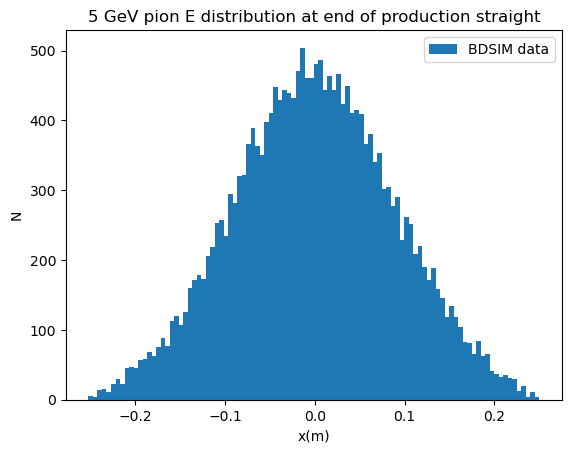

In [4]:
NBins = 100
hist, bins, p = plt.hist(df_with_decay['y'].to_numpy(), bins=NBins, label='BDSIM data')

#plt.hist(bins[:-1], bins, weights=hist, label='random data') #original data
plt.title("5 GeV pion E distribution at end of production straight")
plt.xlabel('x(m)')
plt.ylabel('N')
plt.legend()
plt.show()

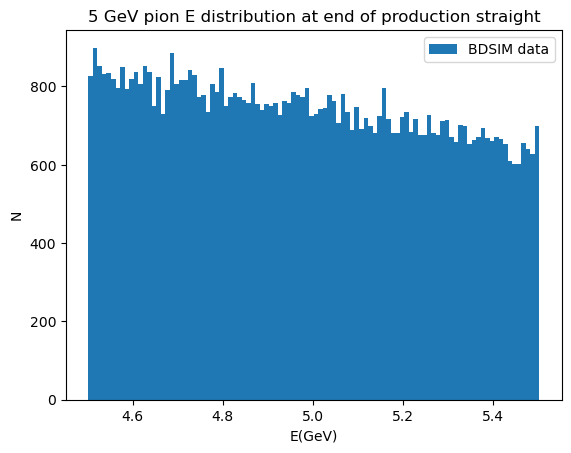

In [5]:
NBins = 100
hist, bins, p = plt.hist(df_start['E'].to_numpy(), bins=NBins, label='BDSIM data')

#plt.hist(bins[:-1], bins, weights=hist, label='random data') #original data
plt.title("5 GeV pion E distribution at end of production straight")
plt.xlabel('E(GeV)')
plt.ylabel('N')
plt.legend()
plt.show()

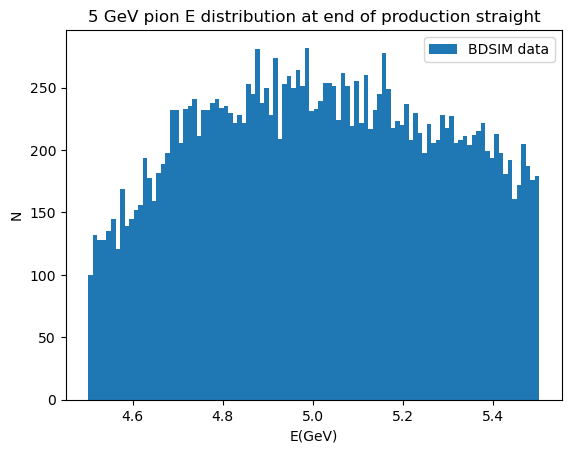

In [6]:
NBins = 100
hist, bins, p = plt.hist(df_with_decay['E'].to_numpy(), bins=NBins, label='BDSIM data')

#plt.hist(bins[:-1], bins, weights=hist, label='random data') #original data
plt.title("5 GeV pion E distribution at end of production straight")
plt.xlabel('E(GeV)')
plt.ylabel('N')
plt.legend()
plt.show()

NameError: name 'hist_to_xy' is not defined

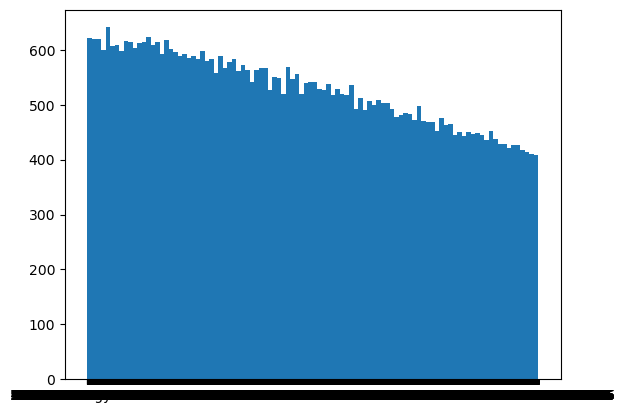

In [ ]:
NBins = 100
hist, bins, p = plt.hist(df_without_decay['E'].to_numpy(), bins=NBins, label='BDSIM data without decay')

x_E, y_N = hist_to_xy(hist, bins)

pars, cov=optimize.curve_fit(lin_func, x_E, y_N)#, p0=guess_p0)

print("lin fit slope : "+str(pars[0])+" intercept : "+str(pars[1]))

fx = np.linspace(x_E[0], x_E[-1], 1000) #x values for fitted function
fy = lin_func(fx, *pars) #calculate fitted function values

#plt.hist(bins[:-1], bins, weights=hist, label='random data') #original data
plt.plot(fx, fy, label='fit') #fitted curve
plt.title("5 GeV pion E distribution at end of production straight")
plt.xlabel('E(GeV)')
plt.ylabel('N')
plt.legend()
plt.show()

lin fit slope : -0.18501315838635124 intercept : 1564.8391541927224


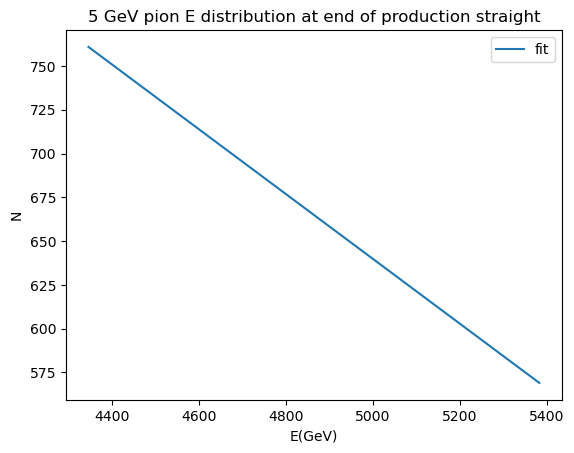

In [19]:
hist_lin = [ 38, 192, 481, 757, 849, 770, 766, 777, 748, 763, 748, 796, 828, 794,
 800, 712, 716, 699, 781, 787, 778, 835, 740, 782, 782, 745, 704, 719,
 772, 770, 746, 752, 748, 788, 705, 734, 717, 683, 681, 698, 685, 711,
 695, 707, 694, 663, 734, 750, 747, 706, 676, 703, 664, 754, 644, 658,
 686, 690, 688, 681, 643, 667, 633, 675, 729, 715, 631, 617, 595, 731,
 672, 615, 604, 611, 636, 631, 684, 671, 711, 633, 613, 636, 626, 596,
 631, 644, 636, 623, 647, 639, 625, 565, 560, 555, 589, 601, 535, 342,
 101,  12]
bins_lin = [4340.09543255, 4350.56975681, 4361.04408107, 4371.51840534, 4381.9927296
, 4392.46705386, 4402.94137812, 4413.41570238, 4423.89002665, 4434.36435091
, 4444.83867517, 4455.31299943, 4465.78732369, 4476.26164795, 4486.73597222
, 4497.21029648, 4507.68462074, 4518.158945 , 4528.63326926, 4539.10759352
, 4549.58191779, 4560.05624205, 4570.53056631, 4581.00489057, 4591.47921483
, 4601.95353909, 4612.42786336, 4622.90218762, 4633.37651188, 4643.85083614
, 4654.3251604, 4664.79948466, 4675.27380893, 4685.74813319, 4696.22245745
, 4706.69678171, 4717.17110597, 4727.64543024, 4738.1197545, 4748.59407876
, 4759.06840302, 4769.54272728, 4780.01705154, 4790.49137581, 4800.96570007
, 4811.44002433, 4821.91434859, 4832.38867285, 4842.86299711, 4853.33732138
, 4863.81164564, 4874.2859699, 4884.76029416, 4895.23461842, 4905.70894268
, 4916.18326695, 4926.65759121, 4937.13191547, 4947.60623973, 4958.08056399
, 4968.55488825, 4979.02921252, 4989.50353678, 4999.97786104, 5010.4521853
, 5020.92650956, 5031.40083383, 5041.87515809, 5052.34948235, 5062.82380661
, 5073.29813087, 5083.77245513, 5094.2467794, 5104.72110366, 5115.19542792
, 5125.66975218, 5136.14407644, 5146.6184007, 5157.09272497, 5167.56704923
, 5178.04137349, 5188.51569775, 5198.99002201, 5209.46434627, 5219.93867054
, 5230.4129948, 5240.88731906, 5251.36164332, 5261.83596758, 5272.31029185
, 5282.78461611, 5293.25894037, 5303.73326463, 5314.20758889, 5324.68191315
, 5335.15623742, 5345.63056168, 5356.10488594, 5366.5792102, 5377.05353446
, 5387.52785872]

x_E_lin, y_N_lin = hist_to_xy(hist_lin, bins_lin)

pars, cov=optimize.curve_fit(lin_func, x_E_lin, y_N_lin)#, p0=guess_p0)

print("lin fit slope : "+str(pars[0])+" intercept : "+str(pars[1]))

fx = np.linspace(x_E_lin[0], x_E_lin[-1], 1000) #x values for fitted function
fy = lin_func(fx, *pars) #calculate fitted function values

#plt.hist(bins[:-1], bins, weights=hist, label='random data') #original data
plt.plot(fx, fy, label='fit') #fitted curve
plt.title("5 GeV pion E distribution at end of production straight")
plt.xlabel('E(GeV)')
plt.ylabel('N')
plt.legend()
plt.show()

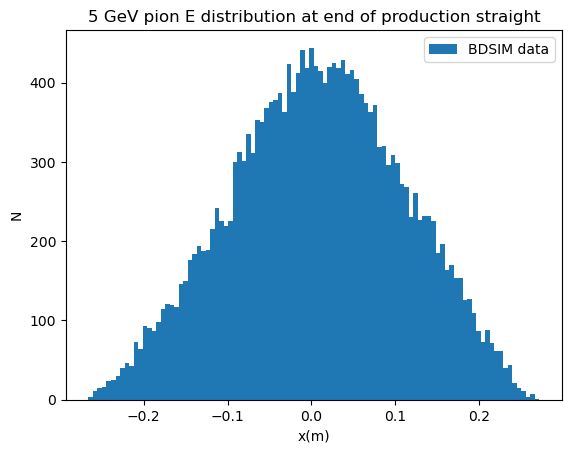

In [13]:
NBins = 100
hist, bins, p = plt.hist(df_with_decay['x'].to_numpy(), bins=NBins, label='BDSIM data')

#plt.hist(bins[:-1], bins, weights=hist, label='random data') #original data
plt.title("5 GeV pion E distribution at end of production straight")
plt.xlabel('x(m)')
plt.ylabel('N')
plt.legend()
plt.show()

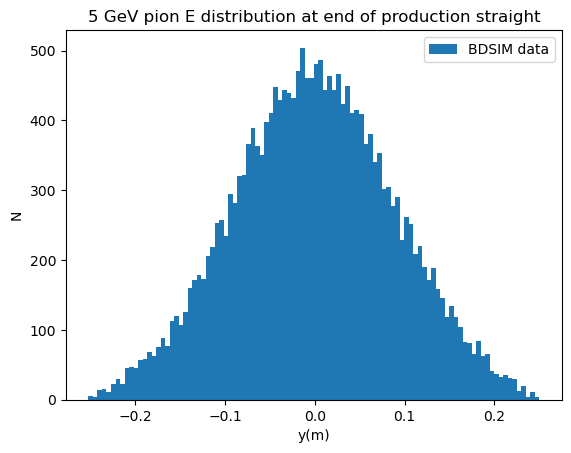

In [14]:
NBins = 100
hist, bins, p = plt.hist(df_with_decay['y'].to_numpy(), bins=NBins, label='BDSIM data')

#plt.hist(bins[:-1], bins, weights=hist, label='random data') #original data
plt.title("5 GeV pion E distribution at end of production straight")
plt.xlabel('y(m)')
plt.ylabel('N')
plt.legend()
plt.show()

In [6]:
filename = "Minerva_munuFlux.dat"
filein = open(filename, "r")            # Open file for reading
inputd = filein.readlines()
inputdata = []

print(inputd[0][0])

#


In [9]:
filename = "Minerva_munuFlux.dat"       #make MINERvA flux's energy bin more fine grain
filein = open(filename, "r")            # Open file for reading
inputd = filein.readlines()
inputdata = []
temp_data_1_line = []

leng = len(inputd)
print("the number of line of the txt file list is : " + str(leng))
run_n = [1,1]
run_event_n = 0
event_n = 0
for i in range(1,leng):
    if inputd[i][0] == "#":
        a=0
    else:
        tokens = inputd[i].split()
        tokens = [float(tokens[0]), float(tokens[1])]
        #print(tokens)
        inputdata.append(tokens)

#print(inputdata)
new_flux = []
bin_mult_num = 5
bin_start = -0.25
bin_end = inputdata[0][0]
start_bin_val = -2.57268e-6
end_bin_val = inputdata[0][1]
dx = (bin_end-bin_start)/bin_mult_num
for j in range(0, bin_mult_num):
    new_flux_bin = [bin_start+dx*j, (start_bin_val*(bin_mult_num-j)+end_bin_val*j)/bin_mult_num]
    new_flux.append(new_flux_bin)
    
for i in range(1,len(inputdata)):
    bin_start = inputdata[i-1][0]
    bin_end = inputdata[i][0]
    start_bin_val = inputdata[i-1][1]
    end_bin_val = inputdata[i][1]
    dx = (bin_end-bin_start)/bin_mult_num
    for j in range(0, bin_mult_num):
        new_flux_bin = [bin_start+dx*j, (start_bin_val*(bin_mult_num-j)+end_bin_val*j)/bin_mult_num]
        new_flux.append(new_flux_bin)
        
#print(new_flux)

the number of line of the txt file list is : 205


In [10]:
def integrate_const_interval(flux) #integrate a 1d func with constant interval with format of {x,y}

    integrate_result = 0;
    leng = len(flux);
    dx = flux[1][0]-flux[0][0];

    int_coeff = np.array([3/8, 7/6, 23/24]);
    integrate_result = integrate_result + int_coeff[0]*(flux[0][1]+flux[leng-1][1])+ int_coeff[1]*(flux[1][1]+flux[leng-2][1])+ int_coeff[2]*(flux[2][1]+flux[leng-3][1]);
    
    for i in range(3,leng-3)
        integrate_result = integrate_result + flux[i][1];

    integrate_result = integrate_result*dx;
    return integrate_result;



SyntaxError: expected ':' (3799569945.py, line 1)

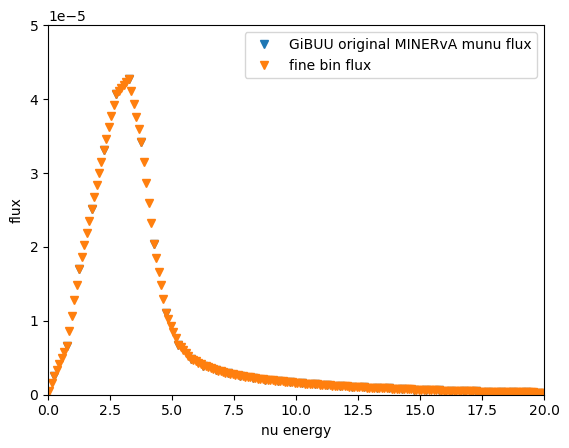

In [11]:
inputdata_plt=[[],[]]
new_flux_plt = [[],[]]
for i in range(0,len(inputdata)):
    inputdata_plt[0].append(inputdata[i][0])
    inputdata_plt[1].append(inputdata[i][1])
    
for i in range(0,len(new_flux)):
    new_flux_plt[0].append(new_flux[i][0])
    new_flux_plt[1].append(new_flux[i][1])

#print(inputdata_plt[0],inputdata_plt[1])
plt.plot(inputdata_plt[0],inputdata_plt[1], label = "GiBUU original MINERvA munu flux", linestyle='None', marker='v')
plt.plot(new_flux_plt[0],new_flux_plt[1], label = "fine bin flux", linestyle='None', marker='v')
plt.xlim(0,20)
plt.ylim(0,5e-5)
plt.xlabel("nu energy")
plt.ylabel("flux")
plt.legend()

plt.show()

In [12]:
file = open('file.txt', 'w')
file.write("Python is awesome!\n") 
file.write("Python is good!") 
file.close()
print(str(round(3.0535700000000007e-08,10)))

3.05e-08


In [15]:
file = open('new_MINERvA_munu_fine_bin.txt', 'w', encoding='ascii')
#file.write(str(0.1)+"	"+str(0)+"\n")
for i in range(3,204):
    file.write(str(round(new_flux[i][0],4))+"	"+str(round(new_flux[i][1],16))+"\n")
file.close()

In [19]:
np.linspace(0,99.9,201)

array([ 0.    ,  0.4995,  0.999 ,  1.4985,  1.998 ,  2.4975,  2.997 ,
        3.4965,  3.996 ,  4.4955,  4.995 ,  5.4945,  5.994 ,  6.4935,
        6.993 ,  7.4925,  7.992 ,  8.4915,  8.991 ,  9.4905,  9.99  ,
       10.4895, 10.989 , 11.4885, 11.988 , 12.4875, 12.987 , 13.4865,
       13.986 , 14.4855, 14.985 , 15.4845, 15.984 , 16.4835, 16.983 ,
       17.4825, 17.982 , 18.4815, 18.981 , 19.4805, 19.98  , 20.4795,
       20.979 , 21.4785, 21.978 , 22.4775, 22.977 , 23.4765, 23.976 ,
       24.4755, 24.975 , 25.4745, 25.974 , 26.4735, 26.973 , 27.4725,
       27.972 , 28.4715, 28.971 , 29.4705, 29.97  , 30.4695, 30.969 ,
       31.4685, 31.968 , 32.4675, 32.967 , 33.4665, 33.966 , 34.4655,
       34.965 , 35.4645, 35.964 , 36.4635, 36.963 , 37.4625, 37.962 ,
       38.4615, 38.961 , 39.4605, 39.96  , 40.4595, 40.959 , 41.4585,
       41.958 , 42.4575, 42.957 , 43.4565, 43.956 , 44.4555, 44.955 ,
       45.4545, 45.954 , 46.4535, 46.953 , 47.4525, 47.952 , 48.4515,
       48.951 , 49.4

In [4]:
file = open('flat_E_test_100GeV.txt', 'w', encoding='ascii')
#file.write(str(0.1)+"	"+str(0)+"\n")
flat_E_lst = np.linspace(0,98,201)
for i in range(0,201):
    file.write(str(round(flat_E_lst[i],4))+"	"+"1"+"\n")
file.close()

In [4]:
#xsec plot

In [4]:
'''
cluster Nu_e high stat run

xsec for outana9
xsec of E3 mode : QE is 7.79544e-41 cm^{2}
xsec of E3 mode : RES is 3.48118e-41 cm^{2}
xsec of E3 mode : DIS is 0 cm^{2}
xsec of E3 mode : 2p2h is 2.23313e-41 cm^{2}
total xsec of E3 is 1.35098e-40 cm^{2}
xsec of E4 mode : QE is 2.12268e-40 cm^{2}
xsec of E4 mode : RES is 1.35818e-40 cm^{2}
xsec of E4 mode : DIS is 3.28708e-45 cm^{2}
xsec of E4 mode : 2p2h is 6.78136e-41 cm^{2}
total xsec of E4 is 4.15903e-40 cm^{2}
xsec of E5 mode : QE is 3.46664e-40 cm^{2}
xsec of E5 mode : RES is 2.49231e-40 cm^{2}
xsec of E5 mode : DIS is 1.20256e-43 cm^{2}
xsec of E5 mode : 2p2h is 1.15718e-40 cm^{2}
total xsec of E5 is 7.11734e-40 cm^{2}
xsec of E6 mode : QE is 4.56572e-40 cm^{2}
xsec of E6 mode : RES is 3.53284e-40 cm^{2}
xsec of E6 mode : DIS is 5.96481e-43 cm^{2}
xsec of E6 mode : 2p2h is 1.58279e-40 cm^{2}
total xsec of E6 is 9.68731e-40 cm^{2}
xsec of E7 mode : QE is 5.42765e-40 cm^{2}
xsec of E7 mode : RES is 4.36573e-40 cm^{2}
xsec of E7 mode : DIS is 1.51617e-42 cm^{2}
xsec of E7 mode : 2p2h is 1.92607e-40 cm^{2}
total xsec of E7 is 1.17346e-39 cm^{2}

xsec for outana7
xsec of E3 mode : QE is 1.31631e-43 cm^{2}
xsec of E3 mode : RES is 1.81238e-41 cm^{2}
xsec of E3 mode : DIS is 0 cm^{2}
xsec of E3 mode : 2p2h is 2.15457e-44 cm^{2}
total xsec of E3 is 1.8277e-41 cm^{2}
xsec of E4 mode : QE is 7.63211e-43 cm^{2}
xsec of E4 mode : RES is 9.40583e-41 cm^{2}
xsec of E4 mode : DIS is 2.58469e-44 cm^{2}
xsec of E4 mode : 2p2h is 1.41499e-43 cm^{2}
total xsec of E4 is 9.49889e-41 cm^{2}
xsec of E5 mode : QE is 2.31351e-42 cm^{2}
xsec of E5 mode : RES is 2.1006e-40 cm^{2}
xsec of E5 mode : DIS is 1.31614e-42 cm^{2}
xsec of E5 mode : 2p2h is 4.21899e-43 cm^{2}
total xsec of E5 is 2.14112e-40 cm^{2}
xsec of E6 mode : QE is 4.29804e-42 cm^{2}
xsec of E6 mode : RES is 3.38898e-40 cm^{2}
xsec of E6 mode : DIS is 7.21854e-42 cm^{2}
xsec of E6 mode : 2p2h is 8.1953e-43 cm^{2}
total xsec of E6 is 3.51234e-40 cm^{2}
xsec of E7 mode : QE is 5.9544e-42 cm^{2}
xsec of E7 mode : RES is 4.56635e-40 cm^{2}
xsec of E7 mode : DIS is 1.94454e-41 cm^{2}
xsec of E7 mode : 2p2h is 1.2431e-42 cm^{2}
total xsec of E7 is 4.83277e-40 cm^{2}

cluster Nu_mu high stat run


xsec for outana9
xsec of E3 mode : QE is 1.2975e-40 cm^{2}
xsec of E3 mode : RES is 6.29751e-41 cm^{2}
xsec of E3 mode : DIS is 0 cm^{2}
xsec of E3 mode : 2p2h is 3.86329e-41 cm^{2}
total xsec of E3 is 2.31358e-40 cm^{2}
xsec of E4 mode : QE is 3.37834e-40 cm^{2}
xsec of E4 mode : RES is 2.28426e-40 cm^{2}
xsec of E4 mode : DIS is 1.66635e-44 cm^{2}
xsec of E4 mode : 2p2h is 1.10888e-40 cm^{2}
total xsec of E4 is 6.77164e-40 cm^{2}
xsec of E5 mode : QE is 4.9592e-40 cm^{2}
xsec of E5 mode : RES is 3.73453e-40 cm^{2}
xsec of E5 mode : DIS is 3.79101e-43 cm^{2}
xsec of E5 mode : 2p2h is 1.7023e-40 cm^{2}
total xsec of E5 is 1.03998e-39 cm^{2}
xsec of E6 mode : QE is 5.98896e-40 cm^{2}
xsec of E6 mode : RES is 4.74343e-40 cm^{2}
xsec of E6 mode : DIS is 1.38963e-42 cm^{2}
xsec of E6 mode : 2p2h is 2.12657e-40 cm^{2}
total xsec of E6 is 1.28729e-39 cm^{2}
xsec of E7 mode : QE is 6.69521e-40 cm^{2}
xsec of E7 mode : RES is 5.53899e-40 cm^{2}
xsec of E7 mode : DIS is 3.2676e-42 cm^{2}
xsec of E7 mode : 2p2h is 2.44514e-40 cm^{2}
total xsec of E7 is 1.4712e-39 cm^{2}

xsec for outana7
xsec of E3 mode : QE is 2.48699e-43 cm^{2}
xsec of E3 mode : RES is 3.36777e-41 cm^{2}
xsec of E3 mode : DIS is 0 cm^{2}
xsec of E3 mode : 2p2h is 4.05872e-44 cm^{2}
total xsec of E3 is 3.3967e-41 cm^{2}
xsec of E4 mode : QE is 1.81889e-42 cm^{2}
xsec of E4 mode : RES is 1.74436e-40 cm^{2}
xsec of E4 mode : DIS is 1.44701e-43 cm^{2}
xsec of E4 mode : 2p2h is 3.04758e-43 cm^{2}
total xsec of E4 is 1.76704e-40 cm^{2}
xsec of E5 mode : QE is 4.20199e-42 cm^{2}
xsec of E5 mode : RES is 3.48144e-40 cm^{2}
xsec of E5 mode : DIS is 4.14315e-42 cm^{2}
xsec of E5 mode : 2p2h is 8.04284e-43 cm^{2}
total xsec of E5 is 3.57294e-40 cm^{2}
xsec of E6 mode : QE is 6.59727e-42 cm^{2}
xsec of E6 mode : RES is 4.93926e-40 cm^{2}
xsec of E6 mode : DIS is 1.71424e-41 cm^{2}
xsec of E6 mode : 2p2h is 1.33348e-42 cm^{2}
total xsec of E6 is 5.18999e-40 cm^{2}
xsec of E7 mode : QE is 9.00905e-42 cm^{2}
xsec of E7 mode : RES is 6.27575e-40 cm^{2}
xsec of E7 mode : DIS is 4.20992e-41 cm^{2}
xsec of E7 mode : 2p2h is 1.8923e-42 cm^{2}
total xsec of E7 is 6.80576e-40 cm^{2}
'''

'''
piflash
bin # : 120
avg E of #nu_{mu} from 3 GeV #pi flash is : 0.812767 GeV
bin # : 120
avg E of #nu_{mu} from 4 GeV #pi flash is : 1.00311 GeV
bin # : 120
avg E of #nu_{mu} from 5 GeV #pi flash is : 1.19734 GeV
bin # : 120
avg E of #nu_{mu} from 6 GeV #pi flash is : 1.38915 GeV
bin # : 120
avg E of #nu_{mu} from 7 GeV #pi flash is : 1.58844 GeV

musig
numu
bin # : 120
avg E of #nu_{mu} from 3 GeV #pi flash is : 1.34543 GeV
bin # : 120
avg E of #nu_{mu} from 4 GeV #pi flash is : 1.72122 GeV
bin # : 120
avg E of #nu_{mu} from 5 GeV #pi flash is : 2.04772 GeV
bin # : 120
avg E of #nu_{mu} from 6 GeV #pi flash is : 2.32939 GeV
bin # : 120
avg E of #nu_{mu} from 7 GeV #pi flash is : 2.61806 GeV

nue
bin # : 120
avg E of #nu_{mu} from 3 GeV #pi flash is : 1.1625 GeV
bin # : 120
avg E of #nu_{mu} from 4 GeV #pi flash is : 1.48087 GeV
bin # : 120
avg E of #nu_{mu} from 5 GeV #pi flash is : 1.73456 GeV
bin # : 120
avg E of #nu_{mu} from 6 GeV #pi flash is : 1.9923 GeV
bin # : 120
avg E of #nu_{mu} from 7 GeV #pi flash is : 2.23415 GeV


'''
pi_E_lst = [3,4,5,6,7]
musig_numu_E_lst = [1.34543,1.72122,2.04772,2.32939,2.61806]
musig_nue_E_lst = [1.1625,1.48087,1.73456,1.9923,2.23415]

nu_e_outana7_xsec_lst = [1.8277e-41, 9.49889e-41, 2.14112e-40, 3.51234e-40, 4.83277e-40]
nu_e_outana7_QE_xsec_lst = [1.31631e-43, 7.63211e-43, 2.31351e-42, 4.29804e-42, 5.9544e-42]
nu_e_outana7_RES_xsec_lst = [1.81238e-41, 9.40583e-41, 2.1006e-40, 3.38898e-40, 4.56635e-40]
nu_e_outana7_DIS_xsec_lst = [0, 2.58469e-44, 1.31614e-42, 7.21854e-42, 1.94454e-41]
nu_e_outana7_2p2h_xsec_lst = [2.15457e-44, 1.41499e-43, 4.21899e-43, 8.1953e-43, 1.2431e-42]

nu_e_outana9_xsec_lst = [1.35098e-40, 4.15903e-40, 7.11734e-40, 9.68731e-40, 1.17346e-39]
nu_e_outana9_QE_xsec_lst = [7.79544e-41, 2.12268e-40, 3.46664e-40, 4.56572e-40, 5.42765e-40]
nu_e_outana9_RES_xsec_lst = [3.48118e-41, 1.35818e-40, 2.49231e-40, 3.53284e-40, 4.36573e-40]
nu_e_outana9_DIS_xsec_lst = [0, 3.28708e-45, 1.20256e-43, 5.96481e-43, 1.51617e-42]
nu_e_outana9_2p2h_xsec_lst = [2.23313e-41, 6.78136e-41, 1.15718e-40, 1.58279e-40, 1.92607e-40]

nu_mu_outana7_xsec_lst = [3.3967e-41, 1.76704e-40, 3.57294e-40, 5.18999e-40, 6.80576e-40]
nu_mu_outana7_QE_xsec_lst = [2.48699e-43, 1.81889e-42, 4.20199e-42, 6.59727e-42, 9.00905e-42]
nu_mu_outana7_RES_xsec_lst = [3.36777e-41, 1.74436e-40, 3.48144e-40, 4.93926e-40, 6.27575e-40]
nu_mu_outana7_DIS_xsec_lst = [0, 1.44701e-43, 4.14315e-42, 1.71424e-41, 4.20992e-41]
nu_mu_outana7_2p2h_xsec_lst = [4.05872e-44, 3.04758e-43, 8.04284e-43, 1.33348e-42, 1.8923e-42]

nu_mu_outana9_xsec_lst = [2.31358e-40, 6.77164e-40, 1.03998e-39, 1.28729e-39, 1.4712e-39]
nu_mu_outana9_QE_xsec_lst = [1.2975e-40, 3.37834e-40, 4.9592e-40, 5.98896e-40, 6.69521e-40]
nu_mu_outana9_RES_xsec_lst = [6.29751e-41, 2.28426e-40, 3.73453e-40, 4.74343e-40, 5.53899e-40]
nu_mu_outana9_DIS_xsec_lst = [0, 1.66635e-44, 3.79101e-43, 1.38963e-42, 3.2676e-42]
nu_mu_outana9_2p2h_xsec_lst = [3.86329e-41, 1.10888e-40, 1.7023e-40, 2.12657e-40, 2.44514e-40]


nu_antimu_outana7_xsec_lst = [7.17056e-40, 1.574389e-39, 2.217253e-39, 2.813908e-39, 3.437880e-39]


nu_antimu_outana9_xsec_lst = [8.95693e-40, 1.131608e-39, 1.289952e-39 , 1.404566e-39, 1.503224e-39]



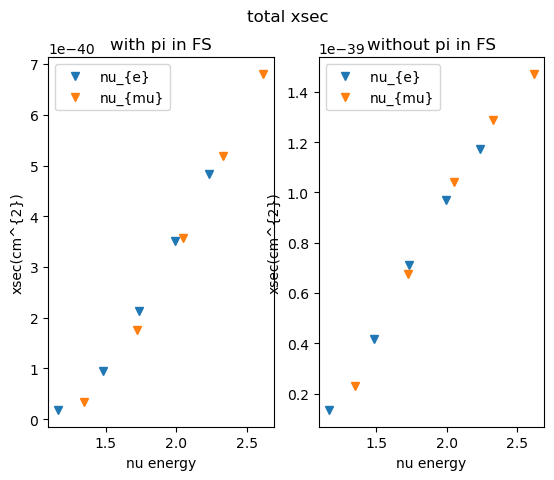

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('total xsec')

plt.xlabel('pion energy')
plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, nu_e_outana7_xsec_lst, linestyle='None', label = 'nu_{e}', marker='v')
ax2.plot(musig_nue_E_lst, nu_e_outana9_xsec_lst, linestyle='None', label = 'nu_{e} ', marker='v')
ax1.plot(musig_numu_E_lst, nu_mu_outana7_xsec_lst, linestyle='None', label = 'nu_{mu}', marker='v')
ax2.plot(musig_numu_E_lst, nu_mu_outana9_xsec_lst, linestyle='None', label = 'nu_{mu}', marker='v')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec(cm^{2})')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

plt.show()

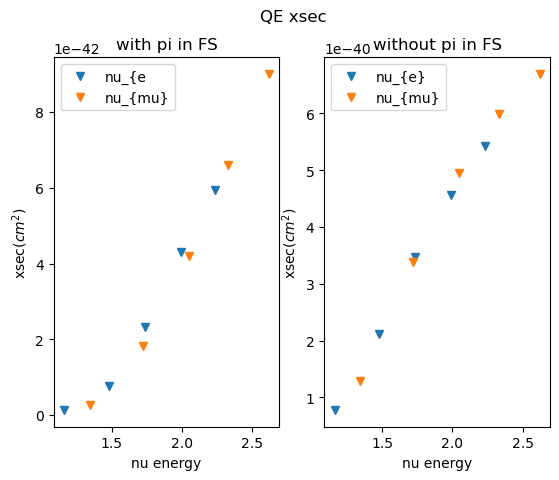

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('QE xsec')

plt.xlabel('pion energy')
plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, nu_e_outana7_QE_xsec_lst, linestyle='None', label = 'nu_{e', marker='v')
ax2.plot(musig_nue_E_lst, nu_e_outana9_QE_xsec_lst, linestyle='None', label = 'nu_{e}', marker='v')
ax1.plot(musig_numu_E_lst, nu_mu_outana7_QE_xsec_lst, linestyle='None', label = 'nu_{mu}', marker='v')
ax2.plot(musig_numu_E_lst, nu_mu_outana9_QE_xsec_lst, linestyle='None', label = 'nu_{mu}', marker='v')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy', ylabel='xsec($cm^{2}$)')

ax1.legend()
ax2.legend()

plt.show()

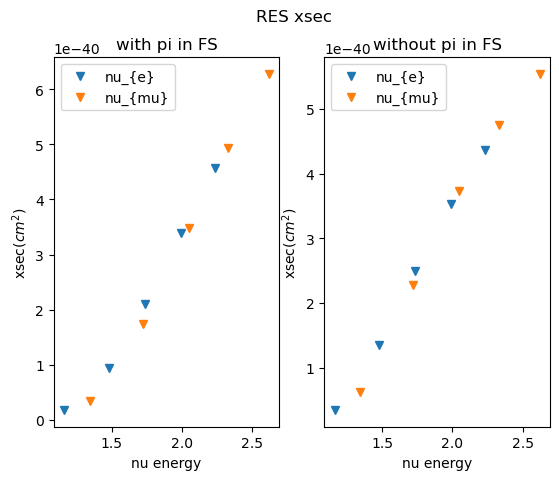

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('RES xsec')

plt.xlabel('pion energy')
plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, nu_e_outana7_RES_xsec_lst, linestyle='None', label = 'nu_{e}', marker='v')
ax2.plot(musig_nue_E_lst, nu_e_outana9_RES_xsec_lst, linestyle='None', label = 'nu_{e}', marker='v')
ax1.plot(musig_numu_E_lst, nu_mu_outana7_RES_xsec_lst, linestyle='None', label = 'nu_{mu}', marker='v')
ax2.plot(musig_numu_E_lst, nu_mu_outana9_RES_xsec_lst, linestyle='None', label = 'nu_{mu}', marker='v')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy', ylabel='xsec($cm^{2}$)')

ax1.legend()
ax2.legend()

plt.show()

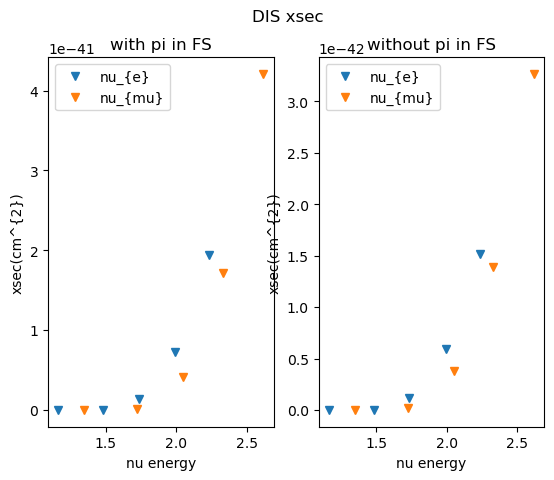

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('DIS xsec')

plt.xlabel('pion energy')
plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, nu_e_outana7_DIS_xsec_lst, linestyle='None', label = 'nu_{e}', marker='v')
ax2.plot(musig_nue_E_lst, nu_e_outana9_DIS_xsec_lst, linestyle='None', label = 'nu_{e}', marker='v')
ax1.plot(musig_numu_E_lst, nu_mu_outana7_DIS_xsec_lst, linestyle='None', label = 'nu_{mu}', marker='v')
ax2.plot(musig_numu_E_lst, nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = 'nu_{mu}', marker='v')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec(cm^{2})')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

plt.show()

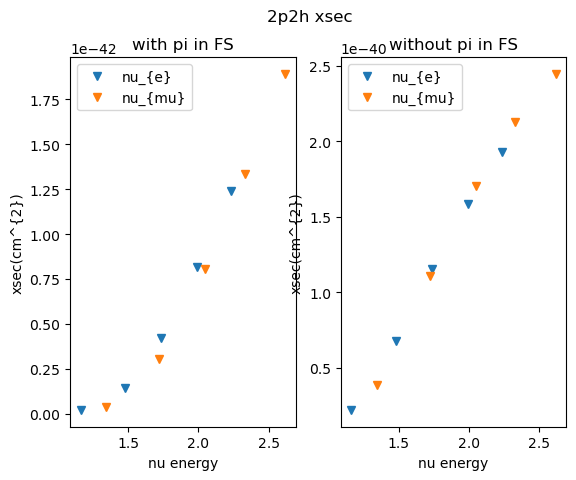

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('2p2h xsec')

plt.xlabel('pion energy')
plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, nu_e_outana7_2p2h_xsec_lst, linestyle='None', label = 'nu_{e}', marker='v')
ax2.plot(musig_nue_E_lst, nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = 'nu_{e}', marker='v')
ax1.plot(musig_numu_E_lst, nu_mu_outana7_2p2h_xsec_lst, linestyle='None', label = 'nu_{mu}', marker='v')
ax2.plot(musig_numu_E_lst, nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = 'nu_{mu}', marker='v')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec(cm^{2})')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

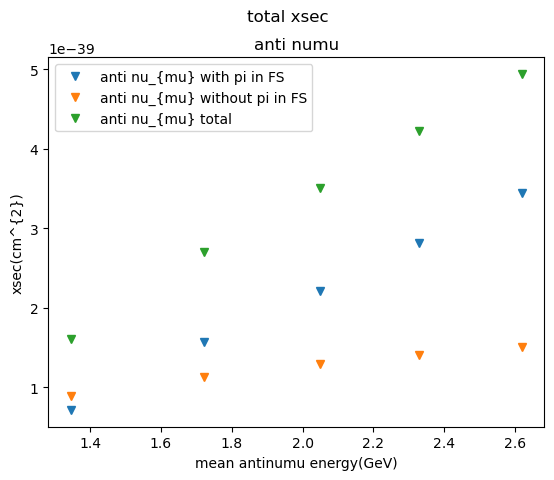

In [10]:
fig, (ax1) = plt.subplots(1, 1)
fig.suptitle('total xsec')

plt.xlabel('pion energy')
plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_numu_E_lst, nu_antimu_outana7_xsec_lst, linestyle='None', label = 'anti nu_{mu} with pi in FS', marker='v')

ax1.plot(musig_numu_E_lst, nu_antimu_outana9_xsec_lst, linestyle='None', label = 'anti nu_{mu} without pi in FS', marker='v')

total_xsec = np.zeros(5)
for i in range(0,5):
    total_xsec[i] = nu_antimu_outana7_xsec_lst[i]+nu_antimu_outana9_xsec_lst[i]

ax1.plot(musig_numu_E_lst, total_xsec, linestyle='None', label = 'anti nu_{mu} total', marker='v')


ax1.set_title('anti numu')

ax1.set(xlabel='mean antinumu energy(GeV)', ylabel='xsec(cm^{2})')


ax1.legend()


plt.show()

In [11]:
#xsec comparison for E5 nue flux nue and nu_mu flavour
"""

here they are E5 nue -> numu


outana9
QE : 3.4815e-40 cm^{2}
RES : 2.44486e-40 cm^{2}
DIS : 1.16513e-43 cm^{2}
2p2h : 1.16206e-40 cm^{2}

ouana7
QE : 2.46315e-42 cm^{2}
RES : 2.06728e-40 cm^{2}
DIS : 1.28139e-42 cm^{2}
2p2h : 4.21327e-43 cm^{2}

just nue

outana9
xsec of E5 mode : QE is 3.46664e-40 cm^{2}
xsec of E5 mode : RES is 2.49231e-40 cm^{2}
xsec of E5 mode : DIS is 1.20256e-43 cm^{2}
xsec of E5 mode : 2p2h is 1.15718e-40 cm^{2}
total xsec of E5 is 7.11734e-40 cm^{2}

ouana7
xsec of E5 mode : QE is 2.31351e-42 cm^{2}
xsec of E5 mode : RES is 2.1006e-40 cm^{2}
xsec of E5 mode : DIS is 1.31614e-42 cm^{2}
xsec of E5 mode : 2p2h is 4.21899e-43 cm^{2}
total xsec of E5 is 2.14112e-40 cm^{2}
"""

'\n\nhere they are E5 nue -> numu\n\n\noutana9\nQE : 3.4815e-40 cm^{2}\nRES : 2.44486e-40 cm^{2}\nDIS : 1.16513e-43 cm^{2}\n2p2h : 1.16206e-40 cm^{2}\n\nouana7\nQE : 2.46315e-42 cm^{2}\nRES : 2.06728e-40 cm^{2}\nDIS : 1.28139e-42 cm^{2}\n2p2h : 4.21327e-43 cm^{2}\n\njust nue\n\noutana9\nxsec of E5 mode : QE is 3.46664e-40 cm^{2}\nxsec of E5 mode : RES is 2.49231e-40 cm^{2}\nxsec of E5 mode : DIS is 1.20256e-43 cm^{2}\nxsec of E5 mode : 2p2h is 1.15718e-40 cm^{2}\ntotal xsec of E5 is 7.11734e-40 cm^{2}\n\nouana7\nxsec of E5 mode : QE is 2.31351e-42 cm^{2}\nxsec of E5 mode : RES is 2.1006e-40 cm^{2}\nxsec of E5 mode : DIS is 1.31614e-42 cm^{2}\nxsec of E5 mode : 2p2h is 4.21899e-43 cm^{2}\ntotal xsec of E5 is 2.14112e-40 cm^{2}\n'

In [12]:
ch_lst = ["QE", "RES", "DIS", "2p2h"]
E5_nue_numu_outana9 = [3.4815e-40, 2.44486e-40, 1.16513e-43, 1.16206e-40]
E5_nue_numu_outana7 = [2.46315e-42, 2.06728e-40, 1.28139e-42, 4.21327e-43]

E5_nue_outana9 = [3.46664e-40, 2.49231e-40, 1.20256e-43, 1.15718e-40]
E5_nue_outana7 = [2.31351e-42, 2.1006e-40, 1.31614e-42, 4.21899e-43]

numu_large_outana9 = 0
numu_large_outana7 = 0

for i in range(0, len(E5_nue_numu_outana9)):
    
    numu_large_outana9 = (E5_nue_numu_outana9[i]-E5_nue_outana9[i])/E5_nue_numu_outana9[i]
    numu_large_outana7 = (E5_nue_numu_outana7[i]-E5_nue_outana7[i])/E5_nue_numu_outana7[i]
    numu_large_outana9 = numu_large_outana9*100
    numu_large_outana7 = numu_large_outana7*100
    
    print("outana 9(without pi in FS) "+ch_lst[i]+" nu_mu xsec is "+str(numu_large_outana9)+" % larger than nue")
    print("outana 7(with pi in FS) "+ch_lst[i]+" nu_mu xsec is "+str(numu_large_outana7)+" % larger than nue")
    
    

outana 9(without pi in FS) QE nu_mu xsec is 0.42682751687490594 % larger than nue
outana 7(with pi in FS) QE nu_mu xsec is 6.0751476767553685 % larger than nue
outana 9(without pi in FS) RES nu_mu xsec is -1.9408064265438632 % larger than nue
outana 7(with pi in FS) RES nu_mu xsec is -1.6117797298866088 % larger than nue
outana 9(without pi in FS) DIS nu_mu xsec is -3.2125170581823355 % larger than nue
outana 7(with pi in FS) DIS nu_mu xsec is -2.7118987973996966 % larger than nue
outana 9(without pi in FS) 2p2h nu_mu xsec is 0.4199438927421866 % larger than nue
outana 7(with pi in FS) 2p2h nu_mu xsec is -0.13576153439014615 % larger than nue


In [13]:
(2.46315e-42-2.31351e-42)/2.46315e-42*100

6.0751476767553685

In [14]:
'''
real sim

direct perweight calc total xsec : 2.00796e-39 cm^{2}
direct perweight calc xsec for mode : QE is 3.25443e-41 cm^{2}
direct perweight calc xsec for mode : RES is 1.51543e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 1.77499e-40 cm^{2}
direct perweight calc xsec for mode : 2p2h is 7.09126e-42 cm^{2}

imitate

direct perweight calc total xsec : 2.00181e-39 cm^{2}
direct perweight calc xsec for mode : QE is 3.28942e-41 cm^{2}
direct perweight calc xsec for mode : RES is 1.51086e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 1.77017e-40 cm^{2}
direct perweight calc xsec for mode : 2p2h is 7.05918e-42 cm^{2}
'''
#E7 nue outana7
real_sim = [2.00796e-39, 3.25443e-41, 1.51543e-39, 1.77499e-40, 7.09126e-42]
imitate_sim = [2.00181e-39, 3.28942e-41, 1.51086e-39, 1.77017e-40, 7.05918e-42]
name_lst = ["total", "QE", "RES", "DIS", "2p2h"]

for i in range(0,5):
    print(name_lst[i]+" real : "+str(real_sim[i])+"cm^{2} "+" imitate : "+str(imitate_sim[i])+"cm^{2} , diff : "
          +str(100*np.abs(real_sim[i]-imitate_sim[i])/real_sim[i])+"%")

total real : 2.00796e-39cm^{2}  imitate : 2.00181e-39cm^{2} , diff : 0.30628100161357097%
QE real : 3.25443e-41cm^{2}  imitate : 3.28942e-41cm^{2} , diff : 1.075149872635135%
RES real : 1.51543e-39cm^{2}  imitate : 1.51086e-39cm^{2} , diff : 0.30156457243158225%
DIS real : 1.77499e-40cm^{2}  imitate : 1.77017e-40cm^{2} , diff : 0.2715508256384489%
2p2h real : 7.09126e-42cm^{2}  imitate : 7.05918e-42cm^{2} , diff : 0.45238786901057426%


In [15]:
'''
E7 outana9

real sim

direct perweight calc total xsec : 6.27358e-39 cm^{2}
direct perweight calc xsec for mode : QE is 3.29458e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.60246e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 5.20043e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 1.26741e-39 cm^{2}


imitate

direct perweight calc total xsec : 6.1869e-39 cm^{2}
direct perweight calc xsec for mode : QE is 3.27683e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.59608e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 5.17062e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 1.26227e-39 cm^{2}
'''
#E7 nue outana9
real_sim = [6.27358e-39, 3.29458e-39, 1.60246e-39, 5.20043e-41, 1.26741e-39]
imitate_sim = [6.1869e-39, 3.27683e-39, 1.59608e-39, 5.17062e-41, 1.26227e-39]
name_lst = ["total", "QE", "RES", "DIS", "2p2h"]

for i in range(0,5):
    print(name_lst[i]+" real : "+str(real_sim[i])+"cm^{2} "+" imitate : "+str(imitate_sim[i])+"cm^{2} , diff : "
          +str(100*np.abs(real_sim[i]-imitate_sim[i])/real_sim[i])+"%")

total real : 6.27358e-39cm^{2}  imitate : 6.1869e-39cm^{2} , diff : 1.381667245814997%
QE real : 3.29458e-39cm^{2}  imitate : 3.27683e-39cm^{2} , diff : 0.5387636663853862%
RES real : 1.60246e-39cm^{2}  imitate : 1.59608e-39cm^{2} , diff : 0.398137863035588%
DIS real : 5.20043e-41cm^{2}  imitate : 5.17062e-41cm^{2} , diff : 0.5732218297332954%
2p2h real : 1.26741e-39cm^{2}  imitate : 1.26227e-39cm^{2} , diff : 0.4055514790004855%


In [16]:
'''
E6 nue
real sim

direct perweight calc total xsec : 1.58592e-39 cm^{2}
direct perweight calc xsec for mode : QE is 3.20757e-41 cm^{2}
direct perweight calc xsec for mode : RES is 1.42709e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 1.19919e-40 cm^{2}
direct perweight calc xsec for mode : 2p2h is 6.83993e-42 cm^{2}


imitate
direct perweight calc total xsec : 1.58103e-39 cm^{2}
direct perweight calc xsec for mode : QE is 3.21354e-41 cm^{2}
direct perweight calc xsec for mode : RES is 1.42233e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 1.19752e-40 cm^{2}
direct perweight calc xsec for mode : 2p2h is 6.81192e-42 cm^{2}
'''
#E6 nue outana7
real_sim = [1.58592e-39, 3.20757e-41, 1.42709e-39, 1.19919e-40, 6.83993e-42]
imitate_sim = [1.58103e-39, 3.21354e-41, 1.42233e-39, 1.19752e-40, 6.81192e-42]
name_lst = ["total", "QE", "RES", "DIS", "2p2h"]

for i in range(0,5):
    print(name_lst[i]+" real : "+str(real_sim[i])+"cm^{2} "+" imitate : "+str(imitate_sim[i])+"cm^{2} , diff : "
          +str(100*np.abs(real_sim[i]-imitate_sim[i])/real_sim[i])+"%")

total real : 1.58592e-39cm^{2}  imitate : 1.58103e-39cm^{2} , diff : 0.30833837772396283%
QE real : 3.20757e-41cm^{2}  imitate : 3.21354e-41cm^{2} , diff : 0.1861222046596057%
RES real : 1.42709e-39cm^{2}  imitate : 1.42233e-39cm^{2} , diff : 0.33354588708490107%
DIS real : 1.19919e-40cm^{2}  imitate : 1.19752e-40cm^{2} , diff : 0.13926066761730307%
2p2h real : 6.83993e-42cm^{2}  imitate : 6.81192e-42cm^{2} , diff : 0.4095071148388831%


In [17]:
'''
outana9

real sim

direct perweight calc total xsec : 6.18218e-39 cm^{2}
direct perweight calc xsec for mode : QE is 3.30887e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.55896e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 3.54269e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 1.27893e-39 cm^{2}


imitate

direct perweight calc total xsec : 6.15787e-39 cm^{2}
direct perweight calc xsec for mode : QE is 3.29706e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.55205e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 3.52545e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 1.27351e-39 cm^{2}
'''
#E6 nue outana9
real_sim = [1.58592e-39, 3.20757e-41, 1.42709e-39, 1.19919e-40, 6.83993e-42]
imitate_sim = [1.58103e-39, 3.21354e-41, 1.42233e-39, 1.19752e-40, 6.81192e-42]
name_lst = ["total", "QE", "RES", "DIS", "2p2h"]

for i in range(0,5):
    print(name_lst[i]+" real : "+str(real_sim[i])+"cm^{2} "+" imitate : "+str(imitate_sim[i])+"cm^{2} , diff : "
          +str(100*np.abs(real_sim[i]-imitate_sim[i])/real_sim[i])+"%")

total real : 1.58592e-39cm^{2}  imitate : 1.58103e-39cm^{2} , diff : 0.30833837772396283%
QE real : 3.20757e-41cm^{2}  imitate : 3.21354e-41cm^{2} , diff : 0.1861222046596057%
RES real : 1.42709e-39cm^{2}  imitate : 1.42233e-39cm^{2} , diff : 0.33354588708490107%
DIS real : 1.19919e-40cm^{2}  imitate : 1.19752e-40cm^{2} , diff : 0.13926066761730307%
2p2h real : 6.83993e-42cm^{2}  imitate : 6.81192e-42cm^{2} , diff : 0.4095071148388831%


In [18]:
'''
E5 nue
real sim

direct perweight calc total xsec : 1.41285e-39 cm^{2}
direct perweight calc xsec for mode : QE is 3.04586e-41 cm^{2}
direct perweight calc xsec for mode : RES is 1.30897e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 6.69713e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 6.44999e-42 cm^{2}


imitate

direct perweight calc total xsec : 1.40916e-39 cm^{2}
direct perweight calc xsec for mode : QE is 3.07373e-41 cm^{2}
direct perweight calc xsec for mode : RES is 1.30521e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 6.67708e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 6.43508e-42 cm^{2}
'''
#E5 nue outana7
real_sim = [1.41285e-39, 3.04586e-41, 1.30897e-39, 6.69713e-41, 6.44999e-42]
imitate_sim = [1.40916e-39, 3.07373e-41, 1.30521e-39, 6.67708e-41, 6.43508e-42]
name_lst = ["total", "QE", "RES", "DIS", "2p2h"]

for i in range(0,5):
    print(name_lst[i]+" real : "+str(real_sim[i])+"cm^{2} "+" imitate : "+str(imitate_sim[i])+"cm^{2} , diff : "
          +str(100*np.abs(real_sim[i]-imitate_sim[i])/real_sim[i])+"%")

total real : 1.41285e-39cm^{2}  imitate : 1.40916e-39cm^{2} , diff : 0.2611742223165881%
QE real : 3.04586e-41cm^{2}  imitate : 3.07373e-41cm^{2} , diff : 0.9150125087824066%
RES real : 1.30897e-39cm^{2}  imitate : 1.30521e-39cm^{2} , diff : 0.2872487528361998%
DIS real : 6.69713e-41cm^{2}  imitate : 6.67708e-41cm^{2} , diff : 0.29938197406948813%
2p2h real : 6.44999e-42cm^{2}  imitate : 6.43508e-42cm^{2} , diff : 0.2311631490901551%


In [19]:
'''
E5 nue
outana9

real sim

direct perweight calc total xsec : 6.13001e-39 cm^{2}
direct perweight calc xsec for mode : QE is 3.32462e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.49615e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 1.98463e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 1.28939e-39 cm^{2}

imitate

direct perweight calc total xsec : 6.11032e-39 cm^{2}
direct perweight calc xsec for mode : QE is 3.31578e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.4904e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 1.97517e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 1.28438e-39 cm^{2}
'''
#E5 nue outana9
real_sim = [6.13001e-39, 3.32462e-39, 1.49615e-39, 1.98463e-41, 1.28939e-39]
imitate_sim = [6.11032e-39, 3.31578e-39, 1.4904e-39, 1.97517e-41, 1.28438e-39]
name_lst = ["total", "QE", "RES", "DIS", "2p2h"]

for i in range(0,5):
    print(name_lst[i]+" real : "+str(real_sim[i])+"cm^{2} "+" imitate : "+str(imitate_sim[i])+"cm^{2} , diff : "
          +str(100*np.abs(real_sim[i]-imitate_sim[i])/real_sim[i])+"%")

total real : 6.13001e-39cm^{2}  imitate : 6.11032e-39cm^{2} , diff : 0.3212066538227576%
QE real : 3.32462e-39cm^{2}  imitate : 3.31578e-39cm^{2} , diff : 0.26589504965980176%
RES real : 1.49615e-39cm^{2}  imitate : 1.4904e-39cm^{2} , diff : 0.3843197540353417%
DIS real : 1.98463e-41cm^{2}  imitate : 1.97517e-41cm^{2} , diff : 0.47666315635660367%
2p2h real : 1.28939e-39cm^{2}  imitate : 1.28438e-39cm^{2} , diff : 0.38855582872521854%


In [20]:
'''
E4 nue
real sim

direct perweight calc total xsec : 1.22348e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.83678e-41 cm^{2}
direct perweight calc xsec for mode : RES is 1.16185e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 2.73793e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 5.88502e-42 cm^{2}


imitate


direct perweight calc total xsec : 1.22035e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.86945e-41 cm^{2}
direct perweight calc xsec for mode : RES is 1.15838e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 2.73987e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 5.87574e-42 cm^{2}
'''
#E4 nue outana7
real_sim = [1.22348e-39, 2.83678e-41, 1.16185e-39, 2.73793e-41, 5.88502e-42]
imitate_sim = [1.22035e-39, 2.86945e-41, 1.15838e-39, 2.73987e-41, 5.87574e-42]
name_lst = ["total", "QE", "RES", "DIS", "2p2h"]

for i in range(0,5):
    print(name_lst[i]+" real : "+str(real_sim[i])+"cm^{2} "+" imitate : "+str(imitate_sim[i])+"cm^{2} , diff : "
          +str(100*np.abs(real_sim[i]-imitate_sim[i])/real_sim[i])+"%")

total real : 1.22348e-39cm^{2}  imitate : 1.22035e-39cm^{2} , diff : 0.2558276391931222%
QE real : 2.83678e-41cm^{2}  imitate : 2.86945e-41cm^{2} , diff : 1.1516578656082006%
RES real : 1.16185e-39cm^{2}  imitate : 1.15838e-39cm^{2} , diff : 0.29866161724836043%
DIS real : 2.73793e-41cm^{2}  imitate : 2.73987e-41cm^{2} , diff : 0.07085644994575868%
2p2h real : 5.88502e-42cm^{2}  imitate : 5.87574e-42cm^{2} , diff : 0.1576885040322815%


In [21]:
'''
E4 nue outana9

'''
#E4 nue outana9
real_sim = [1.22348e-39, 2.83678e-41, 1.16185e-39, 2.73793e-41, 5.88502e-42]
imitate_sim = [1.22035e-39, 2.86945e-41, 1.15838e-39, 2.73987e-41, 5.87574e-42]
name_lst = ["total", "QE", "RES", "DIS", "2p2h"]

for i in range(0,5):
    print(name_lst[i]+" real : "+str(real_sim[i])+"cm^{2} "+" imitate : "+str(imitate_sim[i])+"cm^{2} , diff : "
          +str(100*np.abs(real_sim[i]-imitate_sim[i])/real_sim[i])+"%")

total real : 1.22348e-39cm^{2}  imitate : 1.22035e-39cm^{2} , diff : 0.2558276391931222%
QE real : 2.83678e-41cm^{2}  imitate : 2.86945e-41cm^{2} , diff : 1.1516578656082006%
RES real : 1.16185e-39cm^{2}  imitate : 1.15838e-39cm^{2} , diff : 0.29866161724836043%
DIS real : 2.73793e-41cm^{2}  imitate : 2.73987e-41cm^{2} , diff : 0.07085644994575868%
2p2h real : 5.88502e-42cm^{2}  imitate : 5.87574e-42cm^{2} , diff : 0.1576885040322815%


In [22]:
'''
E3 nue
real sim

direct perweight calc total xsec : 9.3584e-40 cm^{2}
direct perweight calc xsec for mode : QE is 2.27629e-41 cm^{2}
direct perweight calc xsec for mode : RES is 9.02546e-40 cm^{2}
direct perweight calc xsec for mode : DIS is 5.99166e-42 cm^{2}
direct perweight calc xsec for mode : 2p2h is 4.53999e-42 cm^{2}


imitate

direct perweight calc total xsec : 9.38132e-40 cm^{2}
direct perweight calc xsec for mode : QE is 2.31752e-41 cm^{2}
direct perweight calc xsec for mode : RES is 9.04352e-40 cm^{2}
direct perweight calc xsec for mode : DIS is 6.03956e-42 cm^{2}
direct perweight calc xsec for mode : 2p2h is 4.56605e-42 cm^{2}
'''
#E4 nue outana7
real_sim = [9.3584e-40, 2.27629e-41, 9.02546e-40, 5.99166e-42, 4.53999e-42]
imitate_sim = [9.38132e-40, 2.31752e-41, 9.04352e-40, 6.03956e-42, 4.56605e-42]
name_lst = ["total", "QE", "RES", "DIS", "2p2h"]

for i in range(0,5):
    print(name_lst[i]+" real : "+str(real_sim[i])+"cm^{2} "+" imitate : "+str(imitate_sim[i])+"cm^{2} , diff : "
          +str(100*np.abs(real_sim[i]-imitate_sim[i])/real_sim[i])+"%")


total real : 9.3584e-40cm^{2}  imitate : 9.38132e-40cm^{2} , diff : 0.2449136604547704%
QE real : 2.27629e-41cm^{2}  imitate : 2.31752e-41cm^{2} , diff : 1.8112806364742682%
RES real : 9.02546e-40cm^{2}  imitate : 9.04352e-40cm^{2} , diff : 0.20010060429052598%
DIS real : 5.99166e-42cm^{2}  imitate : 6.03956e-42cm^{2} , diff : 0.7994445612735088%
2p2h real : 4.53999e-42cm^{2}  imitate : 4.56605e-42cm^{2} , diff : 0.5740100749120561%


In [4]:
#imitate xsec Carbon target neutrino mode
'''
numu
xsec for outana9
xsec of E3 mode : QE is 3.34738e-39 cm^{2}
xsec of E3 mode : RES is 1.32284e-39 cm^{2}
xsec of E3 mode : DIS is 2.53744e-42 cm^{2}
xsec of E3 mode : 2p2h is 1.33035e-39 cm^{2}
total xsec of E3 is 6.0031e-39 cm^{2}
xsec of E4 mode : QE is 3.31522e-39 cm^{2}
xsec of E4 mode : RES is 1.47372e-39 cm^{2}
xsec of E4 mode : DIS is 1.44268e-41 cm^{2}
xsec of E4 mode : 2p2h is 1.30235e-39 cm^{2}
total xsec of E4 is 6.10572e-39 cm^{2}
xsec of E5 mode : QE is 3.28754e-39 cm^{2}
xsec of E5 mode : RES is 1.55697e-39 cm^{2}
xsec of E5 mode : DIS is 3.403e-41 cm^{2}
xsec of E5 mode : 2p2h is 1.28218e-39 cm^{2}
total xsec of E5 is 6.16072e-39 cm^{2}
xsec of E6 mode : QE is 3.25539e-39 cm^{2}
xsec of E6 mode : RES is 1.59868e-39 cm^{2}
xsec of E6 mode : DIS is 5.49239e-41 cm^{2}
xsec of E6 mode : 2p2h is 1.26385e-39 cm^{2}
total xsec of E6 is 6.17285e-39 cm^{2}
xsec of E7 mode : QE is 3.23614e-39 cm^{2}
xsec of E7 mode : RES is 1.63369e-39 cm^{2}
xsec of E7 mode : DIS is 7.73059e-41 cm^{2}
xsec of E7 mode : 2p2h is 1.25144e-39 cm^{2}
total xsec of E7 is 6.19858e-39 cm^{2}

xsec for outana7
xsec of E3 mode : QE is 2.69371e-41 cm^{2}
xsec of E3 mode : RES is 1.03596e-39 cm^{2}
xsec of E3 mode : DIS is 8.29715e-42 cm^{2}
xsec of E3 mode : 2p2h is 5.62104e-42 cm^{2}
total xsec of E3 is 1.07682e-39 cm^{2}
xsec of E4 mode : QE is 3.08647e-41 cm^{2}
xsec of E4 mode : RES is 1.28984e-39 cm^{2}
xsec of E4 mode : DIS is 4.7109e-41 cm^{2}
xsec of E4 mode : 2p2h is 6.68445e-42 cm^{2}
total xsec of E4 is 1.3745e-39 cm^{2}
xsec of E5 mode : QE is 3.24024e-41 cm^{2}
xsec of E5 mode : RES is 1.446e-39 cm^{2}
xsec of E5 mode : DIS is 1.12063e-40 cm^{2}
xsec of E5 mode : 2p2h is 7.15873e-42 cm^{2}
total xsec of E5 is 1.59763e-39 cm^{2}
xsec of E6 mode : QE is 3.2966e-41 cm^{2}
xsec of E6 mode : RES is 1.5431e-39 cm^{2}
xsec of E6 mode : DIS is 1.83146e-40 cm^{2}
xsec of E6 mode : 2p2h is 7.3656e-42 cm^{2}
total xsec of E6 is 1.76657e-39 cm^{2}
xsec of E7 mode : QE is 3.3466e-41 cm^{2}
xsec of E7 mode : RES is 1.61876e-39 cm^{2}
xsec of E7 mode : DIS is 2.61822e-40 cm^{2}
xsec of E7 mode : 2p2h is 7.50007e-42 cm^{2}
total xsec of E7 is 1.92155e-39 cm^{2}

charged pi
xsec for outana7
xsec of E3 mode : QE is 4.96182e-41 cm^{2}
xsec of E3 mode : RES is 3.01963e-39 cm^{2}
xsec of E3 mode : DIS is 2.11126e-41 cm^{2}
xsec of E3 mode : 2p2h is 8.96095e-42 cm^{2}
total xsec of E3 is 3.09932e-39 cm^{2}
xsec of E4 mode : QE is 5.72748e-41 cm^{2}
xsec of E4 mode : RES is 3.70759e-39 cm^{2}
xsec of E4 mode : DIS is 1.25759e-40 cm^{2}
xsec of E4 mode : 2p2h is 1.08306e-41 cm^{2}
total xsec of E4 is 3.90145e-39 cm^{2}
xsec of E5 mode : QE is 6.07955e-41 cm^{2}
xsec of E5 mode : RES is 4.13358e-39 cm^{2}
xsec of E5 mode : DIS is 3.09302e-40 cm^{2}
xsec of E5 mode : 2p2h is 1.16754e-41 cm^{2}
total xsec of E5 is 4.51535e-39 cm^{2}
xsec of E6 mode : QE is 6.23185e-41 cm^{2}
xsec of E6 mode : RES is 4.39737e-39 cm^{2}
xsec of E6 mode : DIS is 5.17818e-40 cm^{2}
xsec of E6 mode : 2p2h is 1.20784e-41 cm^{2}
total xsec of E6 is 4.98959e-39 cm^{2}
xsec of E7 mode : QE is 6.3363e-41 cm^{2}
xsec of E7 mode : RES is 4.60515e-39 cm^{2}
xsec of E7 mode : DIS is 7.5621e-40 cm^{2}
xsec of E7 mode : 2p2h is 1.23419e-41 cm^{2}
total xsec of E7 is 5.43707e-39 cm^{2}


nue
xsec for outana9
xsec of E3 mode : QE is 3.31781e-39 cm^{2}
xsec of E3 mode : RES is 1.22939e-39 cm^{2}
xsec of E3 mode : DIS is 1.77685e-42 cm^{2}
xsec of E3 mode : 2p2h is 1.29656e-39 cm^{2}
total xsec of E3 is 5.84553e-39 cm^{2}
xsec of E4 mode : QE is 3.34591e-39 cm^{2}
xsec of E4 mode : RES is 1.41291e-39 cm^{2}
xsec of E4 mode : DIS is 8.10659e-42 cm^{2}
xsec of E4 mode : 2p2h is 1.30258e-39 cm^{2}
total xsec of E4 is 6.06951e-39 cm^{2}
xsec of E5 mode : QE is 3.31578e-39 cm^{2}
xsec of E5 mode : RES is 1.4904e-39 cm^{2}
xsec of E5 mode : DIS is 1.97517e-41 cm^{2}
xsec of E5 mode : 2p2h is 1.28438e-39 cm^{2}
total xsec of E5 is 6.11032e-39 cm^{2}
xsec of E6 mode : QE is 3.29706e-39 cm^{2}
xsec of E6 mode : RES is 1.55205e-39 cm^{2}
xsec of E6 mode : DIS is 3.52545e-41 cm^{2}
xsec of E6 mode : 2p2h is 1.27351e-39 cm^{2}
total xsec of E6 is 6.15787e-39 cm^{2}
xsec of E7 mode : QE is 3.27683e-39 cm^{2}
xsec of E7 mode : RES is 1.59608e-39 cm^{2}
xsec of E7 mode : DIS is 5.17062e-41 cm^{2}
xsec of E7 mode : 2p2h is 1.26227e-39 cm^{2}
total xsec of E7 is 6.1869e-39 cm^{2}

xsec for outana7
xsec of E3 mode : QE is 2.31752e-41 cm^{2}
xsec of E3 mode : RES is 9.04352e-40 cm^{2}
xsec of E3 mode : DIS is 6.03956e-42 cm^{2}
xsec of E3 mode : 2p2h is 4.56605e-42 cm^{2}
total xsec of E3 is 9.38132e-40 cm^{2}
xsec of E4 mode : QE is 2.86945e-41 cm^{2}
xsec of E4 mode : RES is 1.15838e-39 cm^{2}
xsec of E4 mode : DIS is 2.73987e-41 cm^{2}
xsec of E4 mode : 2p2h is 5.87574e-42 cm^{2}
total xsec of E4 is 1.22035e-39 cm^{2}
xsec of E5 mode : QE is 3.07373e-41 cm^{2}
xsec of E5 mode : RES is 1.30521e-39 cm^{2}
xsec of E5 mode : DIS is 6.67708e-41 cm^{2}
xsec of E5 mode : 2p2h is 6.43508e-42 cm^{2}
total xsec of E5 is 1.40916e-39 cm^{2}
xsec of E6 mode : QE is 3.21354e-41 cm^{2}
xsec of E6 mode : RES is 1.42233e-39 cm^{2}
xsec of E6 mode : DIS is 1.19752e-40 cm^{2}
xsec of E6 mode : 2p2h is 6.81192e-42 cm^{2}
total xsec of E6 is 1.58103e-39 cm^{2}
xsec of E7 mode : QE is 3.28942e-41 cm^{2}
xsec of E7 mode : RES is 1.51086e-39 cm^{2}
xsec of E7 mode : DIS is 1.77017e-40 cm^{2}
xsec of E7 mode : 2p2h is 7.05918e-42 cm^{2}
total xsec of E7 is 1.72783e-39 cm^{2}

charged pi
xsec for outana7
xsec of E3 mode : QE is 4.24717e-41 cm^{2}
xsec of E3 mode : RES is 2.65199e-39 cm^{2}
xsec of E3 mode : DIS is 1.53994e-41 cm^{2}
xsec of E3 mode : 2p2h is 7.12952e-42 cm^{2}
total xsec of E3 is 2.717e-39 cm^{2}
xsec of E4 mode : QE is 5.31074e-41 cm^{2}
xsec of E4 mode : RES is 3.3463e-39 cm^{2}
xsec of E4 mode : DIS is 7.26219e-41 cm^{2}
xsec of E4 mode : 2p2h is 9.37132e-42 cm^{2}
total xsec of E4 is 3.4814e-39 cm^{2}
xsec of E5 mode : QE is 5.70408e-41 cm^{2}
xsec of E5 mode : RES is 3.74322e-39 cm^{2}
xsec of E5 mode : DIS is 1.82735e-40 cm^{2}
xsec of E5 mode : 2p2h is 1.038e-41 cm^{2}
total xsec of E5 is 3.99338e-39 cm^{2}
xsec of E6 mode : QE is 5.94828e-41 cm^{2}
xsec of E6 mode : RES is 4.06275e-39 cm^{2}
xsec of E6 mode : DIS is 3.3582e-40 cm^{2}
xsec of E6 mode : 2p2h is 1.10815e-41 cm^{2}
total xsec of E6 is 4.46914e-39 cm^{2}
xsec of E7 mode : QE is 6.10833e-41 cm^{2}
xsec of E7 mode : RES is 4.30477e-39 cm^{2}
xsec of E7 mode : DIS is 5.05962e-40 cm^{2}
xsec of E7 mode : 2p2h is 1.15357e-41 cm^{2}
total xsec of E7 is 4.88335e-39 cm^{2}

Carbon_nu_e_charged_pi_xsec_lst = np.array([2.717e-39, 3.4814e-39, 3.99338e-39, 4.46914e-39, 4.88335e-39])
Carbon_nu_e_charged_pi_QE_xsec_lst = np.array([4.24717e-41, 5.31074e-41, 5.70408e-41, 5.94828e-41, 6.10833e-41])
Carbon_nu_e_charged_pi_RES_xsec_lst = np.array([2.65199e-39, 3.3463e-39, 3.74322e-39, 4.06275e-39, 4.30477e-39])
Carbon_nu_e_charged_pi_DIS_xsec_lst = np.array([1.53994e-41, 7.26219e-41, 1.82735e-40, 3.3582e-40, 5.05962e-40])
Carbon_nu_e_charged_pi_2p2h_xsec_lst = np.array([7.12952e-42, 9.37132e-42, 1.038e-41, 1.10815e-41, 1.15357e-41])

Carbon_nu_e_outana7_xsec_lst = np.array([9.38132e-40, 1.22035e-39, 1.40916e-39, 1.58103e-39, 1.72783e-39])
Carbon_nu_e_outana7_QE_xsec_lst = np.array([2.31752e-41, 2.86945e-41, 3.07373e-41, 3.21354e-41, 3.28942e-41])
Carbon_nu_e_outana7_RES_xsec_lst = np.array([9.04352e-40, 1.15838e-39, 1.30521e-39, 1.42233e-39, 1.51086e-39])
Carbon_nu_e_outana7_DIS_xsec_lst = np.array([6.03956e-42, 2.73987e-41, 6.67708e-41, 1.19752e-40, 1.77017e-40])
Carbon_nu_e_outana7_2p2h_xsec_lst = np.array([4.56605e-42, 5.87574e-42, 6.43508e-42, 6.81192e-42, 7.05918e-42]) 

Carbon_nu_e_outana9_xsec_lst = np.array([5.84553e-39, 6.06951e-39, 6.11032e-39, 6.15787e-39, 6.1869e-39])
Carbon_nu_e_outana9_QE_xsec_lst = np.array([3.31781e-39, 3.34591e-39, 3.31578e-39, 3.29706e-39, 3.27683e-39])
Carbon_nu_e_outana9_RES_xsec_lst = np.array([1.22939e-39, 1.41291e-39, 1.4904e-39, 1.55205e-39, 1.59608e-39])
Carbon_nu_e_outana9_DIS_xsec_lst = np.array([1.77685e-42, 8.10659e-42, 1.97517e-41, 3.52545e-41, 5.17062e-41])
Carbon_nu_e_outana9_2p2h_xsec_lst = np.array([1.29656e-39, 1.30258e-39, 1.28438e-39, 1.27351e-39, 1.26227e-39])

Carbon_nu_mu_charged_pi_xsec_lst = np.array([3.09932e-39, 3.90145e-39, 4.51535e-39, 4.98959e-39, 5.43707e-39])
Carbon_nu_mu_charged_pi_QE_xsec_lst = np.array([4.96182e-41, 5.72748e-41, 6.07955e-41, 6.23185e-41, 6.3363e-41])
Carbon_nu_mu_charged_pi_RES_xsec_lst = np.array([3.01963e-39,3.70759e-39, 4.13358e-39, 4.39737e-39, 4.60515e-39])
Carbon_nu_mu_charged_pi_DIS_xsec_lst = np.array([2.11126e-41, 1.25759e-40, 3.09302e-40, 5.17818e-40, 7.5621e-40])
Carbon_nu_mu_charged_pi_2p2h_xsec_lst = np.array([8.96095e-42, 1.08306e-41, 1.16754e-41, 1.20784e-41, 1.23419e-41])

Carbon_nu_mu_outana7_xsec_lst = np.array([1.07682e-39, 1.3745e-39, 1.59763e-39, 1.76657e-39, 1.92155e-39])
Carbon_nu_mu_outana7_QE_xsec_lst = np.array([2.69371e-41, 3.08647e-41, 3.24024e-41, 3.2966e-41, 3.3466e-41])
Carbon_nu_mu_outana7_RES_xsec_lst = np.array([1.03596e-39, 1.28984e-39, 1.446e-39, 1.5431e-39, 1.61876e-39])
Carbon_nu_mu_outana7_DIS_xsec_lst = np.array([8.29715e-42, 4.7109e-41, 1.12063e-40, 1.83146e-40, 2.61822e-40])
Carbon_nu_mu_outana7_2p2h_xsec_lst = np.array([5.62104e-42, 6.68445e-42, 7.15873e-42, 7.3656e-42, 7.50007e-42])

Carbon_nu_mu_outana9_xsec_lst = np.array([6.0031e-39, 6.10572e-39, 6.16072e-39, 6.17285e-39, 6.19858e-39])
Carbon_nu_mu_outana9_QE_xsec_lst = np.array([3.34738e-39, 3.31522e-39, 3.28754e-39, 3.25539e-39, 3.23614e-39])
Carbon_nu_mu_outana9_RES_xsec_lst = np.array([1.32284e-39, 1.47372e-39, 1.55697e-39, 1.59868e-39, 1.63369e-39])
Carbon_nu_mu_outana9_DIS_xsec_lst = np.array([2.53744e-42, 1.44268e-41, 3.403e-41, 5.49239e-41, 7.73059e-41])
Carbon_nu_mu_outana9_2p2h_xsec_lst = np.array([1.33035e-39, 1.30235e-39, 1.28218e-39, 1.26385e-39, 1.25144e-39])
'''


Carbon_nu_e_charged_pi_xsec_lst = np.array([2.94341e-39, 3.77152e-39, 4.32616e-39, 4.84156e-39, 5.2903e-39])
Carbon_nu_e_charged_pi_QE_xsec_lst = np.array([4.6011e-41, 5.75331e-41, 6.17942e-41, 6.44397e-41, 6.61735e-41])
Carbon_nu_e_charged_pi_RES_xsec_lst = np.array([2.87299e-39, 3.62516e-39, 4.05516e-39, 4.40131e-39, 4.6635e-39])
Carbon_nu_e_charged_pi_DIS_xsec_lst = np.array([1.66827e-41, 7.86737e-41, 1.97963e-40, 3.63805e-40, 5.48125e-40])
Carbon_nu_e_charged_pi_2p2h_xsec_lst = np.array([7.72364e-42, 1.01523e-41, 1.1245e-41, 1.2005e-41, 1.24971e-41])

Carbon_nu_e_outana7_xsec_lst = np.array([1.01631e-39, 1.32205e-39, 1.52659e-39, 1.71278e-39, 1.87181e-39])
Carbon_nu_e_outana7_QE_xsec_lst = np.array([2.51065e-41, 3.10857e-41, 3.32988e-41, 3.48134e-41, 3.56354e-41])
Carbon_nu_e_outana7_RES_xsec_lst = np.array([9.79714e-40, 1.25492e-39, 1.41398e-39, 1.54086e-39, 1.63676e-39])
Carbon_nu_e_outana7_DIS_xsec_lst = np.array([6.54286e-42, 2.96819e-41, 7.2335e-41, 1.29731e-40, 1.91769e-40])
Carbon_nu_e_outana7_2p2h_xsec_lst = np.array([4.94656e-42, 6.36539e-42, 6.97134e-42, 7.37958e-42, 7.64744e-42]) 

Carbon_nu_e_outana9_xsec_lst = np.array([6.33266e-39, 6.5753e-39, 6.61951e-39, 6.67103e-39, 6.70247e-39])
Carbon_nu_e_outana9_QE_xsec_lst = np.array([3.59429e-39, 3.62473e-39, 3.5921e-39, 3.57182e-39, 3.5499e-39])
Carbon_nu_e_outana9_RES_xsec_lst = np.array([1.33184e-39, 1.53066e-39, 1.6146e-39, 1.68139e-39, 1.72909e-39])
Carbon_nu_e_outana9_DIS_xsec_lst = np.array([1.92492e-42, 8.78214e-42, 2.13977e-41, 3.81924e-41, 5.6015e-41])
Carbon_nu_e_outana9_2p2h_xsec_lst = np.array([1.4046e-39, 1.41113e-39, 1.39141e-39, 1.37963e-39, 1.36746e-39])

Carbon_nu_mu_charged_pi_xsec_lst = np.array([3.35759e-39, 4.22657e-39, 4.89163e-39, 5.40539e-39, 5.89016e-39])
Carbon_nu_mu_charged_pi_QE_xsec_lst = np.array([5.37531e-41, 6.20477e-41, 6.58618e-41, 6.75117e-41, 6.86432e-41])
Carbon_nu_mu_charged_pi_RES_xsec_lst = np.array([3.27126e-39, 4.01655e-39, 4.47804e-39, 4.76382e-39, 4.98892e-39])
Carbon_nu_mu_charged_pi_DIS_xsec_lst = np.array([2.2872e-41, 1.36239e-40, 3.35077e-40, 5.6097e-40, 8.19228e-40])
Carbon_nu_mu_charged_pi_2p2h_xsec_lst = np.array([9.70769e-42, 1.17332e-41, 1.26483e-41, 1.30849e-41, 1.33703e-41])

Carbon_nu_mu_outana7_xsec_lst = np.array([1.16655e-39, 1.48904e-39, 1.73076e-39, 1.91379e-39, 2.08168e-39])
Carbon_nu_mu_outana7_QE_xsec_lst = np.array([2.91819e-41, 3.34368e-41, 3.51026e-41, 3.57131e-41, 3.62548e-41])
Carbon_nu_mu_outana7_RES_xsec_lst = np.array([1.12229e-39, 1.39733e-39, 1.5665e-39, 1.67169e-39, 1.75366e-39])
Carbon_nu_mu_outana7_DIS_xsec_lst = np.array([8.98858e-42, 5.10348e-41, 1.21401e-40, 1.98409e-40, 2.8364e-40])
Carbon_nu_mu_outana7_2p2h_xsec_lst = np.array([6.08946e-42, 7.24149e-42, 7.75529e-42, 7.9794e-42, 8.12508e-42])

Carbon_nu_mu_outana9_xsec_lst = np.array([6.50336e-39, 6.61453e-39, 6.67411e-39, 6.68725e-39, 6.71513e-39])
Carbon_nu_mu_outana9_QE_xsec_lst = np.array([3.62633e-39, 3.59149e-39, 3.5615e-39, 3.52667e-39, 3.50582e-39])
Carbon_nu_mu_outana9_RES_xsec_lst = np.array([1.43308e-39, 1.59653e-39, 1.68671e-39, 1.7319e-39, 1.76983e-39])
Carbon_nu_mu_outana9_DIS_xsec_lst = np.array([2.7489e-42, 1.5629e-41, 3.68658e-41, 5.95009e-41, 8.37481e-41])
Carbon_nu_mu_outana9_2p2h_xsec_lst = np.array([1.44121e-39, 1.41088e-39, 1.38903e-39, 1.36917e-39, 1.35573e-39])

pi_E_lst = np.array([3,4,5,6,7])
musig_numu_E_lst = np.array([1.34543,1.72122,2.04772,2.32939,2.61806])
musig_nue_E_lst = np.array([1.1625,1.48087,1.73456,1.9923,2.23415])
zero_line = np.array([0,0,0,0,0])

In [5]:
3.3466e-41+1.61876e-39+2.61822e-40+7.50007e-42

1.92154807e-39

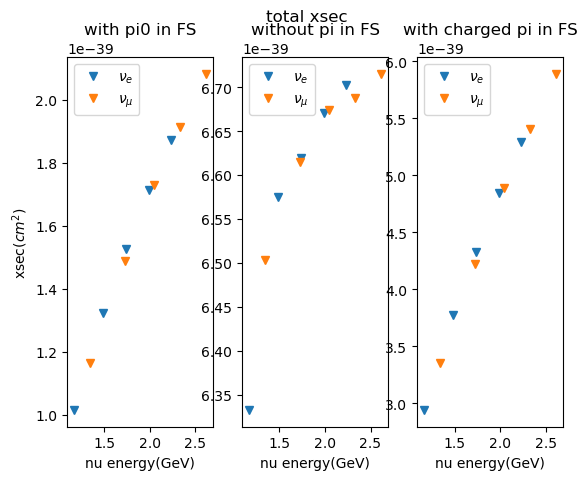

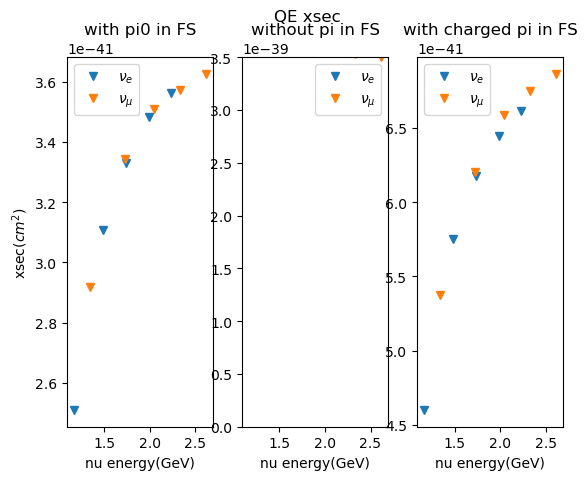

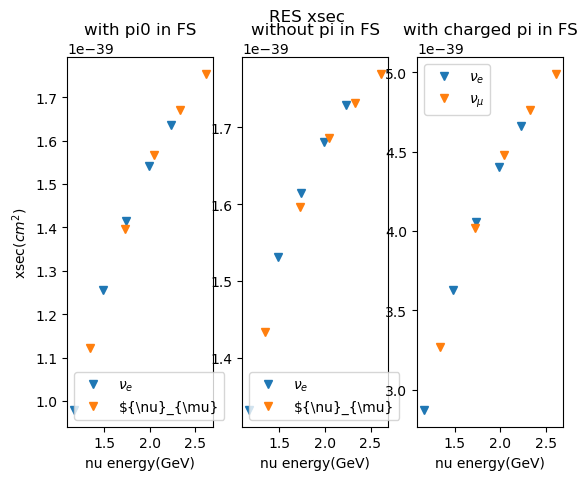

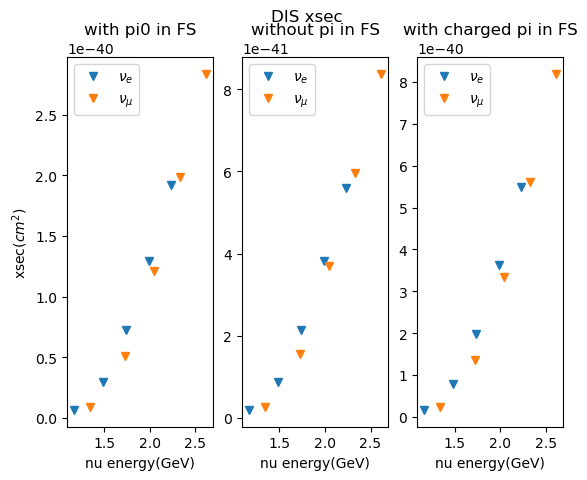

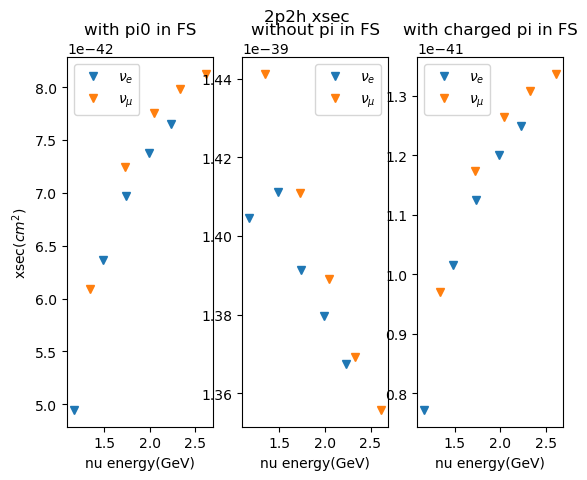

In [6]:
#total xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ ', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ ', marker='v')
ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')

ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax2.legend()
ax3.legend()

plt.show()


#QE_xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('QE xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ ', marker='v')
ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax2.set_ylim(0,3.5e-39)

ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax2.legend()
ax3.legend()

plt.show()


#RES_xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('RES xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ ', marker='v')
ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')

ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax2.legend()
ax3.legend()

plt.show()



#DIS_xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('DIS xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ ', marker='v')
ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')

ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax2.legend()
ax3.legend()

plt.show()



#2p2h_xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('2p2h xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ ', marker='v')
ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')

ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax2.legend()
ax3.legend()

plt.show()

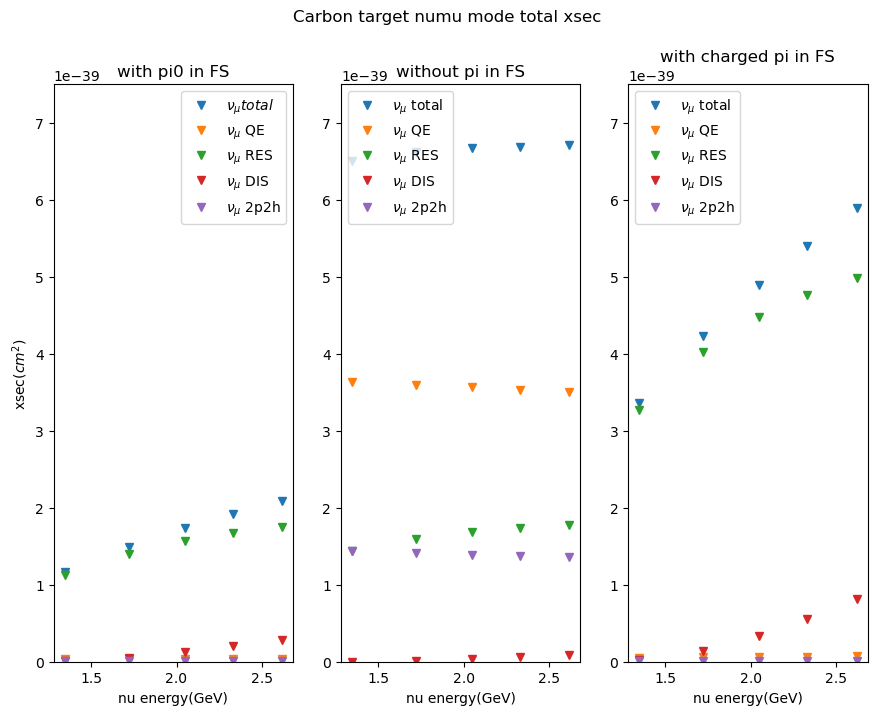

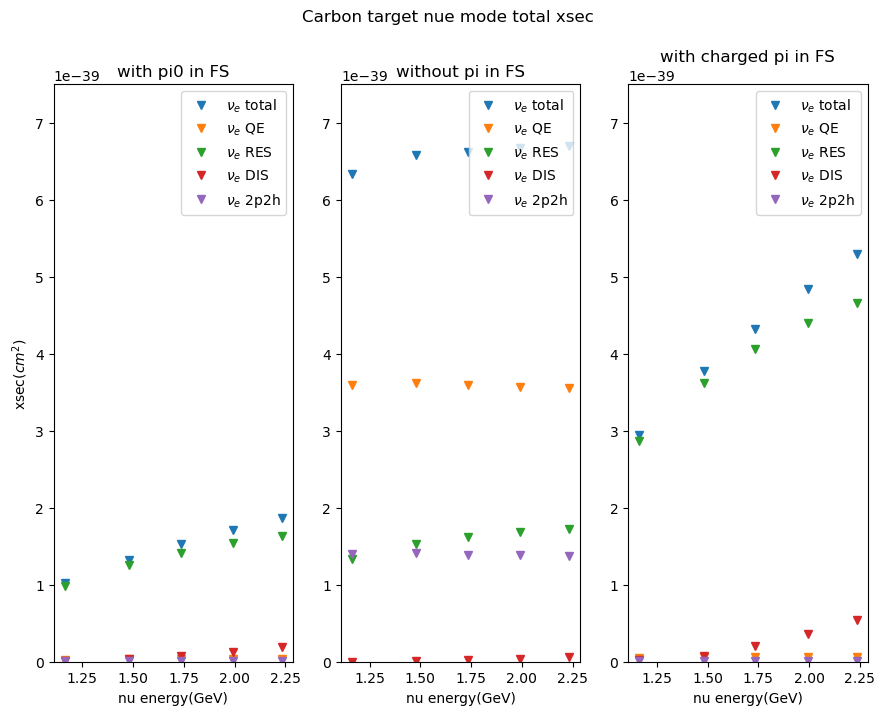

In [8]:
#total xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Carbon target numu mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax1.set_ylim(0,7.5e-39)
ax2.legend()
ax2.set_ylim(0,7.5e-39)
ax3.legend()
ax3.set_ylim(0,7.5e-39)

plt.show()


#total xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Carbon target nue mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax1.set_ylim(0,7.5e-39)
ax2.legend()
ax2.set_ylim(0,7.5e-39)
ax3.legend()
ax3.set_ylim(0,7.5e-39)

plt.show()

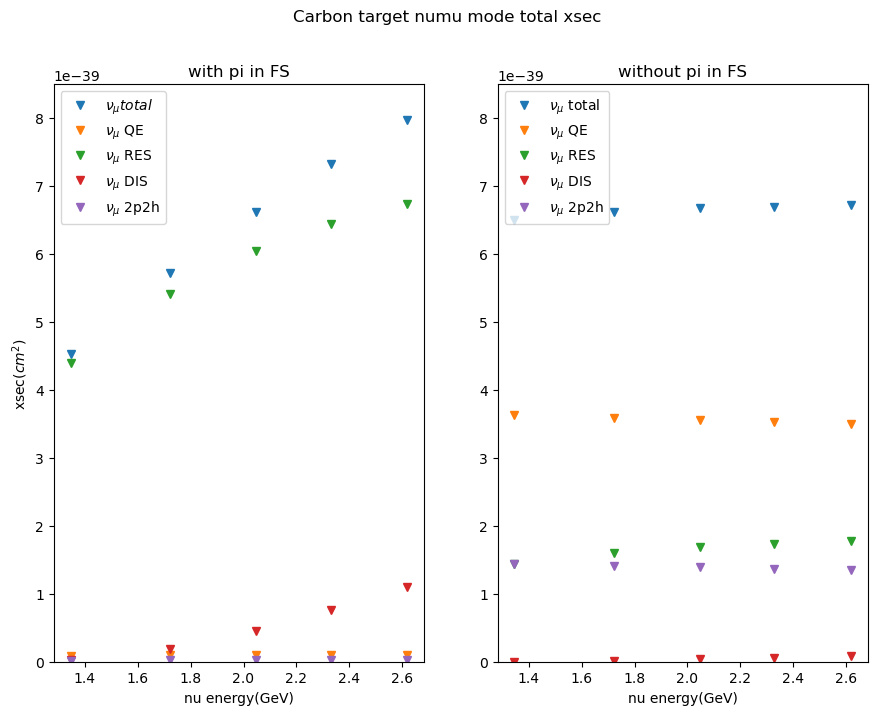

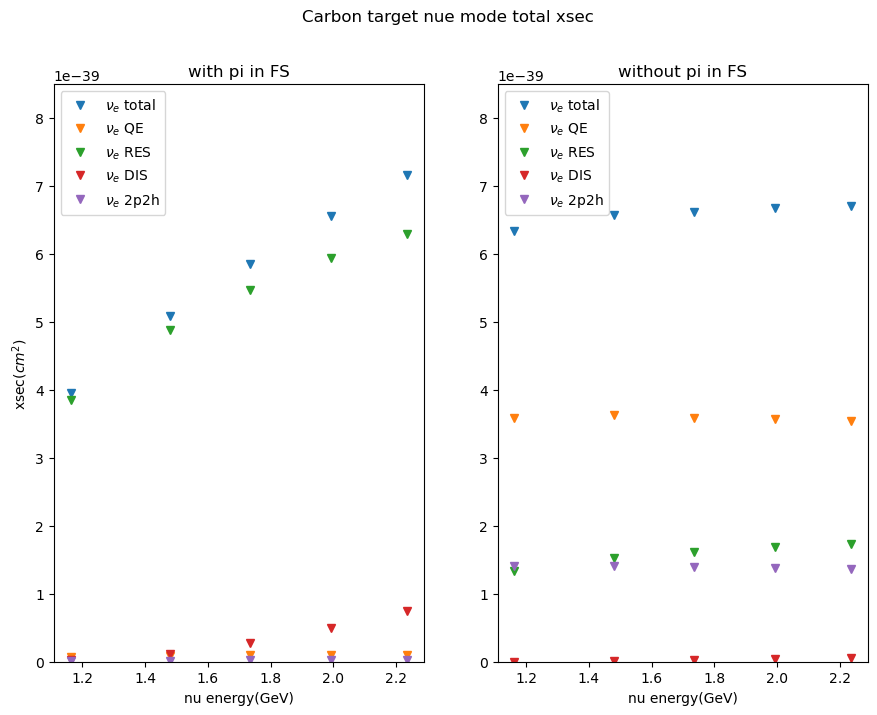

In [10]:
#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Carbon target numu mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_xsec_lst+Carbon_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_QE_xsec_lst+Carbon_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_RES_xsec_lst+Carbon_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_DIS_xsec_lst+Carbon_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Carbon_nu_mu_outana7_2p2h_xsec_lst+Carbon_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,8.5e-39)
ax2.legend()
ax2.set_ylim(0,8.5e-39)


plt.show()


#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Carbon target nue mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_xsec_lst+Carbon_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_QE_xsec_lst+Carbon_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_RES_xsec_lst+Carbon_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_DIS_xsec_lst+Carbon_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Carbon_nu_e_outana7_2p2h_xsec_lst+Carbon_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,8.5e-39)
ax2.legend()
ax2.set_ylim(0,8.5e-39)


plt.show()

In [34]:
np.array(Carbon_nu_e_outana7_xsec_lst)+np.array(Carbon_nu_e_charged_pi_xsec_lst)

array([3.655132e-39, 4.701750e-39, 5.402540e-39, 6.050170e-39,
       6.611180e-39])

In [11]:
#imitate xsec Carbon target anti neutrino mode
'''
anti numu
xsec for outana9
xsec of E3 mode : QE is 3.05911e-40 cm^{2}
xsec of E3 mode : RES is 3.5218e-40 cm^{2}
xsec of E3 mode : DIS is 3.19592e-43 cm^{2}
xsec of E3 mode : 2p2h is 2.37919e-40 cm^{2}
total xsec of E3 is 8.96329e-40 cm^{2}
xsec of E4 mode : QE is 3.51935e-40 cm^{2}
xsec of E4 mode : RES is 4.73371e-40 cm^{2}
xsec of E4 mode : DIS is 2.09898e-42 cm^{2}
xsec of E4 mode : 2p2h is 2.86557e-40 cm^{2}
total xsec of E4 is 1.11396e-39 cm^{2}
xsec of E5 mode : QE is 3.82657e-40 cm^{2}
xsec of E5 mode : RES is 5.60533e-40 cm^{2}
xsec of E5 mode : DIS is 5.59049e-42 cm^{2}
xsec of E5 mode : 2p2h is 3.18978e-40 cm^{2}
total xsec of E5 is 1.26776e-39 cm^{2}
xsec of E6 mode : QE is 4.0296e-40 cm^{2}
xsec of E6 mode : RES is 6.23977e-40 cm^{2}
xsec of E6 mode : DIS is 9.90743e-42 cm^{2}
xsec of E6 mode : 2p2h is 3.40783e-40 cm^{2}
total xsec of E6 is 1.37763e-39 cm^{2}
xsec of E7 mode : QE is 4.20676e-40 cm^{2}
xsec of E7 mode : RES is 6.78778e-40 cm^{2}
xsec of E7 mode : DIS is 1.51893e-41 cm^{2}
xsec of E7 mode : 2p2h is 3.59461e-40 cm^{2}
total xsec of E7 is 1.4741e-39 cm^{2}

xsec for outana7
xsec of E3 mode : QE is 3.22617e-42 cm^{2}
xsec of E3 mode : RES is 1.49237e-40 cm^{2}
xsec of E3 mode : DIS is 1.02976e-42 cm^{2}
xsec of E3 mode : 2p2h is 9.30379e-43 cm^{2}
total xsec of E3 is 1.54423e-40 cm^{2}
xsec of E4 mode : QE is 5.01326e-42 cm^{2}
xsec of E4 mode : RES is 2.30368e-40 cm^{2}
xsec of E4 mode : DIS is 7.25822e-42 cm^{2}
xsec of E4 mode : 2p2h is 1.46272e-42 cm^{2}
total xsec of E4 is 2.44102e-40 cm^{2}
xsec of E5 mode : QE is 6.53258e-42 cm^{2}
xsec of E5 mode : RES is 2.94442e-40 cm^{2}
xsec of E5 mode : DIS is 2.01488e-41 cm^{2}
xsec of E5 mode : 2p2h is 1.85979e-42 cm^{2}
total xsec of E5 is 3.22983e-40 cm^{2}
xsec of E6 mode : QE is 7.7432e-42 cm^{2}
xsec of E6 mode : RES is 3.44218e-40 cm^{2}
xsec of E6 mode : DIS is 3.6501e-41 cm^{2}
xsec of E6 mode : 2p2h is 2.16468e-42 cm^{2}
total xsec of E6 is 3.90627e-40 cm^{2}
xsec of E7 mode : QE is 8.84213e-42 cm^{2}
xsec of E7 mode : RES is 3.88254e-40 cm^{2}
xsec of E7 mode : DIS is 5.66828e-41 cm^{2}
xsec of E7 mode : 2p2h is 2.43086e-42 cm^{2}
total xsec of E7 is 4.56209e-40 cm^{2}


charged pi



anti nue
xsec for outana9
xsec of E3 mode : QE is 2.76867e-40 cm^{2}
xsec of E3 mode : RES is 3.02388e-40 cm^{2}
xsec of E3 mode : DIS is 1.94005e-43 cm^{2}
xsec of E3 mode : 2p2h is 2.02099e-40 cm^{2}
total xsec of E3 is 7.81548e-40 cm^{2}
xsec of E4 mode : QE is 3.24443e-40 cm^{2}
xsec of E4 mode : RES is 4.12028e-40 cm^{2}
xsec of E4 mode : DIS is 1.04012e-42 cm^{2}
xsec of E4 mode : 2p2h is 2.5204e-40 cm^{2}
total xsec of E4 is 9.89552e-40 cm^{2}
xsec of E5 mode : QE is 3.51346e-40 cm^{2}
xsec of E5 mode : RES is 4.8743e-40 cm^{2}
xsec of E5 mode : DIS is 2.92992e-42 cm^{2}
xsec of E5 mode : 2p2h is 2.81735e-40 cm^{2}
total xsec of E5 is 1.12344e-39 cm^{2}
xsec of E6 mode : QE is 3.74454e-40 cm^{2}
xsec of E6 mode : RES is 5.53563e-40 cm^{2}
xsec of E6 mode : DIS is 5.83059e-42 cm^{2}
xsec of E6 mode : 2p2h is 3.07017e-40 cm^{2}
total xsec of E6 is 1.24087e-39 cm^{2}
xsec of E7 mode : QE is 3.92651e-40 cm^{2}
xsec of E7 mode : RES is 6.08463e-40 cm^{2}
xsec of E7 mode : DIS is 9.32031e-42 cm^{2}
xsec of E7 mode : 2p2h is 3.2721e-40 cm^{2}
total xsec of E7 is 1.33764e-39 cm^{2}


xsec for outana7
xsec of E3 mode : QE is 2.40905e-42 cm^{2}
xsec of E3 mode : RES is 1.20304e-40 cm^{2}
xsec of E3 mode : DIS is 6.3366e-43 cm^{2}
xsec of E3 mode : 2p2h is 6.80222e-43 cm^{2}
total xsec of E3 is 1.24027e-40 cm^{2}
xsec of E4 mode : QE is 3.95878e-42 cm^{2}
xsec of E4 mode : RES is 1.86693e-40 cm^{2}
xsec of E4 mode : DIS is 3.64041e-42 cm^{2}
xsec of E4 mode : 2p2h is 1.11937e-42 cm^{2}
total xsec of E4 is 1.95412e-40 cm^{2}
xsec of E5 mode : QE is 5.18987e-42 cm^{2}
xsec of E5 mode : RES is 2.39955e-40 cm^{2}
xsec of E5 mode : DIS is 1.0699e-41 cm^{2}
xsec of E5 mode : 2p2h is 1.46287e-42 cm^{2}
total xsec of E5 is 2.57307e-40 cm^{2}
xsec of E6 mode : QE is 6.33078e-42 cm^{2}
xsec of E6 mode : RES is 2.88624e-40 cm^{2}
xsec of E6 mode : DIS is 2.18445e-41 cm^{2}
xsec of E6 mode : 2p2h is 1.76927e-42 cm^{2}
total xsec of E6 is 3.18569e-40 cm^{2}
xsec of E7 mode : QE is 7.31999e-42 cm^{2}
xsec of E7 mode : RES is 3.30532e-40 cm^{2}
xsec of E7 mode : DIS is 3.53552e-41 cm^{2}
xsec of E7 mode : 2p2h is 2.02908e-42 cm^{2}
total xsec of E7 is 3.75236e-40 cm^{2}


charged pi
[, , , , ]



Carbon_anti_nu_e_charged_pi_xsec_lst = np.array([3.02883e-40, 4.72465e-40, 6.20762e-40, 7.69798e-40, 9.10087e-40]) 
Carbon_anti_nu_e_charged_pi_QE_xsec_lst = np.array([3.70616e-42, 6.10572e-42, 8.13959e-42, 9.98331e-42, 1.158e-41]) 
Carbon_anti_nu_e_charged_pi_RES_xsec_lst = np.array([2.97061e-40, 4.57058e-40, 5.86116e-40, 7.05024e-40, 8.08033e-40]) 
Carbon_anti_nu_e_charged_pi_DIS_xsec_lst = np.array([1.30943e-42, 7.9571e-42, 2.47353e-41, 5.26369e-41, 8.79935e-41]) 
Carbon_anti_nu_e_charged_pi_2p2h_xsec_lst = np.array([8.06543e-43, 1.34393e-42, 1.77094e-42, 2.15355e-42, 2.48076e-42]) 

Carbon_anti_nu_e_outana7_xsec_lst =  np.array([1.24027e-40, 1.95412e-40, 2.57307e-40, 3.18569e-40, 3.75236e-40])
Carbon_anti_nu_e_outana7_QE_xsec_lst = np.array([2.40905e-42,3.95878e-42, 5.18987e-42, 6.33078e-42, 7.31999e-42])
Carbon_anti_nu_e_outana7_RES_xsec_lst = np.array([1.20304e-40, 1.86693e-40, 2.39955e-40, 2.88624e-40, 3.30532e-40])
Carbon_anti_nu_e_outana7_DIS_xsec_lst = np.array([6.3366e-43, 3.64041e-42, 1.0699e-41, 2.18445e-41, 3.53552e-41])
Carbon_anti_nu_e_outana7_2p2h_xsec_lst = np.array([6.80222e-43, 1.11937e-42, 1.46287e-42, 1.76927e-42, 2.02908e-42])

Carbon_anti_nu_e_outana9_xsec_lst =np.array([7.81548e-40, 9.89552e-40, 1.12344e-39, 1.24087e-39, 1.33764e-39])
Carbon_anti_nu_e_outana9_QE_xsec_lst = np.array([2.76867e-40, 3.24443e-40, 3.51346e-40, 3.74454e-40, 3.92651e-40])
Carbon_anti_nu_e_outana9_RES_xsec_lst = np.array([3.02388e-40, 4.12028e-40, 4.8743e-40, 5.53563e-40, 6.08463e-40])
Carbon_anti_nu_e_outana9_DIS_xsec_lst = np.array([1.94005e-43, 1.04012e-42, 2.92992e-42, 5.83059e-42, 9.32031e-42])
Carbon_anti_nu_e_outana9_2p2h_xsec_lst = np.array([2.02099e-40, 2.5204e-40, 2.81735e-40, 3.07017e-40, 3.2721e-40])

Carbon_anti_nu_mu_charged_pi_xsec_lst = np.array([3.75286e-40, 5.89237e-40, 7.79929e-40, 9.46877e-40, 1.11266e-39]) 
Carbon_anti_nu_mu_charged_pi_QE_xsec_lst = np.array([4.93908e-42, 7.98456e-42, 1.03642e-41, 1.2206e-41, 1.38841e-41]) 
Carbon_anti_nu_mu_charged_pi_RES_xsec_lst = np.array([3.67108e-40, 5.63244e-40, 7.19529e-40, 8.41863e-40, 9.50817e-40]) 
Carbon_anti_nu_mu_charged_pi_DIS_xsec_lst = np.array([2.1232e-42, 1.62313e-41, 4.7757e-41, 9.01426e-41, 1.44961e-40]) 
Carbon_anti_nu_mu_charged_pi_2p2h_xsec_lst = np.array([1.11593e-42, 1.77715e-42, 2.2791e-42, 2.66547e-42, 3.00157e-42]) 

Carbon_anti_nu_mu_outana7_xsec_lst = np.array([1.54423e-40, 2.44102e-40, 3.22983e-40, 3.90627e-40, 4.56209e-40])
Carbon_anti_nu_mu_outana7_QE_xsec_lst = np.array([3.22617e-42, 5.01326e-42, 6.53258e-42, 7.7432e-42, 8.84213e-42])
Carbon_anti_nu_mu_outana7_RES_xsec_lst = np.array([1.49237e-40, 2.30368e-40, 2.94442e-40, 3.44218e-40, 3.88254e-40])
Carbon_anti_nu_mu_outana7_DIS_xsec_lst = np.array([1.02976e-42, 7.25822e-42, 2.01488e-41, 3.6501e-41, 5.66828e-41])
Carbon_anti_nu_mu_outana7_2p2h_xsec_lst = np.array([9.30379e-43, 1.46272e-42, 1.85979e-42, 2.16468e-42, 2.43086e-42])

Carbon_anti_nu_mu_outana9_xsec_lst = np.array([8.96329e-40, 1.11396e-39, 1.26776e-39, 1.37763e-39, 1.4741e-39])
Carbon_anti_nu_mu_outana9_QE_xsec_lst = np.array([3.05911e-40, 3.51935e-40, 3.82657e-40, 4.0296e-40,4.20676e-40])
Carbon_anti_nu_mu_outana9_RES_xsec_lst = np.array([3.5218e-40, 4.73371e-40, 5.60533e-40, 6.23977e-40, 6.78778e-40])
Carbon_anti_nu_mu_outana9_DIS_xsec_lst = np.array([3.19592e-43, 2.09898e-42, 5.59049e-42, 9.90743e-42, 1.51893e-41])
Carbon_anti_nu_mu_outana9_2p2h_xsec_lst = np.array([2.37919e-40, 2.86557e-40, 3.18978e-40, 3.40783e-40,3.59461e-40])
'''


zero_line = np.array([0,0,0,0,0])
pi_E_lst = np.array([3,4,5,6,7])
musig_numu_E_lst = np.array([1.34543,1.72122,2.04772,2.32939,2.61806])
musig_nue_E_lst = np.array([1.1625,1.48087,1.73456,1.9923,2.23415])


Carbon_anti_nu_e_charged_pi_xsec_lst = np.array([4.54324e-40, 7.08697e-40, 9.31143e-40, 1.1547e-39, 1.36513e-39]) 
Carbon_anti_nu_e_charged_pi_QE_xsec_lst = np.array([5.55923e-42, 9.15858e-42, 1.22094e-41, 1.4975e-41, 1.73701e-41]) 
Carbon_anti_nu_e_charged_pi_RES_xsec_lst = np.array([4.45591e-40, 6.85587e-40, 8.79174e-40, 1.05754e-39, 1.21205e-39]) 
Carbon_anti_nu_e_charged_pi_DIS_xsec_lst = np.array([1.96415e-42, 1.19357e-41, 3.7103e-41, 7.89553e-41, 1.3199e-40]) 
Carbon_anti_nu_e_charged_pi_2p2h_xsec_lst = np.array([1.20982e-42, 2.0159e-42, 2.65642e-42, 3.23032e-42, 3.72113e-42]) 

Carbon_anti_nu_e_outana7_xsec_lst =  np.array([1.34363e-40, 2.11696e-40, 2.78749e-40, 3.45116e-40, 4.06506e-40])
Carbon_anti_nu_e_outana7_QE_xsec_lst = np.array([2.6098e-42, 4.28868e-42, 5.62236e-42, 6.85835e-42, 7.92998e-42])
Carbon_anti_nu_e_outana7_RES_xsec_lst = np.array([1.30329e-40, 2.02251e-40, 2.59951e-40, 3.12676e-40, 3.58076e-40])
Carbon_anti_nu_e_outana7_DIS_xsec_lst = np.array([6.86465e-43, 3.94378e-42, 1.15905e-41, 2.36649e-41, 3.83015e-41])
Carbon_anti_nu_e_outana7_2p2h_xsec_lst = np.array([7.36907e-43, 1.21265e-42, 1.58478e-42, 1.91671e-42, 2.19817e-42])

Carbon_anti_nu_e_outana9_xsec_lst =np.array([8.46677e-40, 1.07201e-39, 1.21706e-39, 1.34427e-39, 1.44911e-39])
Carbon_anti_nu_e_outana9_QE_xsec_lst = np.array([2.99939e-40, 3.5148e-40, 3.80625e-40, 4.05659e-40, 4.25372e-40])
Carbon_anti_nu_e_outana9_RES_xsec_lst = np.array([3.27587e-40, 4.46364e-40, 5.28049e-40, 5.99694e-40, 6.59168e-40])
Carbon_anti_nu_e_outana9_DIS_xsec_lst = np.array([2.10172e-43, 1.1268e-42, 3.17408e-42, 6.31647e-42, 1.0097e-41])
Carbon_anti_nu_e_outana9_2p2h_xsec_lst = np.array([2.18941e-40, 2.73044e-40, 3.05213e-40, 3.32602e-40, 3.54478e-40])

Carbon_anti_nu_mu_charged_pi_xsec_lst = np.array([5.6293e-40, 8.83856e-40, 1.16989e-39, 1.42032e-39, 1.669e-39]) 
Carbon_anti_nu_mu_charged_pi_QE_xsec_lst = np.array([7.40863e-42, 1.19768e-41, 1.55463e-41, 1.83089e-41, 2.08262e-41]) 
Carbon_anti_nu_mu_charged_pi_RES_xsec_lst = np.array([5.50662e-40, 8.44867e-40, 1.07929e-39, 1.26279e-39, 1.42623e-39]) 
Carbon_anti_nu_mu_charged_pi_DIS_xsec_lst = np.array([3.1848e-42, 2.4347e-41, 7.16356e-41, 1.35214e-40, 2.17442e-40]) 
Carbon_anti_nu_mu_charged_pi_2p2h_xsec_lst = np.array([1.67389e-42, 2.66573e-42, 3.41866e-42, 3.9982e-42, 4.50236e-42]) 

Carbon_anti_nu_mu_outana7_xsec_lst = np.array([1.67292e-40, 2.64444e-40, 3.49899e-40, 4.23179e-40, 4.94227e-40])
Carbon_anti_nu_mu_outana7_QE_xsec_lst = np.array([3.49502e-42, 5.43103e-42, 7.07696e-42, 8.38847e-42, 9.57898e-42])
Carbon_anti_nu_mu_outana7_RES_xsec_lst = np.array([1.61673e-40, 2.49565e-40, 3.18979e-40, 3.72903e-40, 4.20608e-40])
Carbon_anti_nu_mu_outana7_DIS_xsec_lst = np.array([1.11558e-42, 7.86307e-42, 2.18279e-41, 3.95427e-41, 6.14064e-41])
Carbon_anti_nu_mu_outana7_2p2h_xsec_lst = np.array([1.00791e-42, 1.58462e-42, 2.01477e-42, 2.34507e-42, 2.63343e-42])

Carbon_anti_nu_mu_outana9_xsec_lst = np.array([9.71023e-40, 1.20679e-39, 1.3734e-39, 1.49243e-39, 1.59695e-39])
Carbon_anti_nu_mu_outana9_QE_xsec_lst = np.array([3.31403e-40, 3.81263e-40, 4.14545e-40, 4.3654e-40, 4.55732e-40])
Carbon_anti_nu_mu_outana9_RES_xsec_lst = np.array([3.81529e-40, 5.12818e-40, 6.07244e-40, 6.75975e-40, 7.35342e-40])
Carbon_anti_nu_mu_outana9_DIS_xsec_lst = np.array([3.46225e-43, 2.2739e-42, 6.05636e-42, 1.07331e-41, 1.64551e-41])
Carbon_anti_nu_mu_outana9_2p2h_xsec_lst = np.array([2.57745e-40, 3.10436e-40, 3.45559e-40, 3.69181e-40, 3.89417e-40])

In [12]:
7.7432e-42+3.44218e-40+3.6501e-41+2.16468e-42

3.9062688e-40

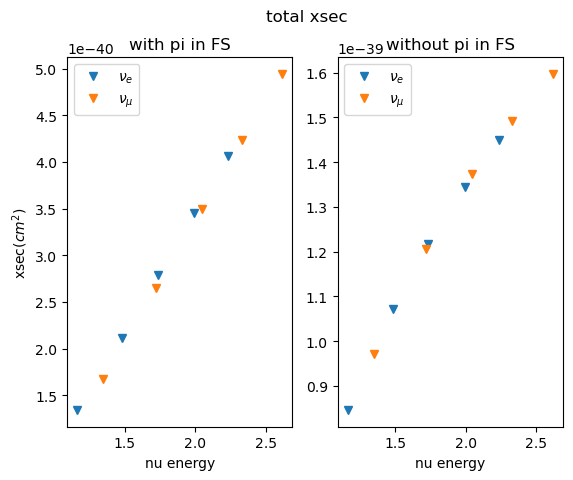

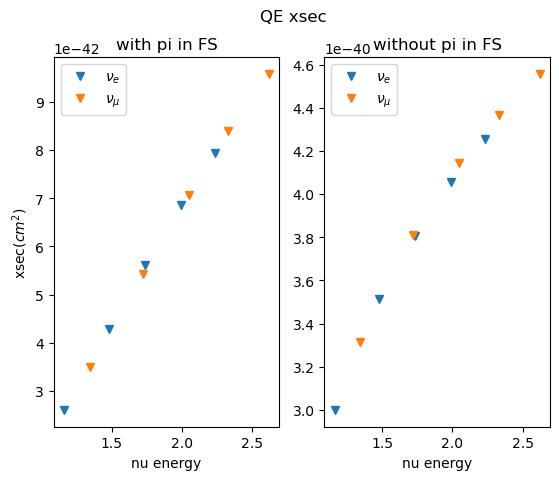

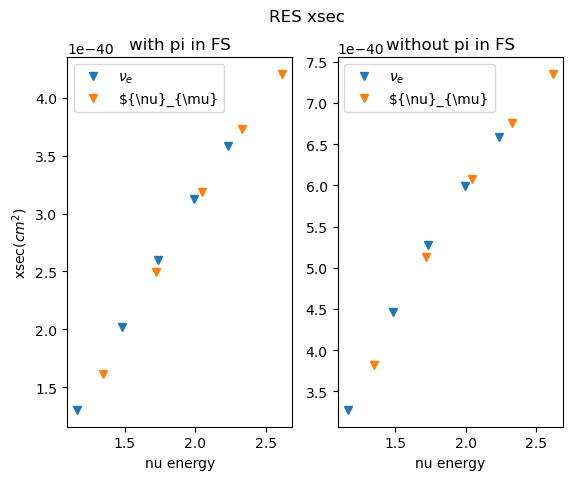

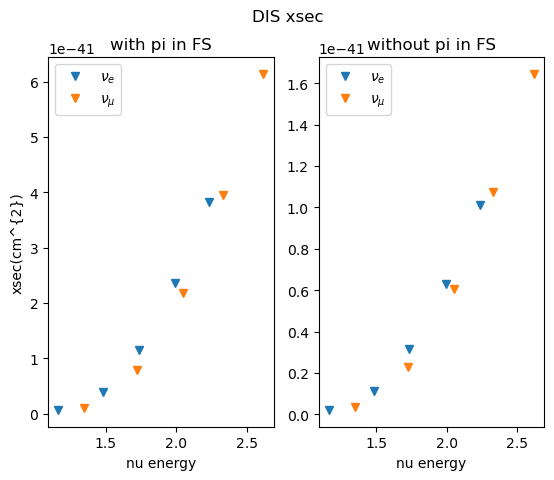

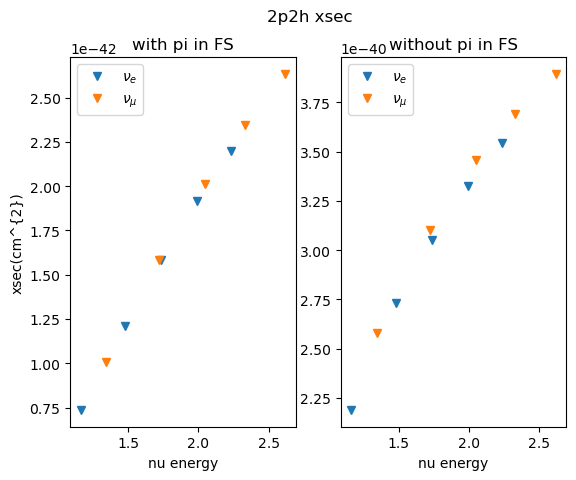

In [13]:
#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ ', marker='v')
ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

plt.show()


#QE_xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('QE xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

plt.show()


#RES_xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('RES xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}', marker='v')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

plt.show()



#DIS_xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('DIS xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec(cm^{2})')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

plt.show()



#2p2h_xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('2p2h xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec(cm^{2})')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

plt.show()

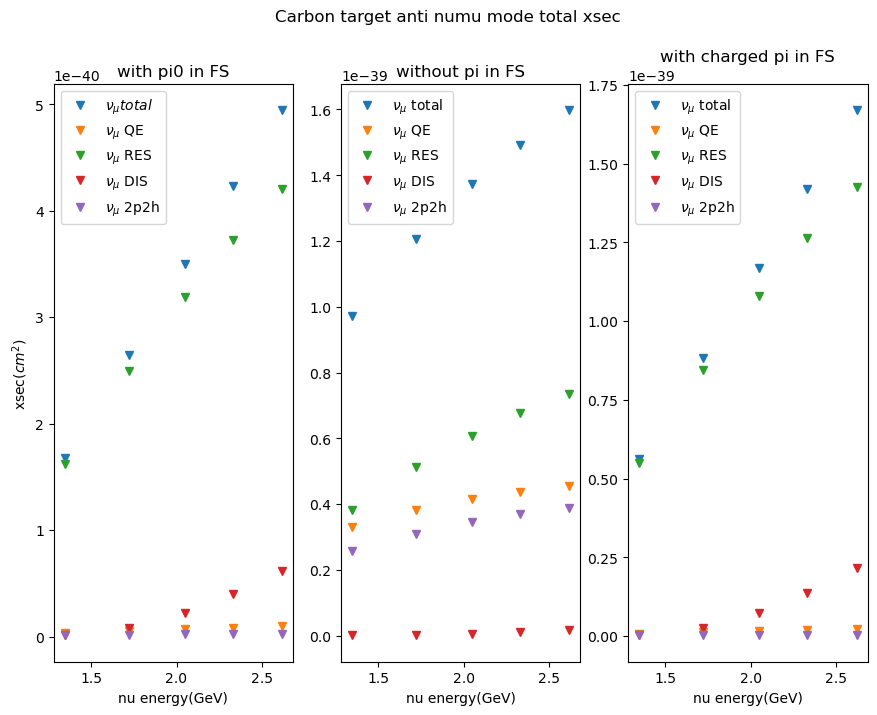

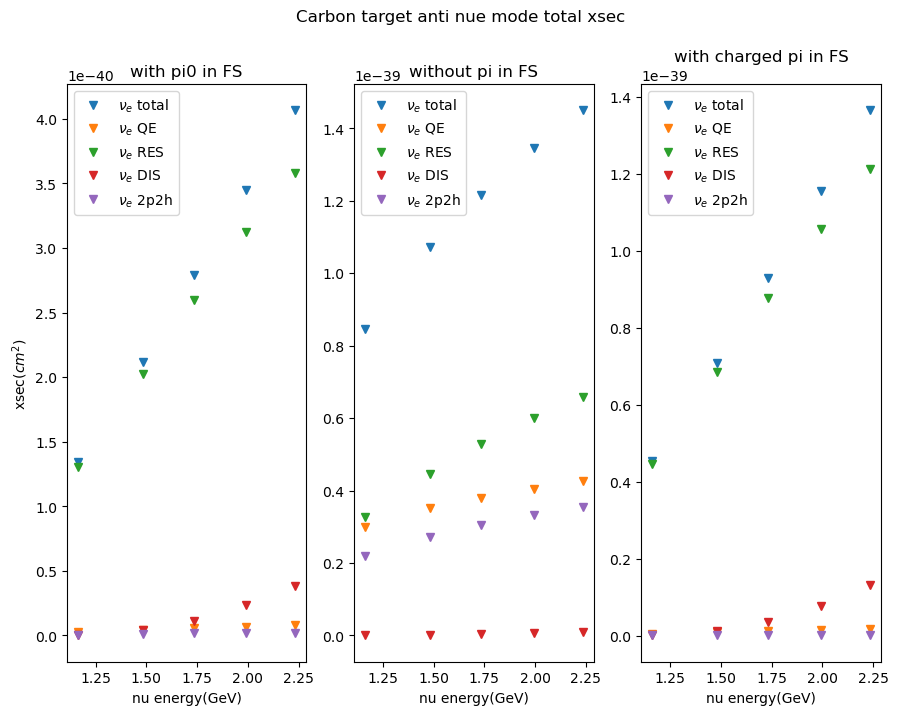

In [14]:
#total xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Carbon target anti numu mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax2.legend()
ax3.legend()

plt.show()


#total xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Carbon target anti nue mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax2.legend()
ax3.legend()

plt.show()

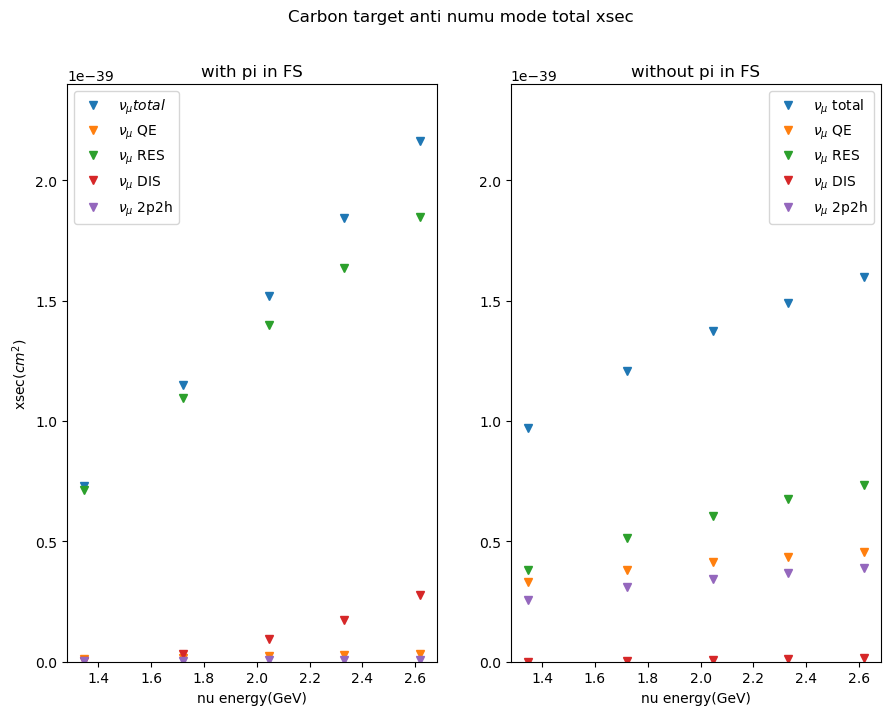

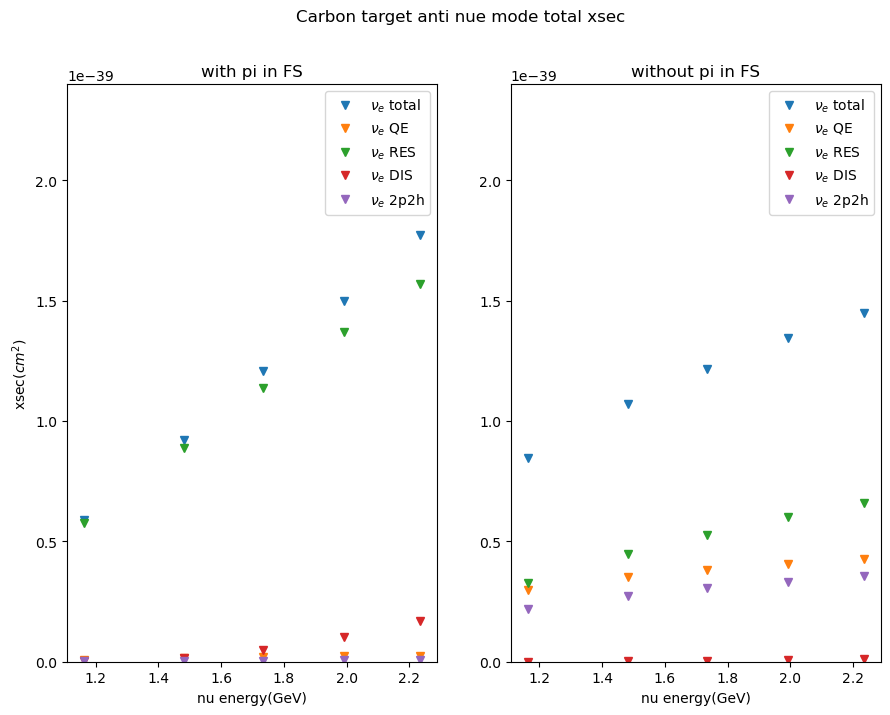

In [18]:
#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Carbon target anti numu mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_xsec_lst+Carbon_anti_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_QE_xsec_lst+Carbon_anti_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_RES_xsec_lst+Carbon_anti_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_DIS_xsec_lst+Carbon_anti_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana7_2p2h_xsec_lst+Carbon_anti_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Carbon_anti_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
#ax3.plot(musig_numu_E_lst, Carbon_anti_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,2.4e-39)
ax2.legend()
ax2.set_ylim(0,2.4e-39)


plt.show()


#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Carbon target anti nue mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_xsec_lst+Carbon_anti_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_QE_xsec_lst+Carbon_anti_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_RES_xsec_lst+Carbon_anti_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_DIS_xsec_lst+Carbon_anti_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana7_2p2h_xsec_lst+Carbon_anti_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Carbon_anti_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
#ax3.plot(musig_nue_E_lst, Carbon_anti_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,2.4e-39)
ax2.legend()
ax2.set_ylim(0,2.4e-39)


plt.show()

In [19]:
'''
numu

E3SpectraMuSig560Numu_outAna7
direct perweight calc total xsec : 8.57605e-40 cm^{2}
direct perweight calc xsec for mode : QE is 2.0932e-41 cm^{2}
direct perweight calc xsec for mode : RES is 7.16038e-40 cm^{2}
direct perweight calc xsec for mode : DIS is 6.22895e-42 cm^{2}
direct perweight calc xsec for mode : 2p2h is 4.34911e-42 cm^{2}
E3SpectraMuSig560Numu_outAna9
direct perweight calc total xsec : 4.51832e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.40243e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.11494e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 2.35064e-42 cm^{2}
direct perweight calc xsec for mode : 2p2h is 9.5712e-40 cm^{2}


E4SpectraMuSig566Numu_outAna7
direct perweight calc total xsec : 1.12673e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.37587e-41 cm^{2}
direct perweight calc xsec for mode : RES is 8.96241e-40 cm^{2}
direct perweight calc xsec for mode : DIS is 3.53083e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 5.15374e-42 cm^{2}
E4SpectraMuSig566Numu_outAna9
direct perweight calc total xsec : 4.63143e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.37926e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.24685e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 1.28714e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 9.36668e-40 cm^{2}


E5SpectraMuSig558Numu_outAna7
direct perweight calc total xsec : 1.32516e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.50783e-41 cm^{2}
direct perweight calc xsec for mode : RES is 1.00722e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 8.38086e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 5.50854e-42 cm^{2}
E5SpectraMuSig558Numu_outAna9
direct perweight calc total xsec : 4.69438e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.35895e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.31972e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 2.99104e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 9.21986e-40 cm^{2}


E6spectraMuSig557Numu_outAna7
direct perweight calc total xsec : 1.47296e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.56016e-41 cm^{2}
direct perweight calc xsec for mode : RES is 1.07645e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 1.36724e-40 cm^{2}
direct perweight calc xsec for mode : 2p2h is 5.66753e-42 cm^{2}
E6spectraMuSig557Numu_outAna9
direct perweight calc total xsec : 4.71773e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.33588e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.35652e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 4.78598e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 9.08757e-40 cm^{2}


E7SpectraMuSig556Numu_outAna7
direct perweight calc total xsec : 1.6045e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.59378e-41 cm^{2}
direct perweight calc xsec for mode : RES is 1.13022e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 1.95225e-40 cm^{2}
direct perweight calc xsec for mode : 2p2h is 5.77081e-42 cm^{2}
E7SpectraMuSig556Numu_outAna9
direct perweight calc total xsec : 4.74684e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.32082e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.38716e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 6.69476e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 8.99687e-40 cm^{2}


nue

E3SpectraMuSig560Nue_outAna7
direct perweight calc total xsec : 7.34477e-40 cm^{2}
direct perweight calc xsec for mode : QE is 1.78127e-41 cm^{2}
direct perweight calc xsec for mode : RES is 6.23379e-40 cm^{2}
direct perweight calc xsec for mode : DIS is 4.50473e-42 cm^{2}
direct perweight calc xsec for mode : 2p2h is 3.51528e-42 cm^{2}
E3SpectraMuSig560Nue_outAna9
direct perweight calc total xsec : 4.3853e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.38686e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.03222e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 1.66627e-42 cm^{2}
direct perweight calc xsec for mode : 2p2h is 9.31458e-40 cm^{2}


E4SpectraMuSig566Nue_outAna7
direct perweight calc total xsec : 9.82594e-40 cm^{2}
direct perweight calc xsec for mode : QE is 2.19765e-41 cm^{2}
direct perweight calc xsec for mode : RES is 8.02317e-40 cm^{2}
direct perweight calc xsec for mode : DIS is 2.04898e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 4.53276e-42 cm^{2}
E4SpectraMuSig566Nue_outAna9
direct perweight calc total xsec : 4.58603e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.4033e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.19229e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 7.36085e-42 cm^{2}
direct perweight calc xsec for mode : 2p2h is 9.35929e-40 cm^{2}


E5SpectraMuSig558Nue_outAna7
direct perweight calc total xsec : 1.15255e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.34777e-41 cm^{2}
direct perweight calc xsec for mode : RES is 9.06629e-40 cm^{2}
direct perweight calc xsec for mode : DIS is 4.99667e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 4.96447e-42 cm^{2}
E5SpectraMuSig558Nue_outAna9
direct perweight calc total xsec : 4.63635e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.37958e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.26086e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 1.76039e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 9.22993e-40 cm^{2}


E6spectraMuSig557Nue_outAna7
direct perweight calc total xsec : 1.30449e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.44928e-41 cm^{2}
direct perweight calc xsec for mode : RES is 9.89923e-40 cm^{2}
direct perweight calc xsec for mode : DIS is 8.95678e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 5.25665e-42 cm^{2}
E6spectraMuSig557Nue_outAna9
direct perweight calc total xsec : 4.68932e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.36653e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.31506e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 3.10579e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 9.15238e-40 cm^{2}


E7SpectraMuSig556Nue_outAna7
direct perweight calc total xsec : 1.43255e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.51464e-41 cm^{2}
direct perweight calc xsec for mode : RES is 1.05292e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 1.32306e-40 cm^{2}
direct perweight calc xsec for mode : 2p2h is 5.44835e-42 cm^{2}
E7SpectraMuSig556Nue_outAna9
direct perweight calc total xsec : 4.72394e-39 cm^{2}
direct perweight calc xsec for mode : QE is 2.35192e-39 cm^{2}
direct perweight calc xsec for mode : RES is 1.35372e-39 cm^{2}
direct perweight calc xsec for mode : DIS is 4.52146e-41 cm^{2}
direct perweight calc xsec for mode : 2p2h is 9.0719e-40 cm^{2}


#imitate xsec Oxygen target neutrino mode


Oxygen_nu_e_charged_pi_xsec_lst = np.array([1.87719e-39, 2.41805e-39, 2.78554e-39, 3.12865e-39, 3.4285e-39]) 
Oxygen_nu_e_charged_pi_QE_xsec_lst =np.array([3.1201e-41, 3.90603e-41, 4.22694e-41, 4.4365e-41, 4.56848e-41])
Oxygen_nu_e_charged_pi_RES_xsec_lst = np.array([1.82894e-39, 2.31774e-39, 2.59966e-39, 2.8268e-39, 2.99907e-39]) 
Oxygen_nu_e_charged_pi_DIS_xsec_lst = np.array([1.14471e-41, 5.39082e-41, 1.35494e-40, 2.48833e-40, 3.74739e-40]) 
Oxygen_nu_e_charged_pi_2p2h_xsec_lst = np.array([5.60073e-42, 7.33924e-42, 8.12298e-42, 8.65569e-42, 9.00539e-42]) 

Oxygen_nu_e_outana7_xsec_lst = np.array([6.49211e-40, 8.49316e-40, 9.85038e-40, 1.10924e-39, 1.21582e-39]) 
Oxygen_nu_e_outana7_QE_xsec_lst = np.array([1.78127e-41, 2.19765e-41, 2.34777e-41, 2.44928e-41, 2.51464e-41])
Oxygen_nu_e_outana7_RES_xsec_lst = np.array([6.23379e-40, 8.02317e-40, 9.06629e-40, 9.89923e-40, 1.05292e-39])
Oxygen_nu_e_outana7_DIS_xsec_lst = np.array([4.50473e-42, 2.04898e-41, 4.99667e-41, 8.95678e-41, 1.32306e-40])
Oxygen_nu_e_outana7_2p2h_xsec_lst = np.array([3.51528e-42, 4.53276e-42, 4.96447e-42, 5.25665e-42, 5.44835e-42])

Oxygen_nu_e_outana9_xsec_lst = np.array([4.3522e-39, 4.53887e-39, 4.58104e-39, 4.62789e-39, 4.65804e-39]) 
Oxygen_nu_e_outana9_QE_xsec_lst = np.array([2.38686e-39, 2.4033e-39, 2.37958e-39, 2.36653e-39, 2.35192e-39])
Oxygen_nu_e_outana9_RES_xsec_lst = np.array([1.03222e-39, 1.19229e-39, 1.26086e-39, 1.31506e-39, 1.35372e-39])
Oxygen_nu_e_outana9_DIS_xsec_lst = np.array([1.66627e-42, 7.36085e-42, 1.76039e-41, 3.10579e-41, 4.52146e-41])
Oxygen_nu_e_outana9_2p2h_xsec_lst = np.array([9.31458e-40, 9.35929e-40, 9.22993e-40, 9.15238e-40, 9.0719e-40])

Oxygen_nu_mu_charged_pi_xsec_lst = np.array([2.14858e-39, 2.72016e-39, 3.16229e-39, 3.50604e-39, 3.83115e-39]) 
Oxygen_nu_mu_charged_pi_QE_xsec_lst = np.array([3.70304e-41, 4.31194e-41, 4.58631e-41, 4.70014e-41, 4.77392e-41]) 
Oxygen_nu_mu_charged_pi_RES_xsec_lst = np.array([2.08893e-39, 2.57545e-39, 2.8783e-39, 3.0664e-39, 3.21417e-39]) 
Oxygen_nu_mu_charged_pi_DIS_xsec_lst = np.array([1.56353e-41, 9.31593e-41, 2.29032e-40, 3.8323e-40, 5.5962e-40]) 
Oxygen_nu_mu_charged_pi_2p2h_xsec_lst = np.array([6.984e-42, 8.43438e-42, 9.09646e-42, 9.40891e-42, 9.61353e-42])

Oxygen_nu_mu_outana7_xsec_lst = np.array([7.47548e-40, 9.60462e-40, 1.12162e-39, 1.24444e-39, 1.35715e-39]) 
Oxygen_nu_mu_outana7_QE_xsec_lst = np.array([2.0932e-41, 2.37587e-41, 2.50783e-41, 2.56016e-41, 2.59378e-41])
Oxygen_nu_mu_outana7_RES_xsec_lst = np.array([7.16038e-40, 8.96241e-40, 1.00722e-39, 1.07645e-39, 1.13022e-39])
Oxygen_nu_mu_outana7_DIS_xsec_lst = np.array([6.22895e-42, 3.53083e-41, 8.38086e-41, 1.36724e-40, 1.95225e-40])
Oxygen_nu_mu_outana7_2p2h_xsec_lst = np.array([4.34911e-42, 5.15374e-42, 5.50854e-42, 5.66753e-42, 5.77081e-42])

Oxygen_nu_mu_outana9_xsec_lst = np.array([4.47684e-39, 4.57565e-39, 4.63056e-39, 4.64901e-39, 4.67461e-39]) 
Oxygen_nu_mu_outana9_QE_xsec_lst = np.array([2.40243e-39, 2.37926e-39, 2.35895e-39, 2.33588e-39, 2.32082e-39])
Oxygen_nu_mu_outana9_RES_xsec_lst = np.array([1.11494e-39, 1.24685e-39, 1.31972e-39, 1.35652e-39, 1.38716e-39])
Oxygen_nu_mu_outana9_DIS_xsec_lst = np.array([2.35064e-42, 1.28714e-41, 2.99104e-41, 4.78598e-41, 6.69476e-41])
Oxygen_nu_mu_outana9_2p2h_xsec_lst = np.array([9.5712e-40, 9.36668e-40, 9.21986e-40, 9.08757e-40, 8.99687e-40])
'''

pi_E_lst = np.array([3,4,5,6,7])
musig_numu_E_lst = np.array([1.34543,1.72122,2.04772,2.32939,2.61806])
musig_nue_E_lst = np.array([1.1625,1.48087,1.73456,1.9923,2.23415])


Oxygen_nu_e_charged_pi_xsec_lst = np.array([2.11184e-39, 2.7203e-39, 3.13374e-39, 3.51974e-39, 3.85706e-39]) 
Oxygen_nu_e_charged_pi_QE_xsec_lst =np.array([3.51011e-41, 4.39428e-41, 4.75531e-41, 4.99106e-41, 5.13954e-41])
Oxygen_nu_e_charged_pi_RES_xsec_lst = np.array([2.05756e-39, 2.60746e-39, 2.92461e-39, 3.18015e-39, 3.37395e-39]) 
Oxygen_nu_e_charged_pi_DIS_xsec_lst = np.array([1.2878e-41, 6.06467e-41, 1.52431e-40, 2.79937e-40, 4.21582e-40]) 
Oxygen_nu_e_charged_pi_2p2h_xsec_lst = np.array([6.30082e-42, 8.25665e-42, 9.13835e-42, 9.73766e-42, 1.01311e-41]) 

Oxygen_nu_e_outana7_xsec_lst = np.array([7.30363e-40, 9.5548e-40, 1.10817e-39, 1.24789e-39, 1.36779e-39]) 
Oxygen_nu_e_outana7_QE_xsec_lst = np.array([2.00393e-41, 2.47235e-41, 2.64124e-41, 2.75543e-41, 2.82897e-41])
Oxygen_nu_e_outana7_RES_xsec_lst = np.array([7.01301e-40, 9.02606e-40, 1.01996e-39, 1.11366e-39, 1.18453e-39])
Oxygen_nu_e_outana7_DIS_xsec_lst = np.array([5.06783e-42, 2.3051e-41, 5.62126e-41, 1.00764e-40, 1.48844e-40])
Oxygen_nu_e_outana7_2p2h_xsec_lst = np.array([3.95469e-42, 5.09936e-42, 5.58503e-42, 5.91373e-42, 6.12939e-42])

Oxygen_nu_e_outana9_xsec_lst = np.array([4.89622e-39, 5.10623e-39, 5.15367e-39, 5.20638e-39, 5.2403e-39]) 
Oxygen_nu_e_outana9_QE_xsec_lst = np.array([2.68522e-39, 2.70371e-39, 2.67703e-39, 2.66235e-39, 2.64591e-39])
Oxygen_nu_e_outana9_RES_xsec_lst = np.array([1.16124e-39, 1.34132e-39, 1.41847e-39, 1.47944e-39, 1.52293e-39])
Oxygen_nu_e_outana9_DIS_xsec_lst = np.array([1.87455e-42, 8.28096e-42, 1.98044e-41, 3.49401e-41, 5.08664e-41])
Oxygen_nu_e_outana9_2p2h_xsec_lst = np.array([1.04789e-39, 1.05292e-39, 1.03837e-39, 1.02964e-39, 1.02059e-39])

Oxygen_nu_mu_charged_pi_xsec_lst = np.array([2.41715e-39, 3.06018e-39, 3.55758e-39, 3.9443e-39, 4.31004e-39]) 
Oxygen_nu_mu_charged_pi_QE_xsec_lst = np.array([4.16592e-41, 4.85093e-41, 5.15959e-41, 5.28766e-41, 5.37066e-41]) 
Oxygen_nu_mu_charged_pi_RES_xsec_lst = np.array([2.35005e-39, 2.89738e-39, 3.23809e-39, 3.4497e-39, 3.61595e-39]) 
Oxygen_nu_mu_charged_pi_DIS_xsec_lst = np.array([1.75897e-41, 1.04804e-40, 2.57661e-40, 4.31134e-40, 6.29573e-40]) 
Oxygen_nu_mu_charged_pi_2p2h_xsec_lst = np.array([7.857e-42, 9.48868e-42, 1.02335e-41, 1.0585e-41, 1.08152e-41])

Oxygen_nu_mu_outana7_xsec_lst = np.array([8.40991e-40, 1.08052e-39, 1.26182e-39, 1.4e-39, 1.5268e-39]) 
Oxygen_nu_mu_outana7_QE_xsec_lst = np.array([2.35485e-41, 2.67286e-41, 2.8213e-41, 2.88018e-41, 2.91801e-41])
Oxygen_nu_mu_outana7_RES_xsec_lst = np.array([8.05542e-40, 1.00827e-39, 1.13312e-39, 1.211e-39, 1.2715e-39])
Oxygen_nu_mu_outana7_DIS_xsec_lst = np.array([7.00757e-42, 3.97218e-41, 9.42846e-41, 1.53814e-40, 2.19628e-40])
Oxygen_nu_mu_outana7_2p2h_xsec_lst = np.array([4.89275e-42, 5.79795e-42, 6.19711e-42, 6.37597e-42, 6.49216e-42])

Oxygen_nu_mu_outana9_xsec_lst = np.array([5.03645e-39, 5.14761e-39, 5.20938e-39, 5.23014e-39, 5.25894e-39]) 
Oxygen_nu_mu_outana9_QE_xsec_lst = np.array([2.70273e-39, 2.67667e-39, 2.65382e-39, 2.62786e-39, 2.61092e-39])
Oxygen_nu_mu_outana9_RES_xsec_lst = np.array([1.25431e-39, 1.40271e-39, 1.48468e-39, 1.52609e-39, 1.56055e-39])
Oxygen_nu_mu_outana9_DIS_xsec_lst = np.array([2.64447e-42, 1.44803e-41, 3.36492e-41, 5.38423e-41, 7.5316e-41])
Oxygen_nu_mu_outana9_2p2h_xsec_lst = np.array([1.07676e-39, 1.05375e-39, 1.03723e-39, 1.02235e-39, 1.01215e-39])

In [20]:
2.40243e-39+1.11494e-39+2.35064e-42+9.5712e-40

4.47684064e-39

In [21]:
100/(1e5)**0.5

0.3162277660168379

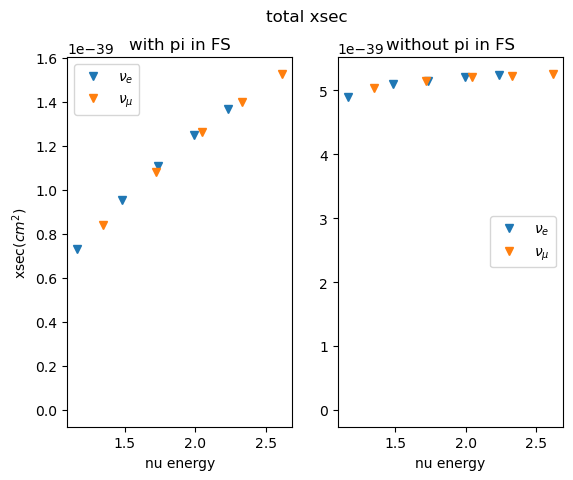

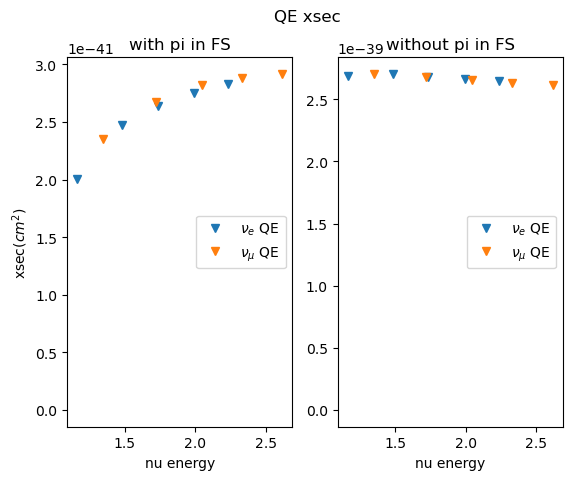

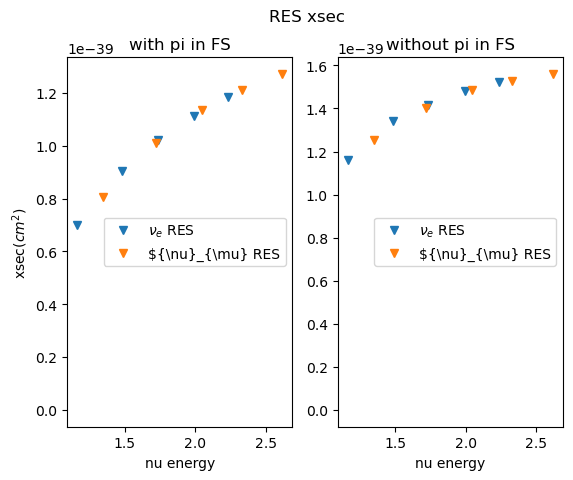

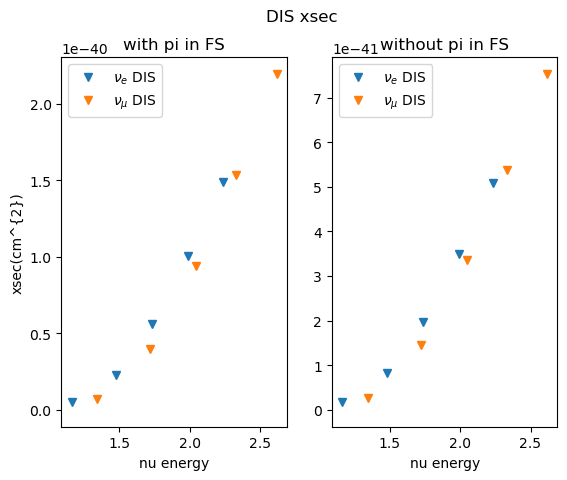

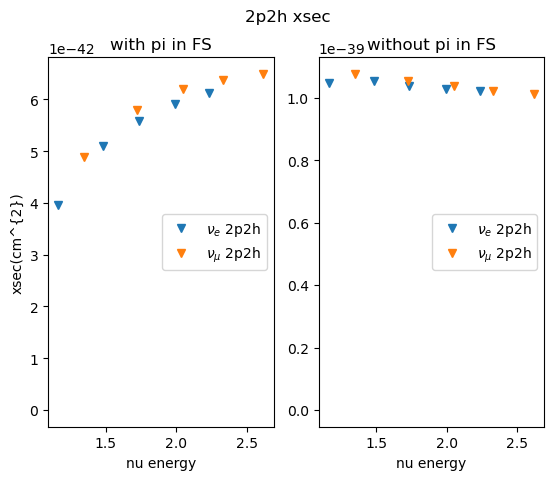

In [22]:
#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{e}$', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ ', marker='v')
ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')


ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

plt.show()


#QE_xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('QE xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

plt.show()


#RES_xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('RES xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} RES', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} RES', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

plt.show()



#DIS_xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('DIS xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec(cm^{2})')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

plt.show()



#2p2h_xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('2p2h xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec(cm^{2})')

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')
ax1.set(xlabel='nu energy', ylabel='xsec(cm^{2})')
ax2.set(xlabel='nu energy')

ax1.legend()
ax2.legend()

plt.show()

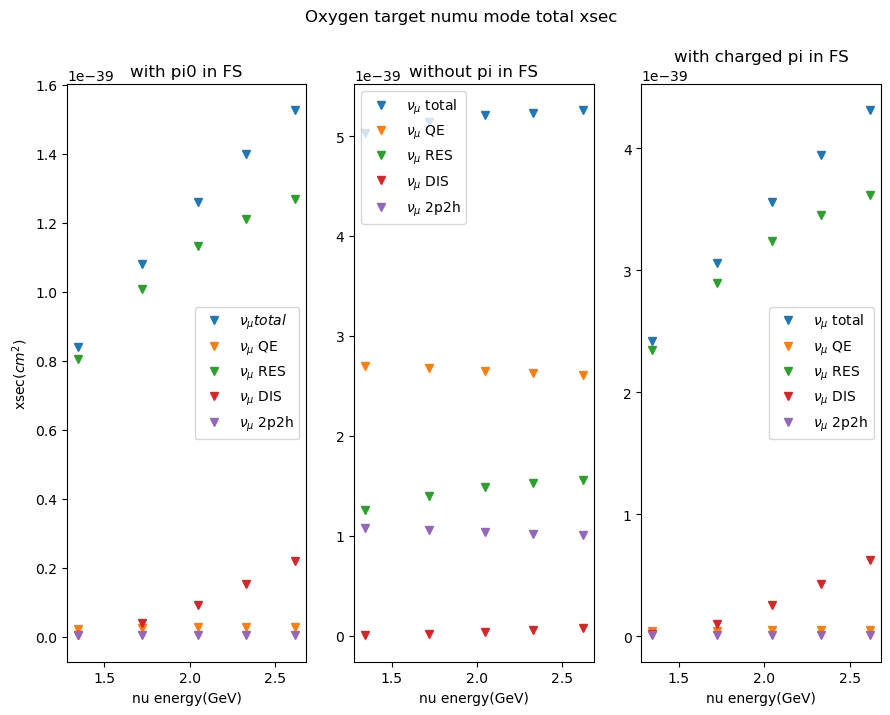

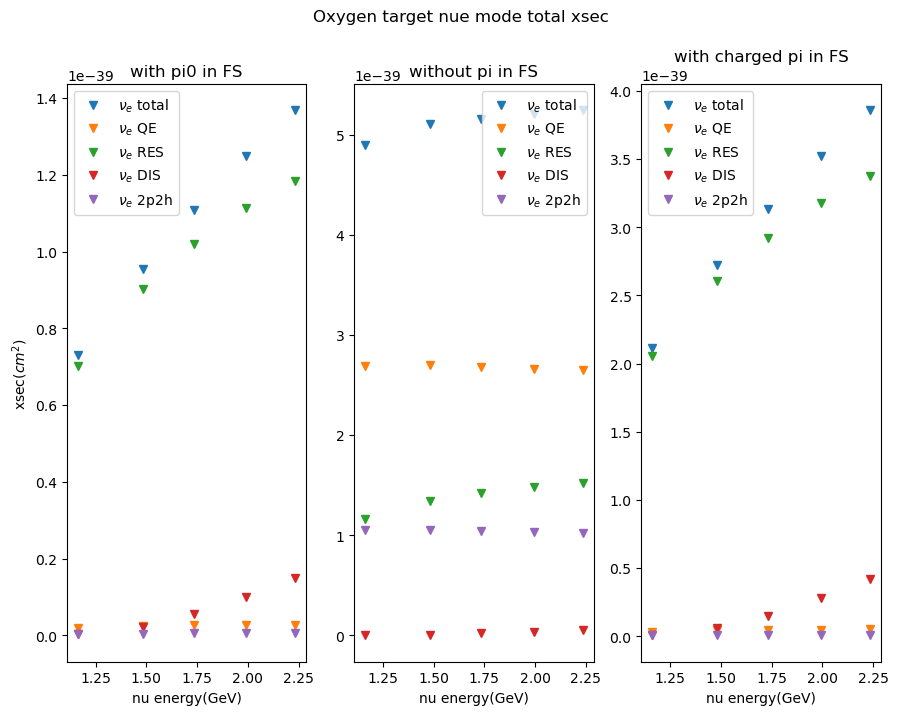

In [23]:
#total xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Oxygen target numu mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax2.legend()
ax3.legend()

plt.show()


#total xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Oxygen target nue mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax2.legend()
ax3.legend()

plt.show()

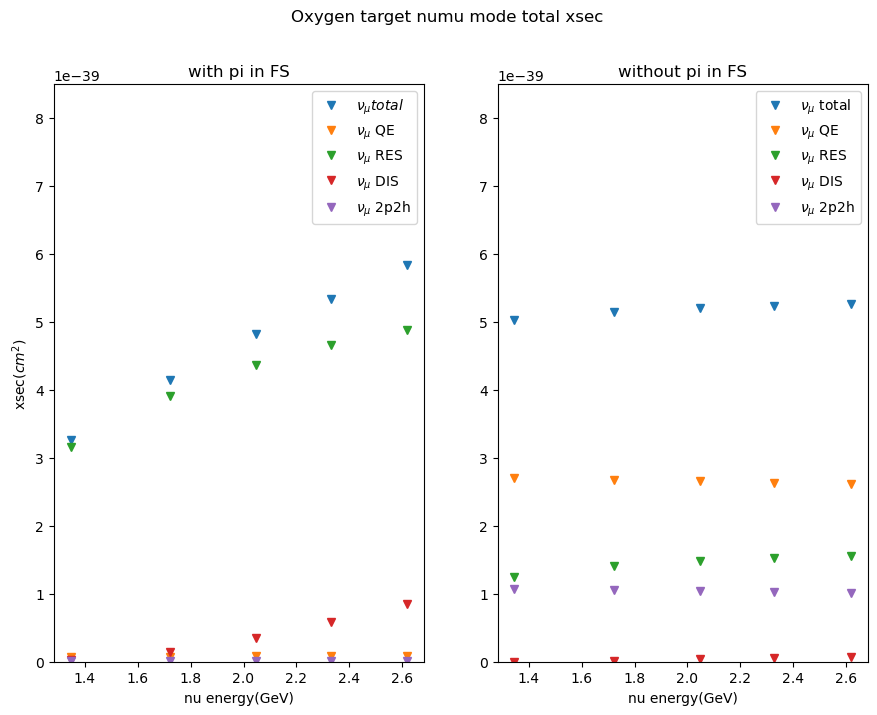

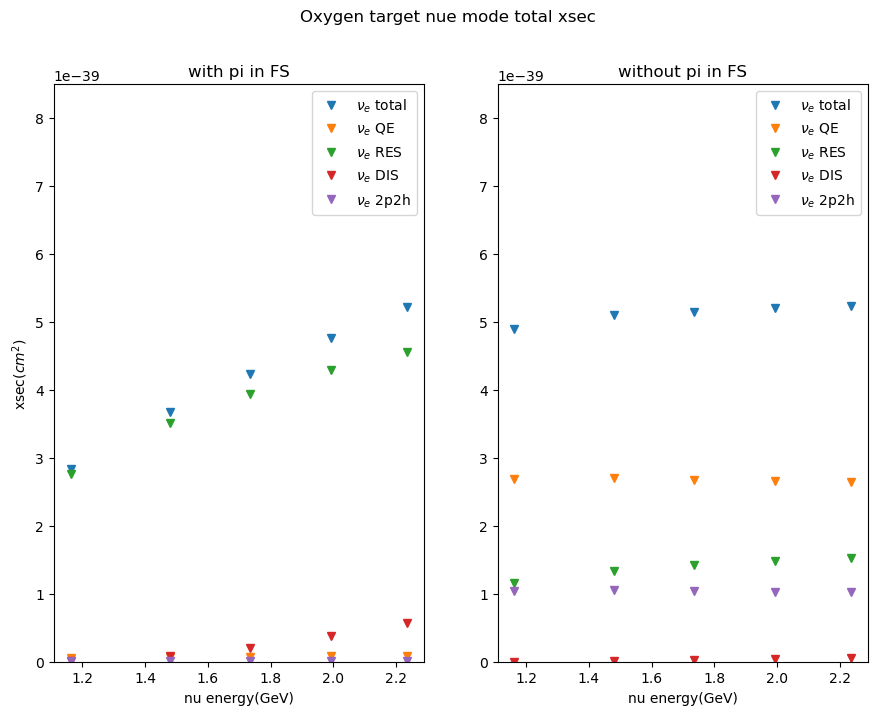

In [25]:
#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Oxygen target numu mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_xsec_lst+Oxygen_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_QE_xsec_lst+Oxygen_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_RES_xsec_lst+Oxygen_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_DIS_xsec_lst+Oxygen_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Oxygen_nu_mu_outana7_2p2h_xsec_lst+Oxygen_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,8.5e-39)
ax2.legend()
ax2.set_ylim(0,8.5e-39)


plt.show()


#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Oxygen target nue mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_xsec_lst+Oxygen_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_QE_xsec_lst+Oxygen_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_RES_xsec_lst+Oxygen_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_DIS_xsec_lst+Oxygen_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Oxygen_nu_e_outana7_2p2h_xsec_lst+Oxygen_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,8.5e-39)
ax2.legend()
ax2.set_ylim(0,8.5e-39)


plt.show()

In [26]:
#imitate xsec Oxygen target anti neutrino mode
'''

pi_E_lst = np.array([3,4,5,6,7])
musig_numu_E_lst = np.array([1.34543,1.72122,2.04772,2.32939,2.61806])
musig_nue_E_lst = np.array([1.1625,1.48087,1.73456,1.9923,2.23415])

Oxygen_anti_nu_e_charged_pi_xsec_lst = np.array([2.99374e-40, 4.69204e-40, 6.19295e-40, 7.71199e-40, 9.14854e-40]) 
Oxygen_anti_nu_e_charged_pi_QE_xsec_lst = np.array([3.9529e-42, 6.4584e-42, 8.49577e-42, 1.03818e-41, 1.20158e-41]) 
Oxygen_anti_nu_e_charged_pi_RES_xsec_lst = np.array([2.93135e-40, 4.52722e-40, 5.82245e-40, 7.01862e-40, 8.05625e-40]) 
Oxygen_anti_nu_e_charged_pi_DIS_xsec_lst = np.array([1.4035e-42, 8.55283e-42, 2.66173e-41, 5.66011e-41, 9.45043e-41]) 
Oxygen_anti_nu_e_charged_pi_2p2h_xsec_lst = np.array([8.82429e-43, 1.47006e-42, 1.93712e-42, 2.35409e-42, 2.70889e-42]) 

Oxygen_anti_nu_e_outana7_xsec_lst = np.array([9.31684e-41, 1.47843e-40, 1.95832e-40, 2.43589e-40, 2.8794e-40]) 
Oxygen_anti_nu_e_outana7_QE_xsec_lst = np.array([1.92237e-42, 3.15729e-42, 4.14373e-42, 5.02797e-42, 5.80274e-42]) 
Oxygen_anti_nu_e_outana7_RES_xsec_lst = np.array([9.02016e-41, 1.40852e-40, 1.81812e-40, 2.19335e-40, 2.51671e-40]) 
Oxygen_anti_nu_e_outana7_DIS_xsec_lst = np.array([5.12498e-43, 2.9609e-42, 8.7365e-42, 1.78458e-41, 2.88841e-41])
Oxygen_anti_nu_e_outana7_2p2h_xsec_lst = np.array([5.31932e-43, 8.72695e-43, 1.14045e-42, 1.37984e-42, 1.58306e-42]) 

Oxygen_anti_nu_e_outana9_xsec_lst = np.array([6.45904e-40, 8.22605e-40, 9.37687e-40, 1.03868e-39, 1.12217e-39]) 
Oxygen_anti_nu_e_outana9_QE_xsec_lst = np.array([2.28366e-40, 2.68448e-40, 2.91277e-40, 3.10811e-40, 3.26335e-40]) 
Oxygen_anti_nu_e_outana9_RES_xsec_lst = np.array([2.64886e-40, 3.62966e-40, 4.3095e-40, 4.90587e-40, 5.40052e-40]) 
Oxygen_anti_nu_e_outana9_DIS_xsec_lst = np.array([1.85206e-43, 9.82547e-43, 2.74178e-42, 5.42027e-42, 8.61234e-42])
Oxygen_anti_nu_e_outana9_2p2h_xsec_lst = np.array([1.52467e-40, 1.90209e-40, 2.12718e-40, 2.31865e-40, 2.47168e-40])

Oxygen_anti_nu_mu_charged_pi_xsec_lst = np.array([3.70988e-40, 5.8667e-40, 7.808e-40, 9.51953e-40, 1.12263e-39]) 
Oxygen_anti_nu_mu_charged_pi_QE_xsec_lst = np.array([5.06208e-42, 8.31099e-42, 1.08635e-41, 1.28111e-41, 1.45278e-41]) 
Oxygen_anti_nu_mu_charged_pi_RES_xsec_lst = np.array([3.62446e-40, 5.58995e-40, 7.16189e-40, 8.3956e-40, 9.49559e-40]) 
Oxygen_anti_nu_mu_charged_pi_DIS_xsec_lst = np.array([2.26587e-42, 1.74263e-41, 5.12645e-41, 9.66802e-41, 1.55278e-40]) 
Oxygen_anti_nu_mu_charged_pi_2p2h_xsec_lst = np.array([1.21407e-42, 1.93791e-42, 2.48319e-42, 2.90177e-42, 3.26511e-42]) 

Oxygen_anti_nu_mu_outana7_xsec_lst = np.array([1.16413e-40, 1.85722e-40, 2.47096e-40, 3.0007e-40, 3.51612e-40]) 
Oxygen_anti_nu_mu_outana7_QE_xsec_lst = np.array([2.58823e-42, 4.10719e-42, 5.28877e-42, 6.19608e-42, 6.99909e-42]) 
Oxygen_anti_nu_mu_outana7_RES_xsec_lst = np.array([1.12266e-40, 1.74548e-40, 2.23863e-40, 2.6229e-40, 2.96307e-40]) 
Oxygen_anti_nu_mu_outana7_DIS_xsec_lst = np.array([8.32574e-43, 5.9238e-42, 1.64904e-41, 2.98901e-41, 4.64067e-41]) 
Oxygen_anti_nu_mu_outana7_2p2h_xsec_lst = np.array([7.26275e-43, 1.1422e-42, 1.45431e-42, 1.69331e-42, 1.89934e-42]) 

Oxygen_anti_nu_mu_outana9_xsec_lst = np.array([7.44064e-40, 9.29653e-40, 1.0618e-39, 1.15677e-39, 1.23991e-39]) 
Oxygen_anti_nu_mu_outana9_QE_xsec_lst = np.array([2.54743e-40, 2.93059e-40, 3.18854e-40, 3.35989e-40, 3.5067e-40]) 
Oxygen_anti_nu_mu_outana9_RES_xsec_lst = np.array([3.09245e-40, 4.18069e-40, 4.96623e-40, 5.53988e-40, 6.03521e-40]) 
Oxygen_anti_nu_mu_outana9_DIS_xsec_lst = np.array([3.13179e-43, 1.99283e-42, 5.22673e-42, 9.1887e-42, 1.40058e-41]) 
Oxygen_anti_nu_mu_outana9_2p2h_xsec_lst = np.array([1.79763e-40, 2.16532e-40, 2.41098e-40, 2.57604e-40, 2.71714e-40]) 
'''

pi_E_lst = np.array([3,4,5,6,7])
musig_numu_E_lst = np.array([1.34543,1.72122,2.04772,2.32939,2.61806])
musig_nue_E_lst = np.array([1.1625,1.48087,1.73456,1.9923,2.23415])


Oxygen_anti_nu_e_charged_pi_xsec_lst = np.array([3.36796e-40, 5.27854e-40, 6.96707e-40, 8.67599e-40, 1.02921e-39]) 
Oxygen_anti_nu_e_charged_pi_QE_xsec_lst = np.array([4.44702e-42, 7.26569e-42, 9.55774e-42, 1.16795e-41, 1.35177e-41]) 
Oxygen_anti_nu_e_charged_pi_RES_xsec_lst = np.array([3.29777e-40, 5.09313e-40, 6.55026e-40, 7.89595e-40, 9.06328e-40]) 
Oxygen_anti_nu_e_charged_pi_DIS_xsec_lst = np.array([1.57893e-42, 9.62193e-42, 2.99444e-41, 6.36762e-41, 1.06317e-40]) 
Oxygen_anti_nu_e_charged_pi_2p2h_xsec_lst = np.array([9.92733e-43, 1.65382e-42, 2.17927e-42, 2.64835e-42, 3.04751e-42]) 

Oxygen_anti_nu_e_outana7_xsec_lst = np.array([1.04814e-40, 1.66323e-40, 2.20311e-40, 2.74037e-40, 3.23933e-40]) 
Oxygen_anti_nu_e_outana7_QE_xsec_lst = np.array([2.16267e-42, 3.55195e-42, 4.6617e-42, 5.65646e-42, 6.52808e-42]) 
Oxygen_anti_nu_e_outana7_RES_xsec_lst = np.array([1.01477e-40, 1.58458e-40, 2.04538e-40, 2.46752e-40, 2.83129e-40]) 
Oxygen_anti_nu_e_outana7_DIS_xsec_lst = np.array([5.7656e-43, 3.33102e-42, 9.82856e-42, 2.00765e-41, 3.24946e-41])
Oxygen_anti_nu_e_outana7_2p2h_xsec_lst = np.array([5.98424e-43, 9.81782e-43, 1.28301e-42, 1.55232e-42, 1.78094e-42]) 

Oxygen_anti_nu_e_outana9_xsec_lst = np.array([7.26642e-40, 9.25431e-40, 1.0549e-39, 1.16852e-39, 1.26244e-39]) 
Oxygen_anti_nu_e_outana9_QE_xsec_lst = np.array([2.56912e-40, 3.02004e-40, 3.27686e-40, 3.49663e-40, 3.67127e-40]) 
Oxygen_anti_nu_e_outana9_RES_xsec_lst = np.array([2.97997e-40, 4.08337e-40, 4.84819e-40, 5.5191e-40, 6.07559e-40]) 
Oxygen_anti_nu_e_outana9_DIS_xsec_lst = np.array([2.08356e-43, 1.10537e-42, 3.0845e-42, 6.09781e-42, 9.68889e-42])
Oxygen_anti_nu_e_outana9_2p2h_xsec_lst = np.array([1.71526e-40, 2.13985e-40, 2.39307e-40, 2.60848e-40, 2.78064e-40])

Oxygen_anti_nu_mu_charged_pi_xsec_lst = np.array([4.17362e-40, 6.60004e-40, 8.784e-40, 1.07095e-39, 1.26296e-39]) 
Oxygen_anti_nu_mu_charged_pi_QE_xsec_lst = np.array([5.69484e-42, 9.34986e-42, 1.22215e-41, 1.44125e-41, 1.63438e-41]) 
Oxygen_anti_nu_mu_charged_pi_RES_xsec_lst = np.array([4.07752e-40, 6.28869e-40, 8.05712e-40, 9.44505e-40, 1.06825e-39]) 
Oxygen_anti_nu_mu_charged_pi_DIS_xsec_lst = np.array([2.54911e-42, 1.96046e-41, 5.76725e-41, 1.08765e-40, 1.74688e-40]) 
Oxygen_anti_nu_mu_charged_pi_2p2h_xsec_lst = np.array([1.36583e-42, 2.18015e-42, 2.79359e-42, 3.26449e-42, 3.67324e-42]) 

Oxygen_anti_nu_mu_outana7_xsec_lst = np.array([1.30965e-40, 2.08937e-40, 2.77983e-40, 3.37578e-40, 3.95564e-40]) 
Oxygen_anti_nu_mu_outana7_QE_xsec_lst = np.array([2.91176e-42, 4.62059e-42, 5.94987e-42, 6.97059e-42, 7.87397e-42]) 
Oxygen_anti_nu_mu_outana7_RES_xsec_lst = np.array([1.26299e-40, 1.96367e-40, 2.51845e-40, 2.95077e-40, 3.33346e-40]) 
Oxygen_anti_nu_mu_outana7_DIS_xsec_lst = np.array([9.36646e-43, 6.66428e-42, 1.85517e-41, 3.36263e-41, 5.22075e-41]) 
Oxygen_anti_nu_mu_outana7_2p2h_xsec_lst = np.array([8.1706e-43, 1.28497e-42, 1.6361e-42, 1.90497e-42, 2.13676e-42]) 

Oxygen_anti_nu_mu_outana9_xsec_lst = np.array([8.37072e-40, 1.04586e-39, 1.19453e-39, 1.30137e-39, 1.3949e-39]) 
Oxygen_anti_nu_mu_outana9_QE_xsec_lst = np.array([2.86586e-40, 3.29691e-40, 3.58711e-40, 3.77988e-40, 3.94504e-40]) 
Oxygen_anti_nu_mu_outana9_RES_xsec_lst = np.array([3.479e-40, 4.70328e-40, 5.58701e-40, 6.23237e-40, 6.78962e-40]) 
Oxygen_anti_nu_mu_outana9_DIS_xsec_lst = np.array([3.52326e-43, 2.24194e-42, 5.88007e-42, 1.03373e-41, 1.57566e-41]) 
Oxygen_anti_nu_mu_outana9_2p2h_xsec_lst = np.array([2.02234e-40, 2.43598e-40, 2.71235e-40, 2.89805e-40, 3.05678e-40]) 

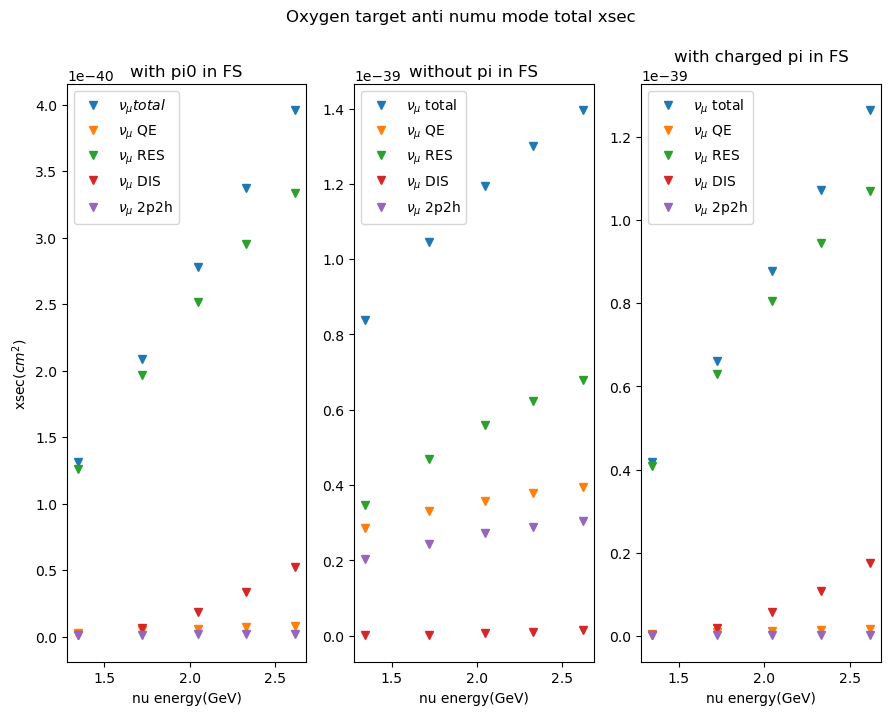

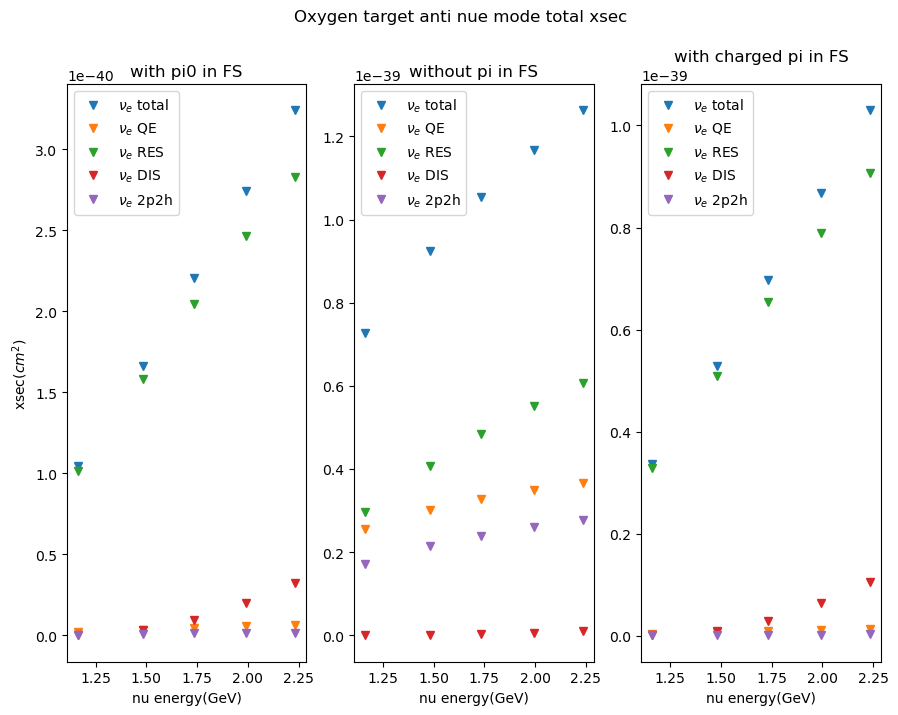

In [27]:
#total xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Oxygen target anti numu mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax2.legend()
ax3.legend()

plt.show()


#total xsec
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.suptitle('Oxygen target anti nue mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi0 in FS')
ax2.set_title('without pi in FS')
ax3.set_title('with charged pi in FS')
ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')
ax3.set(xlabel='nu energy(GeV)')

ax1.legend()
ax2.legend()
ax3.legend()

plt.show()


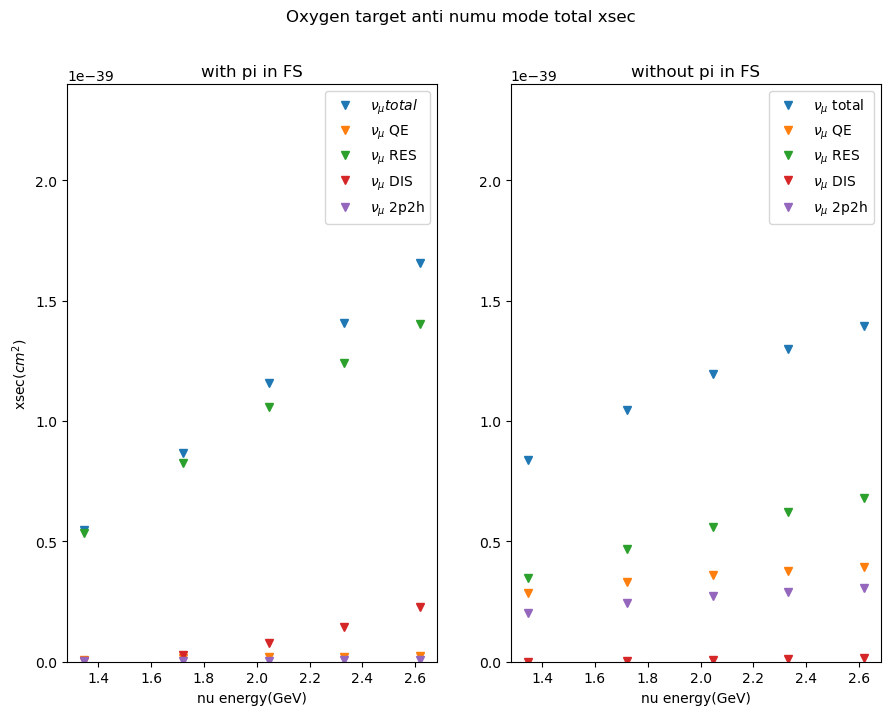

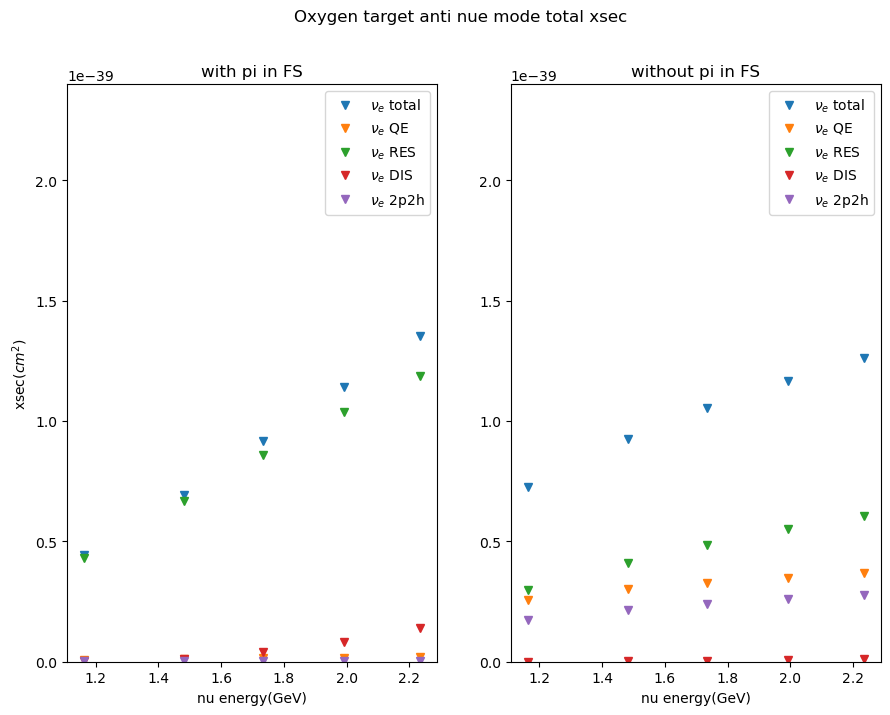

In [29]:
#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Oxygen target anti numu mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_xsec_lst+Oxygen_anti_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_xsec


ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_QE_xsec_lst+Oxygen_anti_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_xsec

ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_RES_xsec_lst+Oxygen_anti_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_xsec

ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_DIS_xsec_lst+Oxygen_anti_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_2p2h_xsec_lst+Oxygen_anti_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,2.4e-39)
ax2.legend()
ax2.set_ylim(0,2.4e-39)


plt.show()


#total xsec
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Oxygen target anti nue mode total xsec')

plt.xlabel('pion energy')
#plt.ylabel('xsec($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_xsec_lst+Oxygen_anti_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_xsec

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_QE_xsec_lst+Oxygen_anti_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_QE_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_xsec

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_RES_xsec_lst+Oxygen_anti_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_RES_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_xsec

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_DIS_xsec_lst+Oxygen_anti_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_DIS_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_xsec

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_2p2h_xsec_lst+Oxygen_anti_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_2p2h_xsec_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='xsec($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
ax1.set_ylim(0,2.4e-39)
ax2.legend()
ax2.set_ylim(0,2.4e-39)


plt.show()

In [5]:
1/(1.67e-27)

5.988023952095808e+26

In [7]:
365*24*3600

31536000

In [8]:
'''
evnet num in 5 year
unit in event/POT detector mass in kg
'''



pi_E_lst = np.array([3,4,5,6,7])
musig_numu_E_lst = np.array([1.34543,1.72122,2.04772,2.32939,2.61806])
musig_nue_E_lst = np.array([1.1625,1.48087,1.73456,1.9923,2.23415])
zero_line = np.array([0,0,0,0,0])


Carbon_nu_e_charged_pi_event_num_lst = np.array([2.74156e-22, 5.25032e-20, 5.6716e-19, 1.6214e-18, 2.85627e-18])
Carbon_nu_e_charged_pi_QE_event_num_lst = np.array([4.28556e-24, 8.00917e-22, 8.10123e-21, 2.15803e-20, 3.57275e-20])
Carbon_nu_e_charged_pi_RES_event_num_lst = np.array([2.67597e-22, 5.04658e-20, 5.31632e-19, 1.47396e-18, 2.51786e-18])
Carbon_nu_e_charged_pi_DIS_event_num_lst = np.array([1.55386e-24, 1.09522e-21, 2.5953e-20, 1.21835e-19, 2.95936e-19])
Carbon_nu_e_charged_pi_2p2h_event_num_lst = np.array([7.19397e-25, 1.4133e-22, 1.47422e-21, 4.02035e-21, 6.74724e-21])

Carbon_nu_e_outana7_event_num_lst = np.array([9.46613e-23, 1.84042e-20, 2.00136e-19, 5.73595e-19, 1.0106e-18])
Carbon_nu_e_outana7_QE_event_num_lst = np.array([2.33847e-24, 4.32744e-22, 4.36548e-21, 1.16587e-20, 1.92398e-20])
Carbon_nu_e_outana7_RES_event_num_lst = np.array([9.12527e-23, 1.74697e-20, 1.85373e-19, 5.16019e-19, 8.83698e-19])
Carbon_nu_e_outana7_DIS_event_num_lst = np.array([6.09416e-25, 4.13202e-22, 9.48313e-21, 4.34457e-20, 1.03537e-19])
Carbon_nu_e_outana7_2p2h_event_num_lst = np.array([4.60733e-25, 8.86125e-23, 9.13944e-22, 2.47136e-21, 4.1289e-21]) 

Carbon_nu_e_outana9_event_num_lst = np.array([5.89837e-22, 9.15347e-20, 8.67819e-19, 2.23407e-18, 3.61871e-18])
Carbon_nu_e_outana9_QE_event_num_lst = np.array([3.3478e-22, 5.04599e-20, 4.70925e-19, 1.19617e-18, 1.91661e-18])
Carbon_nu_e_outana9_RES_event_num_lst = np.array([1.2405e-22, 2.13083e-20, 2.11675e-19, 5.63082e-19, 9.33547e-19])
Carbon_nu_e_outana9_DIS_event_num_lst = np.array([1.79291e-25, 1.22256e-22, 2.80525e-21, 1.27903e-20, 3.02429e-20])
Carbon_nu_e_outana9_2p2h_event_num_lst = np.array([1.30828e-22, 1.96443e-20, 1.82414e-19, 4.62026e-19, 7.38301e-19])

Carbon_nu_mu_charged_pi_event_num_lst = np.array([2.88362e-22, 5.96384e-20, 6.29555e-19, 1.83944e-18, 3.13831e-18])
Carbon_nu_mu_charged_pi_QE_event_num_lst = np.array([4.6165e-24, 8.75514e-22, 8.47645e-21, 2.29741e-20, 3.65735e-20])
Carbon_nu_mu_charged_pi_RES_event_num_lst = np.array([2.80947e-22, 5.66749e-20, 5.76326e-19, 1.62112e-18, 2.65812e-18])
Carbon_nu_mu_charged_pi_DIS_event_num_lst = np.array([1.96433e-24, 1.92239e-21, 4.31246e-20, 1.90897e-19, 4.36489e-19])
Carbon_nu_mu_charged_pi_2p2h_event_num_lst = np.array([8.33731e-25, 1.65559e-22, 1.62785e-21, 4.45277e-21, 7.12379e-21])

Carbon_nu_mu_outana7_event_num_lst = np.array([1.00187e-22, 2.10109e-20, 2.2275e-19, 6.51259e-19, 1.10913e-18])
Carbon_nu_mu_outana7_QE_event_num_lst = np.array([2.50624e-24, 4.71804e-22, 4.51773e-21, 1.21531e-20, 1.93168e-20])
Carbon_nu_mu_outana7_RES_event_num_lst = np.array([9.63862e-23, 1.97168e-20, 2.0161e-19, 5.68872e-19, 9.34359e-19])
Carbon_nu_mu_outana7_DIS_event_num_lst = np.array([7.71971e-25, 7.20119e-22, 1.56244e-20, 6.7518e-20, 1.51125e-19])
Carbon_nu_mu_outana7_2p2h_event_num_lst = np.array([5.22984e-25, 1.0218e-22, 9.98109e-22, 2.71537e-21, 4.32909e-21])

Carbon_nu_mu_outana9_event_num_lst = np.array([5.58531e-22, 9.33333e-20, 8.58961e-19, 2.27566e-18, 3.57786e-18])
Carbon_nu_mu_outana9_QE_event_num_lst = np.array([3.11441e-22, 5.06771e-20, 4.58367e-19, 1.20012e-18, 1.86792e-18])
Carbon_nu_mu_outana9_RES_event_num_lst = np.array([1.23077e-22, 2.25276e-20, 2.17081e-19, 5.89363e-19, 9.42977e-19])
Carbon_nu_mu_outana9_DIS_event_num_lst = np.array([2.36085e-25, 2.2053e-22, 4.74465e-21, 2.0248e-20, 4.46214e-20])
Carbon_nu_mu_outana9_2p2h_event_num_lst = np.array([1.23776e-22, 1.9908e-20, 1.78769e-19, 4.65927e-19, 7.22339e-19])




Carbon_anti_nu_e_charged_pi_event_num_lst = np.array([4.23167e-23, 9.86577e-21, 1.22073e-19, 3.86698e-19, 7.37043e-19]) 
Carbon_anti_nu_e_charged_pi_QE_event_num_lst = np.array([5.17799e-25, 1.27496e-22, 1.60065e-21, 5.01498e-21, 9.3782e-21]) 
Carbon_anti_nu_e_charged_pi_RES_event_num_lst = np.array([4.15033e-23, 9.54405e-21, 1.1526e-19, 3.54159e-19, 6.54393e-19]) 
Carbon_anti_nu_e_charged_pi_DIS_event_num_lst = np.array([1.82945e-25, 1.66156e-22, 4.86421e-21, 2.64414e-20, 7.12624e-20]) 
Carbon_anti_nu_e_charged_pi_2p2h_event_num_lst = np.array([1.12685e-25, 2.80633e-23, 3.48257e-22, 1.08181e-21, 2.00906e-21]) 

Carbon_anti_nu_e_outana7_event_num_lst = np.array([1.25148e-23, 2.94702e-21, 3.6544e-20, 1.15576e-19, 2.19475e-19])
Carbon_anti_nu_e_outana7_QE_event_num_lst = np.array([2.43083e-25, 5.97027e-23, 7.37093e-22, 2.2968e-21, 4.28145e-21])
Carbon_anti_nu_e_outana7_RES_event_num_lst = np.array([1.21392e-23, 2.81553e-21, 3.40797e-20, 1.04712e-19, 1.93327e-19])
Carbon_anti_nu_e_outana7_DIS_event_num_lst = np.array([6.39388e-26, 5.49013e-23, 1.51952e-21, 7.92515e-21, 2.06792e-20])
Carbon_anti_nu_e_outana7_2p2h_event_num_lst = np.array([6.86371e-26, 1.68814e-23, 2.07765e-22, 6.41887e-22, 1.18681e-21])

Carbon_anti_nu_e_outana9_event_num_lst = np.array([7.88613e-23, 1.49235e-20, 1.59557e-19, 4.50184e-19, 7.82386e-19])
Carbon_anti_nu_e_outana9_QE_event_num_lst = np.array([2.7937e-23, 4.89295e-21, 4.99e-20, 1.35851e-19, 2.29661e-19])
Carbon_anti_nu_e_outana9_RES_event_num_lst = np.array([3.05121e-23, 6.21382e-21, 6.92273e-20, 2.00832e-19, 3.55889e-19])
Carbon_anti_nu_e_outana9_DIS_event_num_lst = np.array([1.95759e-26, 1.56862e-23, 4.16123e-22, 2.11533e-21, 5.45144e-21])
Carbon_anti_nu_e_outana9_2p2h_event_num_lst = np.array([2.03926e-23, 3.80104e-21, 4.00135e-20, 1.11385e-19, 1.91385e-19])

Carbon_anti_nu_mu_charged_pi_event_num_lst = np.array([4.83464e-23, 1.24715e-20, 1.50566e-19, 4.8333e-19, 8.8925e-19]) 
Carbon_anti_nu_mu_charged_pi_QE_event_num_lst = np.array([6.36279e-25, 1.68997e-22, 2.00081e-21, 6.23049e-21, 1.10963e-20]) 
Carbon_anti_nu_mu_charged_pi_RES_event_num_lst = np.array([4.72928e-23, 1.19214e-20, 1.38906e-19, 4.29726e-19, 7.59901e-19]) 
Carbon_anti_nu_mu_charged_pi_DIS_event_num_lst = np.array([2.73522e-25, 3.43544e-22, 9.21953e-21, 4.6013e-20, 1.15854e-19]) 
Carbon_anti_nu_mu_charged_pi_2p2h_event_num_lst = np.array([1.43759e-25, 3.76144e-23, 4.39983e-22, 1.36058e-21, 2.39888e-21]) 

Carbon_anti_nu_mu_outana7_event_num_lst = np.array([1.43676e-23, 3.73139e-21, 4.50321e-20, 1.44007e-19, 2.63327e-19])
Carbon_anti_nu_mu_outana7_QE_event_num_lst = np.array([3.00164e-25, 7.66337e-23, 9.10809e-22, 2.85458e-21, 5.10373e-21])
Carbon_anti_nu_mu_outana7_RES_event_num_lst = np.array([1.38851e-23, 3.52145e-21, 4.10528e-20, 1.26898e-19, 2.24102e-19])
Carbon_anti_nu_mu_outana7_DIS_event_num_lst = np.array([9.58098e-26, 1.10951e-22, 2.80926e-21, 1.34563e-20, 3.27177e-20])
Carbon_anti_nu_mu_outana7_2p2h_event_num_lst = np.array([8.65629e-26, 2.23595e-23, 2.59302e-22, 7.98022e-22, 1.40311e-21])

Carbon_anti_nu_mu_outana9_event_num_lst = np.array([8.33949e-23, 1.70283e-20, 1.76758e-19, 5.07871e-19, 8.50862e-19])
Carbon_anti_nu_mu_outana9_QE_event_num_lst = np.array([2.84621e-23, 5.37976e-21, 5.33522e-20, 1.48554e-19, 2.42817e-19])
Carbon_anti_nu_mu_outana9_RES_event_num_lst = np.array([3.2767e-23, 7.23604e-21, 7.81526e-20, 2.30033e-19, 3.91794e-19])
Carbon_anti_nu_mu_outana9_DIS_event_num_lst = np.array([2.9735e-26, 3.20855e-23, 7.79457e-22, 3.65244e-21, 8.76738e-21])
Carbon_anti_nu_mu_outana9_2p2h_event_num_lst = np.array([2.21361e-23, 4.38037e-21, 4.44736e-20, 1.25632e-19, 2.07483e-19])




Oxygen_nu_e_charged_pi_event_num_lst = np.array([1.96702e-22, 3.78693e-20, 4.10833e-19, 1.17873e-18, 2.08245e-18]) 
Oxygen_nu_e_charged_pi_QE_event_num_lst =np.array([3.26939e-24, 6.11728e-22, 6.23422e-21, 1.67146e-20, 2.77487e-20])
Oxygen_nu_e_charged_pi_RES_event_num_lst = np.array([1.91646e-22, 3.62984e-20, 3.83417e-19, 1.065e-18, 1.82162e-18]) 
Oxygen_nu_e_charged_pi_DIS_event_num_lst = np.array([1.19948e-24, 8.44262e-22, 1.99837e-20, 9.37484e-20, 2.27615e-19]) 
Oxygen_nu_e_charged_pi_2p2h_event_num_lst = np.array([5.86872e-25, 1.14941e-22, 1.19804e-21, 3.26105e-21, 5.46983e-21]) 

Oxygen_nu_e_outana7_event_num_lst = np.array([6.80275e-23, 1.33012e-20, 1.45281e-19, 4.17909e-19, 7.38481e-19]) 
Oxygen_nu_e_outana7_QE_event_num_lst = np.array([1.8665e-24, 3.44176e-22, 3.46268e-21, 9.2277e-21, 1.52738e-20])
Oxygen_nu_e_outana7_RES_event_num_lst = np.array([6.53207e-23, 1.25652e-20, 1.33717e-19, 3.72956e-19, 6.39536e-19])
Oxygen_nu_e_outana7_DIS_event_num_lst = np.array([4.72028e-25, 3.20892e-22, 7.36948e-21, 3.37449e-20, 8.0362e-20])
Oxygen_nu_e_outana7_2p2h_event_num_lst = np.array([3.68349e-25, 7.09881e-23, 7.32199e-22, 1.98046e-21, 3.3093e-21])

Oxygen_nu_e_outana9_event_num_lst = np.array([4.56045e-22, 7.10838e-20, 6.75647e-19, 1.74357e-18, 2.82927e-18]) 
Oxygen_nu_e_outana9_QE_event_num_lst = np.array([2.50107e-22, 3.76383e-20, 3.50959e-19, 8.91597e-19, 1.42855e-18])
Oxygen_nu_e_outana9_RES_event_num_lst = np.array([1.08161e-22, 1.86725e-20, 1.85962e-19, 4.95451e-19, 8.22239e-19])
Oxygen_nu_e_outana9_DIS_event_num_lst = np.array([1.746e-25, 1.15279e-22, 2.59636e-21, 1.17011e-20, 2.74631e-20])
Oxygen_nu_e_outana9_2p2h_event_num_lst = np.array([9.76027e-23, 1.46577e-20, 1.3613e-19, 3.44818e-19, 5.51023e-19])

Oxygen_nu_mu_charged_pi_event_num_lst = np.array([2.07593e-22, 4.31802e-20, 4.57862e-19, 1.34224e-18, 2.29641e-18]) 
Oxygen_nu_mu_charged_pi_QE_event_num_lst = np.array([3.57783e-24, 6.84483e-22, 6.64042e-21, 1.79938e-20, 2.86152e-20]) 
Oxygen_nu_mu_charged_pi_RES_event_num_lst = np.array([2.0183e-22, 4.0883e-20, 4.16744e-19, 1.17393e-18, 1.9266e-18]) 
Oxygen_nu_mu_charged_pi_DIS_event_num_lst = np.array([1.51067e-24, 1.47882e-21, 3.31611e-20, 1.46714e-19, 3.3544e-19]) 
Oxygen_nu_mu_charged_pi_2p2h_event_num_lst = np.array([6.74786e-25, 1.33889e-22, 1.31706e-21, 3.60206e-21, 5.76241e-21])

Oxygen_nu_mu_outana7_event_num_lst = np.array([7.22272e-23, 1.52465e-20, 1.62396e-19, 4.76416e-19, 8.13486e-19]) 
Oxygen_nu_mu_outana7_QE_event_num_lst = np.array([2.02243e-24, 3.77149e-22, 3.63103e-21, 9.80121e-21, 1.55473e-20])
Oxygen_nu_mu_outana7_RES_event_num_lst = np.array([6.91828e-23, 1.42271e-20, 1.45833e-19, 4.12102e-19, 6.77461e-19])
Oxygen_nu_mu_outana7_DIS_event_num_lst = np.array([6.01835e-25, 5.60489e-22, 1.21345e-20, 5.23427e-20, 1.17019e-19])
Oxygen_nu_mu_outana7_2p2h_event_num_lst = np.array([4.20206e-25, 8.18111e-23, 7.97571e-22, 2.16973e-21, 3.45906e-21])

Oxygen_nu_mu_outana9_event_num_lst = np.array([4.32548e-22, 7.26345e-20, 6.7045e-19, 1.77981e-18, 2.80199e-18]) 
Oxygen_nu_mu_outana9_QE_event_num_lst = np.array([2.3212e-22, 3.77687e-20, 3.41548e-19, 8.94255e-19, 1.39111e-18])
Oxygen_nu_mu_outana9_RES_event_num_lst = np.array([1.07725e-22, 1.97927e-20, 1.91079e-19, 5.19324e-19, 8.31472e-19])
Oxygen_nu_mu_outana9_DIS_event_num_lst = np.array([2.27117e-25, 2.04322e-22, 4.33067e-21, 1.83224e-20, 4.01288e-20])
Oxygen_nu_mu_outana9_2p2h_event_num_lst = np.array([9.24759e-23, 1.48688e-20, 1.33493e-19, 3.47904e-19, 5.39278e-19])




Oxygen_anti_nu_e_charged_pi_event_num_lst = np.array([3.13699e-23, 7.34825e-21, 9.13385e-20, 2.90551e-19, 5.55677e-19]) 
Oxygen_anti_nu_e_charged_pi_QE_event_num_lst = np.array([4.14205e-25, 1.01146e-22, 1.25302e-21, 3.91137e-21, 7.29831e-21]) 
Oxygen_anti_nu_e_charged_pi_RES_event_num_lst = np.array([3.07161e-23, 7.09014e-21, 8.5874e-20, 2.64428e-19, 4.89332e-19]) 
Oxygen_anti_nu_e_charged_pi_DIS_event_num_lst = np.array([1.47065e-25, 1.33947e-22, 3.92572e-21, 2.13246e-20, 5.74014e-20]) 
Oxygen_anti_nu_e_charged_pi_2p2h_event_num_lst = np.array([9.24653e-26, 2.30228e-23, 2.85702e-22, 8.86908e-22, 1.64537e-21]) 

Oxygen_anti_nu_e_outana7_event_num_lst = np.array([9.76264e-24, 2.31538e-21, 2.88829e-20, 9.17726e-20, 1.74893e-19]) 
Oxygen_anti_nu_e_outana7_QE_event_num_lst = np.array([2.01435e-25, 4.94467e-23, 6.11149e-22, 1.8943e-21, 3.52455e-21]) 
Oxygen_anti_nu_e_outana7_RES_event_num_lst = np.array([9.45177e-24, 2.2059e-21, 2.6815e-20, 8.2635e-20, 1.52863e-19] ) 
Oxygen_anti_nu_e_outana7_DIS_event_num_lst = np.array([5.3702e-26, 4.63711e-23, 1.28853e-21, 6.72344e-21, 1.75441e-20])
Oxygen_anti_nu_e_outana7_2p2h_event_num_lst = np.array([5.57385e-26, 1.36674e-23, 1.68203e-22, 5.19858e-22, 9.6154e-22] ) 

Oxygen_anti_nu_e_outana9_event_num_lst = np.array([6.7681e-23, 1.28829e-20, 1.38297e-19, 3.91327e-19, 6.81599e-19]) 
Oxygen_anti_nu_e_outana9_QE_event_num_lst = np.array([2.39293e-23, 4.20419e-21, 4.29598e-20, 1.17099e-19, 1.98214e-19]) 
Oxygen_anti_nu_e_outana9_RES_event_num_lst = np.array([2.7756e-23, 5.68445e-21, 6.35599e-20, 1.8483e-19, 3.28025e-19]) 
Oxygen_anti_nu_e_outana9_DIS_event_num_lst = np.array([1.94067e-26, 1.53878e-23, 4.04379e-22, 2.0421e-21, 5.23109e-21])
Oxygen_anti_nu_e_outana9_2p2h_event_num_lst = np.array([1.59763e-23, 2.97888e-21, 3.13733e-20, 8.73558e-20, 1.50129e-19])

Oxygen_anti_nu_mu_charged_pi_event_num_lst = np.array([3.58445e-23, 9.31289e-21, 1.1305e-19, 3.64441e-19, 6.72912e-19]) 
Oxygen_anti_nu_mu_charged_pi_QE_event_num_lst = np.array([4.89093e-25, 1.3193e-22, 1.57291e-21, 4.90456e-21, 8.70805e-21]) 
Oxygen_anti_nu_mu_charged_pi_RES_event_num_lst = np.array([3.50192e-23, 8.87357e-21, 1.03696e-19, 3.21413e-19, 5.69172e-19]) 
Oxygen_anti_nu_mu_charged_pi_DIS_event_num_lst = np.array([2.18926e-25, 2.76628e-22, 7.42248e-21, 3.70126e-20, 9.30748e-20]) 
Oxygen_anti_nu_mu_charged_pi_2p2h_event_num_lst = np.array([1.17303e-25, 3.07627e-23, 3.59536e-22, 1.1109e-21, 1.95712e-21]) 

Oxygen_anti_nu_mu_outana7_event_num_lst = np.array([1.12477e-23, 2.94817e-21, 3.57766e-20, 1.14877e-19, 2.10759e-19]) 
Oxygen_anti_nu_mu_outana7_QE_event_num_lst = np.array([2.50072e-25, 6.51981e-23, 7.65751e-22, 2.37208e-21, 4.19529e-21]) 
Oxygen_anti_nu_mu_outana7_RES_event_num_lst = np.array([1.0847e-23, 2.77081e-21, 3.24126e-20, 1.00414e-19, 1.77608e-19]) 
Oxygen_anti_nu_mu_outana7_DIS_event_num_lst = np.array([8.04424e-26, 9.40353e-23, 2.38761e-21, 1.1443e-20, 2.78165e-20]) 
Oxygen_anti_nu_mu_outana7_2p2h_event_num_lst = np.array([7.01719e-26, 1.81314e-23, 2.10567e-22, 6.48259e-22, 1.13847e-21]) 

Oxygen_anti_nu_mu_outana9_event_num_lst = np.array([7.18906e-23, 1.47574e-20, 1.53736e-19, 4.42852e-19, 7.43211e-19]) 
Oxygen_anti_nu_mu_outana9_QE_event_num_lst = np.array([2.4613e-23, 4.65206e-21, 4.61663e-20, 1.28628e-19, 2.10194e-19]) 
Oxygen_anti_nu_mu_outana9_RES_event_num_lst = np.array([2.98789e-23, 6.63649e-21, 7.19051e-20, 2.12086e-19, 3.61754e-19]) 
Oxygen_anti_nu_mu_outana9_DIS_event_num_lst = np.array([3.0259e-26, 3.16345e-23, 7.56768e-22, 3.51776e-21, 8.39519e-21]) 
Oxygen_anti_nu_mu_outana9_2p2h_event_num_lst = np.array([1.73685e-23, 3.43726e-21, 3.49081e-20, 9.862e-20, 1.62867e-19]) 



'''
Argon_nu_e_charged_pi_event_num_lst = np.array([2.11184e-39, 2.7203e-39, 3.13374e-39, 3.51974e-39, 3.85706e-39]) 
Argon_nu_e_charged_pi_QE_event_num_lst =np.array([3.51011e-41, 4.39428e-41, 4.75531e-41, 4.99106e-41, 5.13954e-41])
Argon_nu_e_charged_pi_RES_event_num_lst = np.array([2.05756e-39, 2.60746e-39, 2.92461e-39, 3.18015e-39, 3.37395e-39]) 
Argon_nu_e_charged_pi_DIS_event_num_lst = np.array([1.2878e-41, 6.06467e-41, 1.52431e-40, 2.79937e-40, 4.21582e-40]) 
Argon_nu_e_charged_pi_2p2h_event_num_lst = np.array([6.30082e-42, 8.25665e-42, 9.13835e-42, 9.73766e-42, 1.01311e-41]) 

Argon_nu_e_outana7_event_num_lst = np.array([7.30363e-40, 9.5548e-40, 1.10817e-39, 1.24789e-39, 1.36779e-39]) 
Argon_nu_e_outana7_QE_event_num_lst = np.array([2.00393e-41, 2.47235e-41, 2.64124e-41, 2.75543e-41, 2.82897e-41])
Argon_nu_e_outana7_RES_event_num_lst = np.array([7.01301e-40, 9.02606e-40, 1.01996e-39, 1.11366e-39, 1.18453e-39])
Argon_nu_e_outana7_DIS_event_num_lst = np.array([5.06783e-42, 2.3051e-41, 5.62126e-41, 1.00764e-40, 1.48844e-40])
Argon_nu_e_outana7_2p2h_event_num_lst = np.array([3.95469e-42, 5.09936e-42, 5.58503e-42, 5.91373e-42, 6.12939e-42])

Argon_nu_e_outana9_event_num_lst = np.array([4.89622e-39, 5.10623e-39, 5.15367e-39, 5.20638e-39, 5.2403e-39]) 
Argon_nu_e_outana9_QE_event_num_lst = np.array([2.68522e-39, 2.70371e-39, 2.67703e-39, 2.66235e-39, 2.64591e-39])
Argon_nu_e_outana9_RES_event_num_lst = np.array([1.16124e-39, 1.34132e-39, 1.41847e-39, 1.47944e-39, 1.52293e-39])
Argon_nu_e_outana9_DIS_event_num_lst = np.array([1.87455e-42, 8.28096e-42, 1.98044e-41, 3.49401e-41, 5.08664e-41])
Argon_nu_e_outana9_2p2h_event_num_lst = np.array([1.04789e-39, 1.05292e-39, 1.03837e-39, 1.02964e-39, 1.02059e-39])

Argon_nu_mu_charged_pi_event_num_lst = np.array([2.41715e-39, 3.06018e-39, 3.55758e-39, 3.9443e-39, 4.31004e-39]) 
Argon_nu_mu_charged_pi_QE_event_num_lst = np.array([4.16592e-41, 4.85093e-41, 5.15959e-41, 5.28766e-41, 5.37066e-41]) 
Argon_nu_mu_charged_pi_RES_event_num_lst = np.array([2.35005e-39, 2.89738e-39, 3.23809e-39, 3.4497e-39, 3.61595e-39]) 
Argon_nu_mu_charged_pi_DIS_event_num_lst = np.array([1.75897e-41, 1.04804e-40, 2.57661e-40, 4.31134e-40, 6.29573e-40]) 
Argon_nu_mu_charged_pi_2p2h_event_num_lst = np.array([7.857e-42, 9.48868e-42, 1.02335e-41, 1.0585e-41, 1.08152e-41])

Argon_nu_mu_outana7_event_num_lst = np.array([8.40991e-40, 1.08052e-39, 1.26182e-39, 1.4e-39, 1.5268e-39]) 
Argon_nu_mu_outana7_QE_event_num_lst = np.array([2.35485e-41, 2.67286e-41, 2.8213e-41, 2.88018e-41, 2.91801e-41])
Argon_nu_mu_outana7_RES_event_num_lst = np.array([8.05542e-40, 1.00827e-39, 1.13312e-39, 1.211e-39, 1.2715e-39])
Argon_nu_mu_outana7_DIS_event_num_lst = np.array([7.00757e-42, 3.97218e-41, 9.42846e-41, 1.53814e-40, 2.19628e-40])
Argon_nu_mu_outana7_2p2h_event_num_lst = np.array([4.89275e-42, 5.79795e-42, 6.19711e-42, 6.37597e-42, 6.49216e-42])

Argon_nu_mu_outana9_event_num_lst = np.array([5.03645e-39, 5.14761e-39, 5.20938e-39, 5.23014e-39, 5.25894e-39]) 
Argon_nu_mu_outana9_QE_event_num_lst = np.array([2.70273e-39, 2.67667e-39, 2.65382e-39, 2.62786e-39, 2.61092e-39])
Argon_nu_mu_outana9_RES_event_num_lst = np.array([1.25431e-39, 1.40271e-39, 1.48468e-39, 1.52609e-39, 1.56055e-39])
Argon_nu_mu_outana9_DIS_event_num_lst = np.array([2.64447e-42, 1.44803e-41, 3.36492e-41, 5.38423e-41, 7.5316e-41])
Argon_nu_mu_outana9_2p2h_event_num_lst = np.array([1.07676e-39, 1.05375e-39, 1.03723e-39, 1.02235e-39, 1.01215e-39])




Argon_anti_nu_e_charged_pi_event_num_lst = np.array([3.36796e-40, 5.27854e-40, 6.96707e-40, 8.67599e-40, 1.02921e-39]) 
Argon_anti_nu_e_charged_pi_QE_event_num_lst = np.array([4.44702e-42, 7.26569e-42, 9.55774e-42, 1.16795e-41, 1.35177e-41]) 
Argon_anti_nu_e_charged_pi_RES_event_num_lst = np.array([3.29777e-40, 5.09313e-40, 6.55026e-40, 7.89595e-40, 9.06328e-40]) 
Argon_anti_nu_e_charged_pi_DIS_event_num_lst = np.array([1.57893e-42, 9.62193e-42, 2.99444e-41, 6.36762e-41, 1.06317e-40]) 
Argon_anti_nu_e_charged_pi_2p2h_event_num_lst = np.array([9.92733e-43, 1.65382e-42, 2.17927e-42, 2.64835e-42, 3.04751e-42]) 

Argon_anti_nu_e_outana7_event_num_lst = np.array([1.04814e-40, 1.66323e-40, 2.20311e-40, 2.74037e-40, 3.23933e-40]) 
Argon_anti_nu_e_outana7_QE_event_num_lst = np.array([2.16267e-42, 3.55195e-42, 4.6617e-42, 5.65646e-42, 6.52808e-42]) 
Argon_anti_nu_e_outana7_RES_event_num_lst = np.array([1.01477e-40, 1.58458e-40, 2.04538e-40, 2.46752e-40, 2.83129e-40]) 
Argon_anti_nu_e_outana7_DIS_event_num_lst = np.array([5.7656e-43, 3.33102e-42, 9.82856e-42, 2.00765e-41, 3.24946e-41])
Argon_anti_nu_e_outana7_2p2h_event_num_lst = np.array([5.98424e-43, 9.81782e-43, 1.28301e-42, 1.55232e-42, 1.78094e-42]) 

Argon_anti_nu_e_outana9_event_num_lst = np.array([7.26642e-40, 9.25431e-40, 1.0549e-39, 1.16852e-39, 1.26244e-39]) 
Argon_anti_nu_e_outana9_QE_event_num_lst = np.array([2.56912e-40, 3.02004e-40, 3.27686e-40, 3.49663e-40, 3.67127e-40]) 
Argon_anti_nu_e_outana9_RES_event_num_lst = np.array([2.97997e-40, 4.08337e-40, 4.84819e-40, 5.5191e-40, 6.07559e-40]) 
Argon_anti_nu_e_outana9_DIS_event_num_lst = np.array([2.08356e-43, 1.10537e-42, 3.0845e-42, 6.09781e-42, 9.68889e-42])
Argon_anti_nu_e_outana9_2p2h_event_num_lst = np.array([1.71526e-40, 2.13985e-40, 2.39307e-40, 2.60848e-40, 2.78064e-40])

Argon_anti_nu_mu_charged_pi_event_num_lst = np.array([4.17362e-40, 6.60004e-40, 8.784e-40, 1.07095e-39, 1.26296e-39]) 
Argon_anti_nu_mu_charged_pi_QE_event_num_lst = np.array([5.69484e-42, 9.34986e-42, 1.22215e-41, 1.44125e-41, 1.63438e-41]) 
Argon_anti_nu_mu_charged_pi_RES_event_num_lst = np.array([4.07752e-40, 6.28869e-40, 8.05712e-40, 9.44505e-40, 1.06825e-39]) 
Argon_anti_nu_mu_charged_pi_DIS_event_num_lst = np.array([2.54911e-42, 1.96046e-41, 5.76725e-41, 1.08765e-40, 1.74688e-40]) 
Argon_anti_nu_mu_charged_pi_2p2h_event_num_lst = np.array([1.36583e-42, 2.18015e-42, 2.79359e-42, 3.26449e-42, 3.67324e-42]) 

Argon_anti_nu_mu_outana7_event_num_lst = np.array([1.30965e-40, 2.08937e-40, 2.77983e-40, 3.37578e-40, 3.95564e-40]) 
Argon_anti_nu_mu_outana7_QE_event_num_lst = np.array([2.91176e-42, 4.62059e-42, 5.94987e-42, 6.97059e-42, 7.87397e-42]) 
Argon_anti_nu_mu_outana7_RES_event_num_lst = np.array([1.26299e-40, 1.96367e-40, 2.51845e-40, 2.95077e-40, 3.33346e-40]) 
Argon_anti_nu_mu_outana7_DIS_event_num_lst = np.array([9.36646e-43, 6.66428e-42, 1.85517e-41, 3.36263e-41, 5.22075e-41]) 
Argon_anti_nu_mu_outana7_2p2h_event_num_lst = np.array([8.1706e-43, 1.28497e-42, 1.6361e-42, 1.90497e-42, 2.13676e-42]) 

Argon_anti_nu_mu_outana9_event_num_lst = np.array([8.37072e-40, 1.04586e-39, 1.19453e-39, 1.30137e-39, 1.3949e-39]) 
Argon_anti_nu_mu_outana9_QE_event_num_lst = np.array([2.86586e-40, 3.29691e-40, 3.58711e-40, 3.77988e-40, 3.94504e-40]) 
Argon_anti_nu_mu_outana9_RES_event_num_lst = np.array([3.479e-40, 4.70328e-40, 5.58701e-40, 6.23237e-40, 6.78962e-40]) 
Argon_anti_nu_mu_outana9_DIS_event_num_lst = np.array([3.52326e-43, 2.24194e-42, 5.88007e-42, 1.03373e-41, 1.57566e-41]) 
Argon_anti_nu_mu_outana9_2p2h_event_num_lst = np.array([2.02234e-40, 2.43598e-40, 2.71235e-40, 2.89805e-40, 3.05678e-40]) 
'''

a=0
print(a)

0


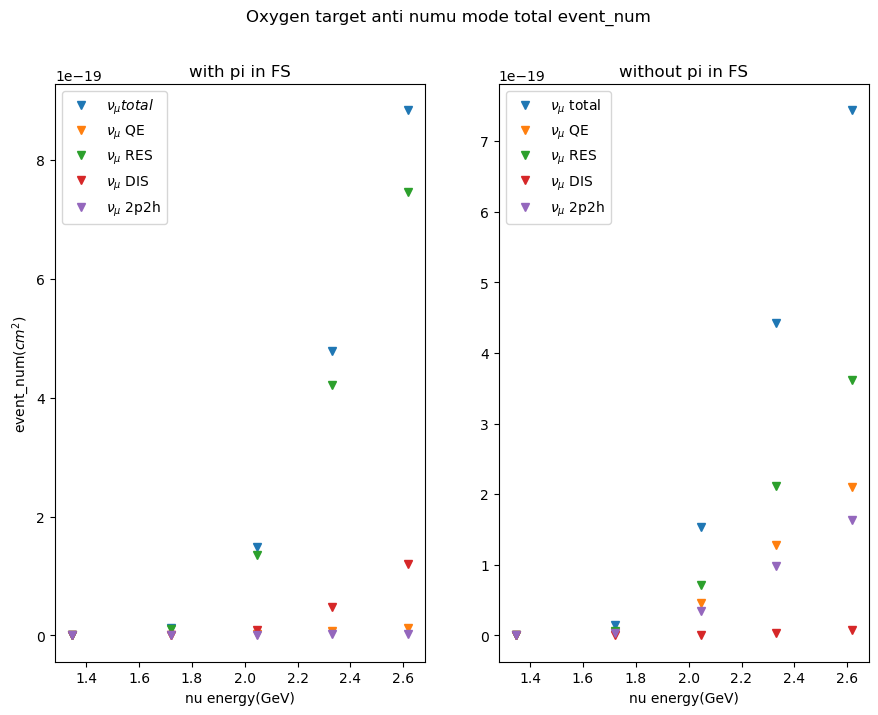

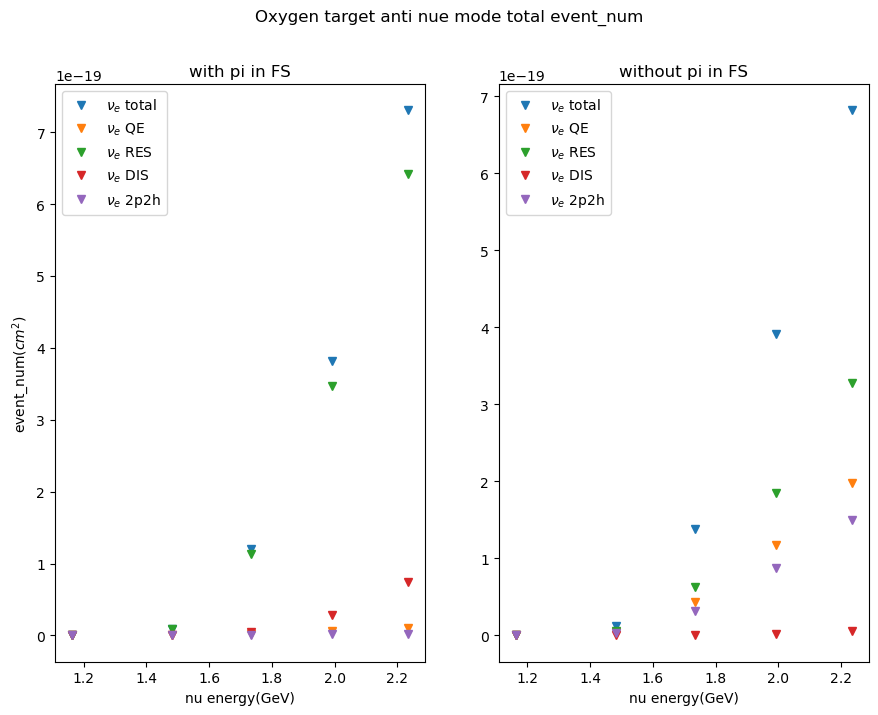

In [10]:
#total event_num
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Oxygen target anti numu mode total event_num')

plt.xlabel('pion energy')
#plt.ylabel('event_num($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)


ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_event_num_lst+Oxygen_anti_nu_mu_charged_pi_event_num_lst, linestyle='None', label = '${\\nu}_{\mu} total$', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ total', marker='v')

#QE_event_num


ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_QE_event_num_lst+Oxygen_anti_nu_mu_charged_pi_QE_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_QE_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_QE_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ QE', marker='v')

#RES_event_num

ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_RES_event_num_lst+Oxygen_anti_nu_mu_charged_pi_RES_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_RES_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_RES_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ RES', marker='v')

#DIS_event_num

ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_DIS_event_num_lst+Oxygen_anti_nu_mu_charged_pi_DIS_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_DIS_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_DIS_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ DIS', marker='v')

#2p2h_event_num

ax1.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana7_2p2h_event_num_lst+Oxygen_anti_nu_mu_charged_pi_2p2h_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
ax2.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_outana9_2p2h_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')
#ax3.plot(musig_numu_E_lst, Oxygen_anti_nu_mu_charged_pi_2p2h_event_num_lst, linestyle='None', label = '${\\nu}_{\mu}$ 2p2h', marker='v')


ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='event_num($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
#ax1.set_ylim(0,2.4e-39)
ax2.legend()
#ax2.set_ylim(0,2.4e-39)


plt.show()


#total event_num
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Oxygen target anti nue mode total event_num')

plt.xlabel('pion energy')
#plt.ylabel('event_num($cm^{2}$)')
fig.set_size_inches(10.5, 7.5)
ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_event_num_lst+Oxygen_anti_nu_e_charged_pi_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ total', marker='v')

#QE_event_num

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_QE_event_num_lst+Oxygen_anti_nu_e_charged_pi_QE_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_QE_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_QE_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ QE', marker='v')
#RES_event_num

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_RES_event_num_lst+Oxygen_anti_nu_e_charged_pi_RES_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_RES_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_RES_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ RES', marker='v')
#DIS_event_num

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_DIS_event_num_lst+Oxygen_anti_nu_e_charged_pi_DIS_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_DIS_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_DIS_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ DIS', marker='v')

#2p2h_event_num

ax1.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana7_2p2h_event_num_lst+Oxygen_anti_nu_e_charged_pi_2p2h_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
ax2.plot(musig_nue_E_lst, Oxygen_anti_nu_e_outana9_2p2h_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')
#ax3.plot(musig_nue_E_lst, Oxygen_anti_nu_e_charged_pi_2p2h_event_num_lst, linestyle='None', label = '${\\nu}_{e}$ 2p2h', marker='v')

ax1.plot(musig_nue_E_lst, zero_line, linestyle='None')
ax2.plot(musig_nue_E_lst, zero_line, linestyle='None')

ax1.set_title('with pi in FS')
ax2.set_title('without pi in FS')

ax1.set(xlabel='nu energy(GeV)', ylabel='event_num($cm^{2}$)')
ax2.set(xlabel='nu energy(GeV)')


ax1.legend()
#ax1.set_ylim(0,2.4e-39)
ax2.legend()
#ax2.set_ylim(0,2.4e-39)


plt.show()

In [11]:
w_lst = np.array([7.39545089e-01, -9.27494391e-02, 5.51358513e-02, -2.79184563e-02, -6.00695425e-04, 4.93489427e-02])
w_sum = 0
for i in range(0,len(w_lst)):
    w_sum = w_sum + w_lst[i]
    
w_lst = w_lst/w_sum
print(np.array2string(w_lst, separator=","))

[ 1.02322177e+00,-1.28326517e-01, 7.62850085e-02,-3.86274924e-02,
 -8.31111781e-04, 6.82783420e-02]


In [ ]:
[1.02322177e+00,-1.28326517e-01, 7.62850085e-02,-3.86274924e-02, -8.31111781e-04, 6.82783420e-02]